# EAViT vs ViT on Indian folk music: performance check, fair comparison, and what EAViT captures

One notebook replacing two: the **performance check** of the architecture variant (self-test, data checks,
leakage, curves, confusion matrices, split ablation) and the **fair EAViT vs ViT comparison** (same split,
same test recordings, several seeds, paired 95% intervals). A new final part asks *what external attention
captures that self-attention does not*, with probes, plots and a verdict generated from the numbers.

**Architecture used here (v5)**: two changes from the previous Proposed model, everything else identical.

| | previous Proposed (v4) | **this notebook (v5)** |
|---|---|---|
| tokens | 8 × 8 = **64** tokens, each 16 mel bins × 16 frames (≈0.37 s) | 4 × 4 = **16** tokens, each 32 mel bins × 32 frames (≈0.74 s) |
| conv stem | 4 × [3×3 conv, stride 2] | 5 × [3×3 conv, stride 2] (32→64→128→160→160), then 1×1 |
| classifier head | dropout 0.1 → **linear** 160 → 10 | **MLP** 160 → 512 → 256 → 10, GELU, dropout 0.3 |
| encoder | width 160 × 8 layers, 4 heads, MLP ×4, mean pooling, stochastic depth 0.1 | same |

EAViT and ViT share this architecture exactly; only the attention inside each block differs (external
attention with 64 shared memory slots vs self-attention). Both are edited in `ARCH` in section 2.

**Run order**: 0 write package → 1 environment → 2 settings → 3 self-test → 4 data → 5 plan + dry run →
6 train → 7 performance → 8 is the difference real → 9 what EAViT captures → 10 (optional) split ablation →
11 report. Sections 0–5 take a few minutes; training at stride 6 ≈ 2.5 h on 2 × T4; the probes ≈ 10 min.
Re-running the notebook skips finished runs and resumes stopped ones.

**Before running**: attach the dataset and choose the GPU T4 × 2 accelerator.

## 0. Write the package
`eavit_folk` (data, models, trainer, unchanged from both notebooks), plus `runs.py` (multi-seed run queue
and per-run test results), `versus.py` (EAViT vs ViT statistics and figures), `analysis.py` (the probes),
`style.py` (figure style), the worker that trains one run per GPU, and the self-test.

In [1]:
import os, pathlib
for d in ["eavit_folk", "eavit_folk/data", "eavit_folk/models", "eavit_folk/engine"]:
    pathlib.Path("/kaggle/working/src", d).mkdir(parents=True, exist_ok=True)
print("package directories ready under /kaggle/working/src")

package directories ready under /kaggle/working/src


In [2]:
%%writefile /kaggle/working/src/eavit_folk/__init__.py
"""EAViT for 15-class Indian folk music classification.

    from eavit_folk import Experiment, run_experiment
    exp = Experiment()
    exp.prep.root = "/kaggle/input/<slug>"
    summary = run_experiment(exp)

Torch is imported lazily, so the cleaning/splitting stage also runs on a CPU-only
kernel or a plain Python environment.
"""
import importlib

from .config import CacheConfig, Experiment, ModelConfig, PrepConfig, TrainConfig

__version__ = "1.0.0"

_LAZY = {
    "run_experiment": "pipeline", "run_prepare": "pipeline", "run_training": "pipeline",
    "compare": "pipeline", "evaluate_checkpoint": "pipeline", "show_environment": "pipeline",
    "prepare": "data.prepare", "load_prepared": "data.prepare",
    "Trainer": "engine.trainer", "build_model": "models.eavit",
}

__all__ = ["Experiment", "PrepConfig", "CacheConfig", "ModelConfig", "TrainConfig", *_LAZY]


def __getattr__(name):
    if name in _LAZY:
        module = importlib.import_module(f".{_LAZY[name]}", __name__)
        value = getattr(module, name)
        globals()[name] = value
        return value
    raise AttributeError(f"module {__name__!r} has no attribute {name!r}")


def __dir__():
    return sorted(__all__)

Writing /kaggle/working/src/eavit_folk/__init__.py


In [3]:
%%writefile /kaggle/working/src/eavit_folk/config.py
"""Typed configuration for every stage. Edit these in a notebook cell instead of
passing a wall of CLI flags."""
from __future__ import annotations

from dataclasses import asdict, dataclass, field
from typing import Optional, Sequence


@dataclass
class PrepConfig:
    """Stage 1: scan, clean, split."""
    root: str = "/kaggle/input/datasets/mishbhaul/pre-processed-indian-folk-music"                      # dataset root; "" = autodetect under /kaggle/input
    out: str = "/kaggle/working/prep"

    # segment decimation. Segments are 3 s with a 0.5 s hop, so consecutive
    # segments overlap by 2.5 s. stride=6 keeps only non-overlapping segments.
    stride: int = 1

    # corruption thresholds
    min_std: float = 1e-3               # below this a segment is constant -> corrupt
    max_abs: float = 1e4                # absurd magnitude -> corrupt
    min_segments_per_song: int = 8      # drop songs left with fewer clean segments

    # class subsetting. 0 = keep every style. Any other value keeps the k styles with
    # the most segments AFTER cleaning and striding, and drops the rest. The criterion
    # is data scarcity, decided before any model is trained, so it cannot be tuned on
    # results - state it in the write-up exactly as it is.
    keep_top_k_classes: int = 10

    # splitting
    group_key: str = "song"             # song | artist | none  ("none" = paper-style, leaky)
    val_size: float = 0.15
    test_size: float = 0.15

    chunk: int = 4096                   # segments per corruption-scan block
    stats_sample: int = 60000           # segments used for the train mean/std
    seed: int = 42


@dataclass
class CacheConfig:
    """Stage 1b: pack the kept segments into one contiguous float16 array.

    Random reads across a 25 GB dataset on /kaggle/input are slow; one sequential
    pass into a compact cache makes every epoch afterwards disk-free."""
    enabled: bool = True
    path: str = "/kaggle/working/cache/segments.f16.npy"
    dtype: str = "float16"
    in_ram: bool = True                 # load the cache fully into RAM if it fits
    ram_budget_gb: float = 8.0          # refuse to load into RAM above this


@dataclass
class ModelConfig:
    """Section III-A of the paper. The defaults are the paper's EAViT exactly; the
    last four fields are switches for the architecture variant, each independent so
    it can be ablated on its own."""
    attention: str = "mea"              # mea = EAViT, mhsa = plain ViT baseline
    dim: int = 32                       # projection dimension
    depth: int = 16                     # transformer layers
    num_heads: int = 8
    mlp_ratio: float = 2.0              # encoder MLP width = mlp_ratio * dim
    memory_size: int = 64               # S, shared learnable memory units in MEA
    head_hidden: Sequence[int] = (2048, 1024)   # () = a single linear classifier
    drop: float = 0.1
    head_drop: float = 0.5
    patch_grid: Sequence[int] = (4, 4)  # token grid; 4x4 = the paper's 16 patches
    img_size: Optional[Sequence[int]] = None   # None = native segment shape

    # --- variant switches -------------------------------------------------------
    stem: str = "patch"                 # patch = linear P x P projection, Eq. (6)
                                        # conv  = 3x3 stride-2 convolution stem
    stem_width: int = 32                # conv stem: first width, doubled per step, capped at dim
    readout: str = "cls"                # cls = class token, Eq. (9) | mean = average of
                                        # patch tokens | cls+mean = both, concatenated
    drop_path: float = 0.0              # stochastic depth rate at the last block


@dataclass
class TrainConfig:
    out: str = "/kaggle/working/runs/eavit"
    epochs: int = 100
    batch_size: int = 256
    lr: float = 1e-3
    weight_decay: float = 1e-4
    warmup_epochs: int = 5
    label_smoothing: float = 0.1
    clip_grad: float = 1.0
    balance: str = "weighted_loss"      # none | weighted_loss | sampler | both
    spec_augment: bool = True
    freq_mask: int = 16
    time_mask: int = 24
    n_masks: int = 2
    early_stop: int = 20                # epochs without val macro-F1 gain; 0 = off
    max_hours: float = 8.0              # stop cleanly before Kaggle kills the session
    resume: bool = True                 # continue from last.pt if the run directory exists
    amp: bool = True
    workers: int = -1                   # -1 = choose automatically
    seed: int = 42
    limit_per_class: int = 0            # smoke test: cap segments per class per split
    eval_song_level: bool = True


@dataclass
class Experiment:
    prep: PrepConfig = field(default_factory=PrepConfig)
    cache: CacheConfig = field(default_factory=CacheConfig)
    model: ModelConfig = field(default_factory=ModelConfig)
    train: TrainConfig = field(default_factory=TrainConfig)

    def to_dict(self) -> dict:
        return {k: asdict(v) for k, v in vars(self).items()}

Writing /kaggle/working/src/eavit_folk/config.py


In [4]:
%%writefile /kaggle/working/src/eavit_folk/utils.py
"""Environment probing, seeding, and small IO helpers. No torch import at module
level so stage 1 can run on a CPU-only kernel without pulling CUDA in."""
from __future__ import annotations

import json
import os
import random
import sys
import time
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd

KAGGLE_INPUT = Path("/kaggle/input")
KAGGLE_WORKING = Path("/kaggle/working")


# --------------------------------------------------------------------------- env
def is_kaggle() -> bool:
    return KAGGLE_INPUT.exists() or "KAGGLE_KERNEL_RUN_TYPE" in os.environ


def cpu_count() -> int:
    try:
        return len(os.sched_getaffinity(0))
    except AttributeError:
        return os.cpu_count() or 2


def ram_gb() -> float:
    try:
        return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1024 ** 3
    except (ValueError, OSError, AttributeError):
        return 16.0


def free_disk_gb(path="/kaggle/working") -> float:
    p = Path(path)
    while not p.exists() and p != p.parent:
        p = p.parent
    st = os.statvfs(p)
    return st.f_bavail * st.f_frsize / 1024 ** 3


def describe_environment() -> dict:
    info = {
        "kaggle": is_kaggle(),
        "python": sys.version.split()[0],
        "cpus": cpu_count(),
        "ram_gb": round(ram_gb(), 1),
        "free_disk_gb": round(free_disk_gb(), 1),
        "numpy": np.__version__,
        "pandas": pd.__version__,
    }
    try:
        import torch
        info["torch"] = torch.__version__
        info["cuda"] = torch.cuda.is_available()
        if torch.cuda.is_available():
            info["gpu"] = torch.cuda.get_device_name(0)
            info["gpu_count"] = torch.cuda.device_count()
            info["gpu_mem_gb"] = round(
                torch.cuda.get_device_properties(0).total_memory / 1024 ** 3, 1)
    except Exception as exc:                       # torch missing or broken
        info["torch"] = f"unavailable ({exc.__class__.__name__})"
    return info


def auto_workers(requested: int = -1) -> int:
    """Kaggle gives 2-4 usable cores. Oversubscribing dataloader workers there
    costs more in context switching than it buys."""
    if requested >= 0:
        return requested
    return max(0, min(4, cpu_count() - 1))


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True      # fixed shapes -> benchmark is free speed
    except Exception:
        pass


def get_device():
    import torch
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


# --------------------------------------------------------------------------- io
def ensure_dir(path) -> Path:
    p = Path(path)
    p.mkdir(parents=True, exist_ok=True)
    return p


def save_json(obj, path) -> None:
    ensure_dir(Path(path).parent)
    with open(path, "w") as fh:
        json.dump(obj, fh, indent=2, default=str)


def load_json(path) -> dict:
    with open(path) as fh:
        return json.load(fh)


def save_table(df: pd.DataFrame, path) -> Path:
    """Parquet when pyarrow is available, pickle otherwise. Kaggle ships pyarrow,
    but a local run should not fail over it."""
    path = Path(path)
    ensure_dir(path.parent)
    try:
        df.to_parquet(path, index=False)
        return path
    except Exception:
        alt = path.with_suffix(".pkl")
        df.to_pickle(alt)
        return alt


def load_table(path) -> pd.DataFrame:
    path = Path(path)
    if path.exists():
        try:
            return pd.read_parquet(path)
        except Exception:
            pass
    alt = path.with_suffix(".pkl")
    if alt.exists():
        return pd.read_pickle(alt)
    raise FileNotFoundError(f"neither {path} nor {alt} exists - run the prepare stage first")


# --------------------------------------------------------------------------- logging
class Timer:
    def __init__(self, label: str, quiet: bool = False):
        self.label, self.quiet = label, quiet

    def __enter__(self):
        self.t0 = time.time()
        if not self.quiet:
            print(f"[{self.label}] started")
        return self

    def __exit__(self, *exc):
        self.elapsed = time.time() - self.t0
        if not self.quiet:
            print(f"[{self.label}] done in {self.elapsed:,.1f}s")


def banner(text: str, width: int = 78) -> None:
    print("\n" + "=" * width)
    print(text)
    print("=" * width)


def frame_to_text(df: pd.DataFrame, **kw) -> str:
    with pd.option_context("display.max_rows", 200, "display.width", 200):
        return df.to_string(**kw)


def flatten(nested: Iterable) -> list:
    return [x for sub in nested for x in sub]

Writing /kaggle/working/src/eavit_folk/utils.py


In [5]:
%%writefile /kaggle/working/src/eavit_folk/data/__init__.py
"""Data stage. Torch-dependent names are imported lazily."""
import importlib

from .cache import build_cache, cache_plan, open_cache
from .prepare import load_prepared, prepare
from .scan import autodetect_root, discover
from .splits import assign_splits, leakage_report, split_summary

_LAZY = {"FolkSegments": "dataset", "build_loaders": "dataset", "class_weights": "dataset"}

__all__ = ["prepare", "load_prepared", "discover", "autodetect_root", "assign_splits",
           "leakage_report", "split_summary", "build_cache", "cache_plan", "open_cache",
           *_LAZY]


def __getattr__(name):
    if name in _LAZY:
        value = getattr(importlib.import_module(f".{_LAZY[name]}", __name__), name)
        globals()[name] = value
        return value
    raise AttributeError(f"module {__name__!r} has no attribute {name!r}")

Writing /kaggle/working/src/eavit_folk/data/__init__.py


In [6]:
%%writefile /kaggle/working/src/eavit_folk/data/scan.py
"""Discovery of (csv, npy) genre pairs and per-segment integrity scanning."""
from __future__ import annotations

import sys
from dataclasses import dataclass
from pathlib import Path
from typing import List, Tuple

import numpy as np
import pandas as pd

from ..utils import KAGGLE_INPUT

COLUMN_ALIASES = {
    "folk_style": "genre", "style": "genre", "class": "genre", "label": "genre",
    "singer": "artist", "performer": "artist",
    "track": "song", "title": "song", "song_name": "song",
    "sex": "gender",
}
REQUIRED = ("genre", "song", "artist", "gender", "state")


@dataclass
class GenreSource:
    genre: str
    csv: Path
    npy: Path


# --------------------------------------------------------------------------- discovery
def autodetect_root() -> Path:
    """Pick the Kaggle input dataset that actually looks like this collection."""
    if not KAGGLE_INPUT.exists():
        raise FileNotFoundError(
            "/kaggle/input does not exist - pass PrepConfig.root explicitly")
    candidates = []
    for entry in sorted(KAGGLE_INPUT.iterdir()):
        if not entry.is_dir():
            continue
        n_pairs = len(discover(entry, quiet=True))
        if n_pairs:
            candidates.append((n_pairs, entry))
    if not candidates:
        listing = ", ".join(p.name for p in KAGGLE_INPUT.iterdir()) or "(empty)"
        raise FileNotFoundError(
            f"no folder under /kaggle/input contains matching .csv/.npy pairs. Found: {listing}")
    candidates.sort(reverse=True)
    root = candidates[0][1]
    if len(candidates) > 1:
        print(f"[scan] multiple candidate datasets; using {root.name} "
              f"({candidates[0][0]} genre folders)")
    return root


def discover(root: Path, quiet: bool = False) -> List[GenreSource]:
    """Every .csv with a sibling .npy, anywhere under root. Handles the nested
    <Genre>/<Genre>/ layout Kaggle produces."""
    out: List[GenreSource] = []
    for csv in sorted(Path(root).rglob("*.csv")):
        stem = csv.stem
        candidates = [csv.with_name(f"{stem}_melspec.npy"),
                      csv.with_name(f"{stem}_melspecs.npy"),
                      csv.with_name(f"{stem}.npy")]
        npy = next((c for c in candidates if c.exists()), None)
        if npy is None:
            siblings = sorted(csv.parent.glob("*.npy"))
            npy = siblings[0] if len(siblings) == 1 else None
        if npy is None:
            if not quiet:
                print(f"[scan] no .npy beside {csv.name} - skipped", file=sys.stderr)
            continue
        out.append(GenreSource(genre=stem, csv=csv, npy=npy))
    return out


def normalise_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.rename(columns={c: str(c).strip().lower() for c in df.columns})
    df = df.rename(columns={k: v for k, v in COLUMN_ALIASES.items()
                            if k in df.columns and v not in df.columns})
    for col in REQUIRED:
        if col not in df.columns:
            df[col] = "unknown"
        df[col] = df[col].astype(str).str.strip().replace({"": "unknown", "nan": "unknown"})
    return df


def npy_header(path: Path) -> Tuple[tuple, np.dtype]:
    """Read shape/dtype from the .npy header without mapping the payload."""
    with open(path, "rb") as fh:
        version = np.lib.format.read_magic(fh)
        shape, _, dtype = np.lib.format._read_array_header(fh, version)
    return shape, dtype


# --------------------------------------------------------------------------- integrity
def scan_segments(npy_path: Path, n_rows: int, chunk: int,
                  min_std: float, max_abs: float):
    """
    Block-wise integrity scan over a memory-mapped array.

    A segment is corrupt when it
      * holds NaN or +/-Inf,
      * is constant (std < min_std): silence, a zero-filled row, a truncated write,
      * exceeds max_abs: broken dtype or scaling.

    Returns (ok_mask, reason_array).
    """
    arr = np.load(npy_path, mmap_mode="r")
    if arr.ndim != 3:
        raise ValueError(f"{npy_path.name}: expected (N, n_mels, T), got {arr.shape}")
    n = min(n_rows, arr.shape[0])
    ok = np.ones(n, dtype=bool)
    reason = np.zeros(n, dtype="<U12")

    for start in range(0, n, chunk):
        stop = min(start + chunk, n)
        block = np.asarray(arr[start:stop], dtype=np.float32)
        finite = np.isfinite(block).all(axis=(1, 2))
        safe = np.where(finite[:, None, None], block, 0.0)
        std = safe.std(axis=(1, 2))
        amax = np.abs(safe).max(axis=(1, 2))

        bad_nan = ~finite
        bad_const = finite & (std < min_std)
        bad_range = finite & (amax > max_abs)
        idx = np.arange(start, stop)
        reason[idx[bad_nan]] = "nan_or_inf"
        reason[idx[bad_const]] = "constant"
        reason[idx[bad_range]] = "out_of_range"
        ok[start:stop] = ~(bad_nan | bad_const | bad_range)

    del arr
    return ok, reason


def decimate_by_song(meta: pd.DataFrame, stride: int, key: str = "song_key") -> np.ndarray:
    """
    Keep every stride-th segment within each song, in row order.

    Segments are 3 s long with a 0.5 s hop, so neighbours share 2.5 s of audio.
    stride=6 yields non-overlapping segments: ~6x less data, ~6x faster epochs,
    and it removes the near-duplicate segments that make a training set look
    larger than it is.
    """
    if stride <= 1:
        return np.ones(len(meta), dtype=bool)
    if key not in meta.columns:
        key = "song"
    keep = np.zeros(len(meta), dtype=bool)
    order = np.argsort(meta["row"].to_numpy(), kind="stable")
    for _, idx in meta.iloc[order].groupby(key, sort=False).indices.items():
        keep[order[np.asarray(idx)[::stride]]] = True
    return keep

Writing /kaggle/working/src/eavit_folk/data/scan.py


In [7]:
%%writefile /kaggle/working/src/eavit_folk/data/splits.py
"""Split assignment.

The paper splits GTZAN's 3 s segments at random, so segments cut from the same
recording sit on both sides of the split. With a 0.5 s hop that is worse here:
neighbouring segments share 2.5 s of audio, and a random split measures recording
memorisation rather than style recognition. Default is therefore a grouped split.
"""
from __future__ import annotations

from typing import Dict, List, Tuple

import numpy as np
import pandas as pd

SPLITS = ("train", "val", "test")
GROUP_COLUMNS = {"song": "song_key", "artist": "artist_key", "none": None}


def grouped_stratified_split(manifest: pd.DataFrame, group_col: str,
                             ratios: Dict[str, float], seed: int
                             ) -> Tuple[pd.Series, List[str]]:
    """
    Assign whole groups to splits, class by class, targeting the requested
    segment-level ratios inside every class.

    Greedy largest-deficit-first over a shuffled group order. A group that spans
    two classes (an artist performing two folk styles) is assigned once and reused,
    otherwise that artist would straddle the split.
    """
    rng = np.random.default_rng(seed)
    assigned: Dict[str, str] = {}
    warnings: List[str] = []

    for _, sub in manifest.groupby("label", sort=True):
        genre = sub["genre"].iloc[0]
        sizes = sub.groupby(group_col).size()
        groups = list(sizes.index)
        rng.shuffle(groups)

        n_seg = int(sizes.sum())
        target = {s: max(ratios[s] * n_seg, 1.0) for s in SPLITS}
        current = {s: 0.0 for s in SPLITS}

        if len(groups) < 5:
            warnings.append(
                f"'{genre}': only {len(groups)} {group_col} groups - per-class val/test "
                f"metrics will swing hard between seeds")

        for g in groups:                          # honour earlier cross-class pins
            if g in assigned:
                current[assigned[g]] += float(sizes[g])
        for g in groups:
            if g in assigned:
                continue
            pick = max(SPLITS, key=lambda s: (target[s] - current[s]) / target[s])
            assigned[g] = pick
            current[pick] += float(sizes[g])

        for s in SPLITS:
            if current[s] == 0:
                warnings.append(
                    f"'{genre}': empty {s} split from {len(groups)} groups - "
                    f"use group_key='song' or a larger {s} fraction")

    return manifest[group_col].map(assigned), warnings


def random_segment_split(manifest: pd.DataFrame, ratios: Dict[str, float],
                         seed: int) -> pd.Series:
    """Paper-faithful, leaky. Only for a labelled comparison row."""
    rng = np.random.default_rng(seed)
    out = np.empty(len(manifest), dtype=object)
    for _, idx in manifest.groupby("label").indices.items():
        idx = np.asarray(idx)
        rng.shuffle(idx)
        n = len(idx)
        n_tr = int(round(ratios["train"] * n))
        n_va = int(round(ratios["val"] * n))
        out[idx[:n_tr]] = "train"
        out[idx[n_tr:n_tr + n_va]] = "val"
        out[idx[n_tr + n_va:]] = "test"
    return pd.Series(out, index=manifest.index)


def assign_splits(manifest: pd.DataFrame, group_key: str,
                  ratios: Dict[str, float], seed: int) -> Tuple[pd.Series, List[str]]:
    if group_key not in GROUP_COLUMNS:
        raise ValueError(f"group_key must be one of {list(GROUP_COLUMNS)}")
    col = GROUP_COLUMNS[group_key]
    if col is None:
        return random_segment_split(manifest, ratios, seed), [
            "group_key='none' reproduces the paper's random segment split: overlapping "
            "segments of one recording appear in both train and test"]
    return grouped_stratified_split(manifest, col, ratios, seed)


def leakage_report(manifest: pd.DataFrame,
                   keys=("song_key", "artist_key")) -> pd.DataFrame:
    """How much of val/test was already seen during training, per grouping level."""
    rows = []
    train = {k: set(manifest.loc[manifest.split == "train", k]) for k in keys}
    for key in keys:
        for split in ("val", "test"):
            sub = manifest[manifest.split == split]
            if sub.empty:
                continue
            shared = sub[key].isin(train[key])
            rows.append({
                "group": key,
                "split": split,
                "segments_shared_%": round(float(shared.mean()) * 100, 1),
                "groups_shared": int(sub.loc[shared, key].nunique()),
                "groups_total": int(sub[key].nunique()),
            })
    return pd.DataFrame(rows)


def split_summary(manifest: pd.DataFrame) -> pd.DataFrame:
    table = manifest.pivot_table(index="genre", columns="split", values="row",
                                 aggfunc="size", fill_value=0)
    table = table.reindex(columns=[s for s in SPLITS if s in table.columns], fill_value=0)
    table["total"] = table.sum(axis=1)
    table["songs"] = manifest.groupby("genre")["song_key"].nunique()
    table["artists"] = manifest.groupby("genre")["artist_key"].nunique()
    return table

Writing /kaggle/working/src/eavit_folk/data/splits.py


In [8]:
%%writefile /kaggle/working/src/eavit_folk/data/prepare.py
"""Stage 1 orchestration: discover -> clean -> decimate -> split -> statistics."""
from __future__ import annotations

from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd

from ..config import PrepConfig
from ..utils import Timer, banner, ensure_dir, frame_to_text, load_json, load_table, save_json, save_table
from .scan import autodetect_root, decimate_by_song, discover, normalise_columns, scan_segments
from .splits import assign_splits, leakage_report, split_summary

MANIFEST_NAME = "manifest.parquet"
META_NAME = "dataset.json"


def train_statistics(manifest: pd.DataFrame, npy_paths, max_segments: int, seed: int):
    """Global mean/std over a random sample of TRAIN segments only - computing it
    over everything would leak test statistics into normalisation."""
    tr = manifest[manifest.split == "train"]
    if len(tr) > max_segments:
        tr = tr.sample(max_segments, random_state=seed)
    total, s1, s2 = 0, 0.0, 0.0
    for file_idx, grp in tr.groupby("file_idx"):
        arr = np.load(npy_paths[int(file_idx)], mmap_mode="r")
        rows = np.sort(grp["row"].to_numpy())
        for start in range(0, len(rows), 2048):
            block = np.asarray(arr[rows[start:start + 2048]], dtype=np.float64)
            total += block.size
            s1 += float(block.sum())
            s2 += float((block ** 2).sum())
        del arr
    mean = s1 / max(total, 1)
    std = float(np.sqrt(max(s2 / max(total, 1) - mean ** 2, 1e-12)))
    return float(mean), std


def settings_changed(meta: dict, cfg: PrepConfig) -> list:
    """Which stored settings differ from the requested ones.

    Without this, changing stride or the class subset while pointing at an existing
    prep directory would silently reuse the old manifest - the kind of mistake that
    produces a plausible-looking table for the wrong experiment.
    """
    wanted = {
        "stride": cfg.stride,
        "group_key": cfg.group_key,
        "keep_top_k_classes": cfg.keep_top_k_classes,
        "seed": cfg.seed,
    }
    diffs = []
    for key, value in wanted.items():
        stored = meta.get(key)
        if stored is not None and stored != value:
            diffs.append(f"{key}: {stored} -> {value}")
    ratios = meta.get("ratios") or {}
    for key, value in (("val", cfg.val_size), ("test", cfg.test_size)):
        if key in ratios and abs(float(ratios[key]) - value) > 1e-9:
            diffs.append(f"{key}_size: {ratios[key]} -> {value}")
    return diffs


def select_top_classes(manifest: pd.DataFrame, k: int):
    """
    Keep the k styles with the most segments after cleaning and striding.

    Selection happens here, on segment counts alone, before any split is drawn and
    long before any model runs - so the class set cannot be influenced by which
    styles a model happens to classify well. Report the criterion, not just the
    surviving classes: a subset chosen on results is not an estimate of anything.
    """
    counts = manifest.groupby("genre").size().sort_values(ascending=False)
    if k >= len(counts):
        return manifest, []
    keep = sorted(counts.head(k).index)
    dropped = [g for g in counts.index if g not in keep]

    banner(f"Class subsetting: keeping the {k} best-represented styles")
    table = pd.DataFrame({
        "segments": counts,
        "recordings": manifest.groupby("genre")["song_key"].nunique(),
        "artists": manifest.groupby("genre")["artist_key"].nunique(),
    }).loc[counts.index]
    table["kept"] = ["yes" if g in keep else "NO" for g in table.index]
    print(frame_to_text(table))
    print(f"\ndropped: {', '.join(dropped)}")
    print(f"cut-off: {int(counts.iloc[k - 1]):,} segments "
          f"(smallest kept) vs {int(counts.iloc[k]):,} (largest dropped)")
    return manifest[manifest["genre"].isin(keep)].copy(), dropped


def prepare(cfg: PrepConfig, force: bool = False):
    """Returns (manifest, meta). Reuses an existing prep directory unless force."""
    out = ensure_dir(cfg.out)
    if not force and (out / META_NAME).exists():
        try:
            manifest = load_table(out / MANIFEST_NAME)
            meta = load_json(out / META_NAME)
            stale = settings_changed(meta, cfg)
            if stale:
                print(f"[prepare] {out} was built with different settings "
                      f"({'; '.join(stale)}); rebuilding")
            else:
                print(f"[prepare] reusing {out} ({len(manifest):,} segments, "
                      f"{len(meta['classes'])} classes). Pass force=True to rebuild.")
                return manifest, meta
        except Exception as exc:
            print(f"[prepare] could not reuse {out} ({exc}); rebuilding")

    root = Path(cfg.root) if cfg.root else autodetect_root()
    banner(f"Stage 1: preparing {root}")

    sources = discover(root)
    if not sources:
        raise FileNotFoundError(f"no (csv, npy) pairs under {root}")
    print(f"found {len(sources)} genre folders\n")

    frames, npy_paths, corrupt, shapes = [], [], [], set()
    header = f"{'genre':<18}{'rows':>9}{'corrupt':>9}{'kept':>9}{'after stride':>14}"
    print(header)
    print("-" * len(header))

    for file_idx, src in enumerate(sources):
        meta_df = normalise_columns(pd.read_csv(src.csv))
        arr = np.load(src.npy, mmap_mode="r")
        n_npy, n_csv = int(arr.shape[0]), len(meta_df)
        shapes.add(tuple(int(x) for x in arr.shape[1:]))
        del arr

        n = min(n_npy, n_csv)
        if n_npy != n_csv:
            print(f"  [warn] {src.genre}: csv {n_csv} rows vs npy {n_npy} - truncating to {n}")
        meta_df = meta_df.iloc[:n].reset_index(drop=True)

        ok, reason = scan_segments(src.npy, n, cfg.chunk, cfg.min_std, cfg.max_abs)
        meta_df["row"] = np.arange(n, dtype=np.int64)
        meta_df["file_idx"] = file_idx
        if (meta_df["genre"] == "unknown").all():
            meta_df["genre"] = src.genre

        n_bad = int((~ok).sum())
        if n_bad:
            bad = meta_df.loc[~ok, ["genre", "song", "artist", "row"]].copy()
            bad["reason"] = reason[~ok]
            corrupt.append(bad)

        clean = meta_df.loc[ok].copy()
        clean["song_key"] = clean["genre"] + " | " + clean["artist"] + " | " + clean["song"]
        keep = decimate_by_song(clean, cfg.stride)
        kept = clean.loc[keep].copy()
        frames.append(kept)
        npy_paths.append(str(src.npy))
        print(f"{src.genre:<18}{n:>9,}{n_bad:>9,}{len(clean):>9,}{len(kept):>14,}")

    if len(shapes) > 1:
        print(f"\n[warn] mixed segment shapes {sorted(shapes)} - they are resized at train time")
    segment_shape = sorted(shapes)[0]

    manifest = pd.concat(frames, ignore_index=True)
    manifest["artist_key"] = manifest["artist"]

    counts = manifest.groupby("song_key")["row"].transform("size")
    too_small = counts < cfg.min_segments_per_song
    if too_small.any():
        print(f"\ndropped {manifest.loc[too_small, 'song_key'].nunique()} songs with "
              f"< {cfg.min_segments_per_song} usable segments")
        manifest = manifest.loc[~too_small].copy()

    dropped_classes = []
    if cfg.keep_top_k_classes:
        manifest, dropped_classes = select_top_classes(manifest, cfg.keep_top_k_classes)

    classes = sorted(manifest["genre"].unique())
    label_map = {c: i for i, c in enumerate(classes)}
    manifest["label"] = manifest["genre"].map(label_map).astype(np.int64)

    ratios = {"train": 1.0 - cfg.val_size - cfg.test_size,
              "val": cfg.val_size, "test": cfg.test_size}
    if ratios["train"] <= 0:
        raise ValueError("val_size + test_size must be < 1")

    manifest["split"], warnings = assign_splits(manifest, cfg.group_key, ratios, cfg.seed)
    for w in warnings:
        print(f"[warn] {w}")

    banner("Segments per class and split")
    summary = split_summary(manifest)
    print(frame_to_text(summary))
    imbalance = summary["total"].max() / max(summary["total"].min(), 1)
    print(f"\nsegment imbalance (max/min class): {imbalance:.1f}x   "
          f"total kept: {len(manifest):,}")

    banner("Leakage check")
    leak = leakage_report(manifest)
    print(frame_to_text(leak, index=False))
    if cfg.group_key == "song":
        art = leak[(leak.group == "artist_key") & (leak.split == "test")]
        if not art.empty and art["segments_shared_%"].iloc[0] > 50:
            print("\nnote: most test segments come from artists seen in training. "
                  "Run group_key='artist' as well and report both numbers.")

    with Timer("train mean/std"):
        mean, std = train_statistics(manifest, npy_paths, cfg.stats_sample, cfg.seed)
    print(f"mean={mean:.4f} std={std:.4f} segment_shape={segment_shape}")

    manifest = manifest[["genre", "label", "split", "file_idx", "row", "song",
                         "song_key", "artist", "artist_key", "gender", "state"]]
    manifest = manifest.reset_index(drop=True)

    meta = {
        "root": str(root),
        "classes": classes,
        "label_map": label_map,
        "dropped_classes": dropped_classes,
        "keep_top_k_classes": cfg.keep_top_k_classes,
        "npy_paths": npy_paths,
        "mean": mean,
        "std": std,
        "segment_shape": list(segment_shape),
        "n_segments": int(len(manifest)),
        "stride": cfg.stride,
        "group_key": cfg.group_key,
        "ratios": ratios,
        "seed": cfg.seed,
    }
    save_table(manifest, out / MANIFEST_NAME)
    save_json(meta, out / META_NAME)
    summary.to_csv(out / "split_summary.csv")
    leak.to_csv(out / "leakage_report.csv", index=False)
    if corrupt:
        pd.concat(corrupt, ignore_index=True).to_csv(out / "corrupted_segments.csv", index=False)
    print(f"\nwrote {out}/manifest.parquet and {out}/dataset.json")
    return manifest, meta


def load_prepared(prep_dir) -> tuple:
    prep_dir = Path(prep_dir)
    return load_table(prep_dir / MANIFEST_NAME), load_json(prep_dir / META_NAME)

Writing /kaggle/working/src/eavit_folk/data/prepare.py


In [9]:
%%writefile /kaggle/working/src/eavit_folk/data/cache.py
"""Pack the kept segments into one contiguous array.

Random reads scattered across 25 GB on /kaggle/input are the slowest thing in this
pipeline by a wide margin. One sequential pass rewrites only the segments that
survived cleaning and decimation into a compact float16 array, after which every
epoch is served from page cache or RAM. float16 is lossless enough here: the values
are dB-scale mel energies with ~3 decimal digits of meaningful precision.
"""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

from ..config import CacheConfig
from ..utils import Timer, ensure_dir, free_disk_gb, ram_gb


def cache_plan(manifest: pd.DataFrame, meta: dict, cfg: CacheConfig) -> dict:
    h, w = meta["segment_shape"]
    itemsize = np.dtype(cfg.dtype).itemsize
    size_gb = len(manifest) * h * w * itemsize / 1024 ** 3
    return {
        "segments": int(len(manifest)),
        "shape": (int(len(manifest)), int(h), int(w)),
        "dtype": cfg.dtype,
        "size_gb": round(size_gb, 2),
        "free_disk_gb": round(free_disk_gb(Path(cfg.path).parent), 1),
        "ram_gb": round(ram_gb(), 1),
        "fits_disk": size_gb < free_disk_gb(Path(cfg.path).parent) - 2.0,
        "fits_ram": size_gb < min(cfg.ram_budget_gb, ram_gb() * 0.5),
    }


def fingerprint(manifest: pd.DataFrame, meta: dict) -> str:
    """Identifies exactly which segments a cache holds, so a manifest rebuilt with
    different cleaning or stride settings can never reuse the wrong array."""
    h = hashlib.sha1()
    h.update(np.ascontiguousarray(manifest["file_idx"].to_numpy(np.int64)))
    h.update(np.ascontiguousarray(manifest["row"].to_numpy(np.int64)))
    h.update(str(meta.get("segment_shape")).encode())
    return h.hexdigest()[:16]


def build_cache(manifest: pd.DataFrame, meta: dict, cfg: CacheConfig,
                force: bool = False) -> pd.DataFrame:
    """
    Writes cfg.path and returns the manifest with a `cache_row` column.

    The manifest is NOT reordered: `cache_row` maps each manifest row to its slot in
    the cache, and the write loop walks the source files in ascending row order so
    the read pattern stays sequential.
    """
    path = Path(cfg.path)
    plan = cache_plan(manifest, meta, cfg)
    h, w = meta["segment_shape"]

    if not plan["fits_disk"]:
        raise RuntimeError(
            f"cache needs {plan['size_gb']} GB but only {plan['free_disk_gb']} GB free. "
            f"Increase PrepConfig.stride, or set CacheConfig.enabled=False.")

    manifest = manifest.copy()
    manifest["cache_row"] = np.arange(len(manifest), dtype=np.int64)
    stamp = fingerprint(manifest, meta)
    sidecar = path.with_suffix(".meta.json")

    if path.exists() and sidecar.exists() and not force:
        info = json.loads(sidecar.read_text())
        if info.get("fingerprint") == stamp and tuple(info.get("shape", ())) == plan["shape"]:
            print(f"[cache] reusing {path} ({plan['size_gb']} GB)")
            return manifest
        print("[cache] manifest changed since this cache was written; rebuilding")

    ensure_dir(path.parent)
    print(f"[cache] writing {plan['size_gb']} GB to {path} "
          f"({plan['segments']:,} segments of {h}x{w}, {cfg.dtype})")

    out = np.lib.format.open_memmap(path, mode="w+", dtype=np.dtype(cfg.dtype),
                                    shape=plan["shape"])
    with Timer("cache build"):
        for file_idx, grp in manifest.groupby("file_idx", sort=True):
            src = np.load(meta["npy_paths"][int(file_idx)], mmap_mode="r")
            grp = grp.sort_values("row")
            rows = grp["row"].to_numpy()
            dest = grp["cache_row"].to_numpy()
            for start in range(0, len(rows), 2048):
                sl = slice(start, start + 2048)
                out[dest[sl]] = np.asarray(src[rows[sl]], dtype=np.dtype(cfg.dtype))
            del src
            print(f"  packed {Path(meta['npy_paths'][int(file_idx)]).stem:<24} "
                  f"{len(rows):>7,} segments")
    out.flush()
    del out
    sidecar.write_text(json.dumps({"fingerprint": stamp, "shape": list(plan["shape"]),
                                   "dtype": cfg.dtype, "stride": meta.get("stride")}, indent=2))
    return manifest


def open_cache(cfg: CacheConfig, verbose: bool = True):
    """Memory-map the cache, optionally pulling it fully into RAM."""
    arr = np.load(cfg.path, mmap_mode="r")
    size_gb = arr.nbytes / 1024 ** 3
    if cfg.in_ram and size_gb < min(cfg.ram_budget_gb, ram_gb() * 0.5):
        if verbose:
            print(f"[cache] loading {size_gb:.2f} GB into RAM")
        arr = np.ascontiguousarray(arr)
    elif verbose:
        print(f"[cache] memory-mapping {size_gb:.2f} GB from disk")
    return arr

Writing /kaggle/working/src/eavit_folk/data/cache.py


In [10]:
%%writefile /kaggle/working/src/eavit_folk/data/dataset.py
"""Torch dataset over either the packed cache or the raw memory-mapped files."""
from __future__ import annotations

from typing import Dict, Optional

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler

from ..config import CacheConfig, TrainConfig
from ..utils import auto_workers

SPLITS = ("train", "val", "test")


class FolkSegments(Dataset):
    """
    Yields (1, n_mels, T) float32 tensors, normalised with the train mean/std.

    Two backends:
      * cache: one contiguous array indexed by `cache_row` (fast path),
      * memmap: per-genre .npy handles opened lazily inside each worker.
    """

    def __init__(self, frame: pd.DataFrame, meta: dict, cache: Optional[np.ndarray] = None,
                 train: bool = False, spec_augment: bool = False,
                 freq_mask: int = 16, time_mask: int = 24, n_masks: int = 2):
        self.y = frame["label"].to_numpy(np.int64)
        self.mean = float(meta["mean"])
        self.std = float(meta["std"]) or 1.0
        self.cache = cache
        if cache is not None:
            if "cache_row" not in frame.columns:
                raise KeyError("cache backend requires a `cache_row` column - run build_cache first")
            self.index = frame["cache_row"].to_numpy(np.int64)
        else:
            self.file_idx = frame["file_idx"].to_numpy(np.int64)
            self.index = frame["row"].to_numpy(np.int64)
            self.npy_paths = list(meta["npy_paths"])
            self._mm: Dict[int, np.memmap] = {}
        self.train = train
        self.spec_augment = spec_augment and train
        self.freq_mask, self.time_mask, self.n_masks = freq_mask, time_mask, n_masks

    def __len__(self) -> int:
        return len(self.y)

    def _raw(self, i: int) -> np.ndarray:
        if self.cache is not None:
            return self.cache[self.index[i]]
        fi = int(self.file_idx[i])
        mm = self._mm.get(fi)
        if mm is None:                       # opened per worker, never pickled
            mm = np.load(self.npy_paths[fi], mmap_mode="r")
            self._mm[fi] = mm
        return mm[int(self.index[i])]

    def _augment(self, x: torch.Tensor) -> torch.Tensor:
        """SpecAugment on the normalised segment; masks are set to 0 == dataset mean."""
        n_mels, n_frames = x.shape[-2:]
        for _ in range(self.n_masks):
            if self.freq_mask > 0 and n_mels > self.freq_mask:
                f = int(torch.randint(0, self.freq_mask + 1, (1,)))
                if f:
                    f0 = int(torch.randint(0, n_mels - f, (1,)))
                    x[..., f0:f0 + f, :] = 0.0
            if self.time_mask > 0 and n_frames > self.time_mask:
                t = int(torch.randint(0, self.time_mask + 1, (1,)))
                if t:
                    t0 = int(torch.randint(0, n_frames - t, (1,)))
                    x[..., :, t0:t0 + t] = 0.0
        return x

    def __getitem__(self, i: int):
        seg = np.asarray(self._raw(i), dtype=np.float32)
        x = torch.from_numpy((seg - self.mean) / self.std).unsqueeze_(0)
        if self.spec_augment:
            x = self._augment(x)
        return x, int(self.y[i])


def class_weights(frame: pd.DataFrame, num_classes: int) -> torch.Tensor:
    """Inverse frequency, rescaled to mean 1 so the loss magnitude stays comparable
    across balancing modes."""
    counts = np.bincount(frame["label"].to_numpy(), minlength=num_classes).astype(np.float64)
    counts = np.maximum(counts, 1.0)
    w = counts.sum() / (num_classes * counts)
    return torch.tensor(w / w.mean(), dtype=torch.float32)


def subsample(frame: pd.DataFrame, per_class: int, seed: int) -> pd.DataFrame:
    if not per_class:
        return frame
    parts = [g.sample(min(len(g), per_class), random_state=seed)
             for _, g in frame.groupby("label")]
    return pd.concat(parts).sort_index().reset_index(drop=True)


def build_loaders(manifest: pd.DataFrame, meta: dict, cfg: TrainConfig,
                  cache: Optional[np.ndarray] = None):
    """Returns (loaders, frames) keyed by split."""
    n_classes = len(meta["classes"])
    frames = {s: subsample(manifest[manifest.split == s].reset_index(drop=True),
                           cfg.limit_per_class, cfg.seed) for s in SPLITS}
    for s, f in frames.items():
        if f.empty:
            raise RuntimeError(f"the {s} split is empty - check PrepConfig.group_key and sizes")

    sets = {
        "train": FolkSegments(frames["train"], meta, cache, train=True,
                              spec_augment=cfg.spec_augment, freq_mask=cfg.freq_mask,
                              time_mask=cfg.time_mask, n_masks=cfg.n_masks),
        "val": FolkSegments(frames["val"], meta, cache),
        "test": FolkSegments(frames["test"], meta, cache),
    }

    # With the packed cache, indexing is a contiguous read and the main process keeps
    # up on its own; workers would only add IPC cost (and a memmap must not be pickled
    # into them). Workers are worth it only on the raw-memmap backend.
    workers = 0 if cache is not None else auto_workers(cfg.workers)

    sampler, shuffle = None, True
    if cfg.balance in ("sampler", "both"):
        labels = frames["train"]["label"].to_numpy()
        counts = np.bincount(labels, minlength=n_classes).astype(np.float64)
        weights = (1.0 / np.maximum(counts, 1.0))[labels]
        sampler = WeightedRandomSampler(torch.as_tensor(weights, dtype=torch.double),
                                        num_samples=len(labels), replacement=True)
        shuffle = False

    common = dict(num_workers=workers, pin_memory=torch.cuda.is_available(),
                  persistent_workers=workers > 0)
    if workers > 0:
        common["prefetch_factor"] = 4

    loaders = {
        "train": DataLoader(sets["train"], batch_size=cfg.batch_size, sampler=sampler,
                            shuffle=shuffle, drop_last=len(sets["train"]) > cfg.batch_size,
                            **common),
        "val": DataLoader(sets["val"], batch_size=cfg.batch_size * 2, shuffle=False, **common),
        "test": DataLoader(sets["test"], batch_size=cfg.batch_size * 2, shuffle=False, **common),
    }
    print(f"[data] train {len(sets['train']):,} | val {len(sets['val']):,} | "
          f"test {len(sets['test']):,} segments | workers={workers} | "
          f"backend={'cache' if cache is not None else 'memmap'}")
    return loaders, frames

Writing /kaggle/working/src/eavit_folk/data/dataset.py


In [11]:
%%writefile /kaggle/working/src/eavit_folk/models/__init__.py
from .attention import MultiHeadExternalAttention, MultiHeadSelfAttention
from .eavit import EAViT, build_model, resolve_geometry

__all__ = ["EAViT", "build_model", "resolve_geometry",
           "MultiHeadExternalAttention", "MultiHeadSelfAttention"]

Writing /kaggle/working/src/eavit_folk/models/__init__.py


In [12]:
%%writefile /kaggle/working/src/eavit_folk/models/attention.py
"""Attention blocks.

Multi-head external attention (Eq. 1-5 of the EAViT paper, after Guo et al.,
TPAMI 2022): two learnable memories M_k, M_v in R^{d x S}, shared across heads and
independent of the input, replace the pairwise affinity matrix. Cost is O(N*S)
instead of O(N^2), and because the memories are shared across the whole training
set they can encode correlations between different samples, which self-attention
cannot see.
"""
from __future__ import annotations

import torch
import torch.nn as nn
import torch.nn.functional as F


class MultiHeadExternalAttention(nn.Module):
    def __init__(self, dim: int, num_heads: int = 8, memory_size: int = 64,
                 proj_drop: float = 0.0):
        super().__init__()
        if dim % num_heads:
            raise ValueError(f"dim {dim} must be divisible by num_heads {num_heads}")
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.memory_size = memory_size
        self.input_proj = nn.Linear(dim, dim, bias=False)
        self.mk = nn.Linear(self.head_dim, memory_size, bias=False)   # M_k, shared
        self.mv = nn.Linear(memory_size, self.head_dim, bias=False)   # M_v, shared
        self.proj = nn.Linear(dim, dim)                                # W_o
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x: torch.Tensor) -> torch.Tensor:      # (B, N, D)
        b, n, d = x.shape
        h = self.input_proj(x).view(b, n, self.num_heads, self.head_dim).transpose(1, 2)
        attn = self.mk(h)                                    # (B, H, N, S)   Eq. (1)
        attn = attn.softmax(dim=-2)                          # normalise over tokens
        attn = attn / (attn.sum(dim=-1, keepdim=True) + 1e-9)  # L1 over memory slots
        out = self.mv(attn)                                  # (B, H, N, d_h) Eq. (2)
        out = out.transpose(1, 2).reshape(b, n, d)           # Concat(h_1..h_H) Eq. (5)
        return self.proj_drop(self.proj(out))

    def extra_repr(self) -> str:
        return f"heads={self.num_heads}, head_dim={self.head_dim}, S={self.memory_size}"


class MultiHeadSelfAttention(nn.Module):
    """Plain ViT attention, for the baseline row the paper reports at 91.79%."""

    def __init__(self, dim: int, num_heads: int = 8, attn_drop: float = 0.0,
                 proj_drop: float = 0.0):
        super().__init__()
        if dim % num_heads:
            raise ValueError(f"dim {dim} must be divisible by num_heads {num_heads}")
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.attn_drop = attn_drop
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim)
        self.proj_drop = nn.Dropout(proj_drop)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, n, d = x.shape
        qkv = self.qkv(x).view(b, n, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        out = F.scaled_dot_product_attention(
            qkv[0], qkv[1], qkv[2],
            dropout_p=self.attn_drop if self.training else 0.0)
        out = out.transpose(1, 2).reshape(b, n, d)
        return self.proj_drop(self.proj(out))


def build_attention(kind: str, dim: int, num_heads: int, memory_size: int, drop: float):
    if kind == "mea":
        return MultiHeadExternalAttention(dim, num_heads, memory_size, proj_drop=drop)
    if kind == "mhsa":
        return MultiHeadSelfAttention(dim, num_heads, attn_drop=drop, proj_drop=drop)
    raise ValueError(f"unknown attention '{kind}' (expected 'mea' or 'mhsa')")

Writing /kaggle/working/src/eavit_folk/models/attention.py


In [13]:
%%writefile /kaggle/working/src/eavit_folk/models/eavit.py
"""EAViT backbone (arXiv:2408.13201, Section III-A) for single-channel input.

    z'_l = MEA(LN(z_{l-1})) + z_{l-1}        Eq. (7)
    z_l  = MLP(LN(z'_l))    + z'_l           Eq. (8)
    y    = LN(z_L)[:, 0]                     Eq. (9), class-token readout

ModelConfig's defaults build the paper's model, with the same parameter names and
shapes as before, so v3 checkpoints still load. Four switches change it:

  stem='conv'      3x3 stride-2 convolutions down to the token grid, then a 1x1
                   projection, in place of the single linear P x P projection of
                   Eq. (6) (Xiao et al., "Early Convolutions Help Transformers See
                   Better", NeurIPS 2021).
  readout='mean'   average the patch tokens instead of reading the class token.
                   Under external attention a token learns about the others only
                   through the softmax normaliser over the token axis (S numbers
                   per head); the class token starts as a constant, so everything
                   the classifier saw had to pass through those normalisers.
  head_hidden=()   one linear layer instead of the 2048-1024 MLP, which held ~94%
                   of the paper model's parameters on top of a 32-d feature.
  drop_path>0      stochastic depth, rising linearly to this rate at the last block.
"""
from __future__ import annotations

import math
from typing import Sequence, Tuple

import torch
import torch.nn as nn
import torch.nn.functional as F

from ..config import ModelConfig
from .attention import build_attention

STEMS = ("patch", "conv")
READOUTS = ("cls", "mean", "cls+mean")


class DropPath(nn.Module):
    """Stochastic depth: skip a residual branch for a random subset of the batch."""

    def __init__(self, p: float = 0.0):
        super().__init__()
        self.p = float(p)

    def forward(self, x):
        if self.p == 0.0 or not self.training:
            return x
        keep = 1.0 - self.p
        mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
        return x * mask / keep

    def extra_repr(self) -> str:
        return f"p={self.p:.3f}"


class Mlp(nn.Module):
    def __init__(self, dim: int, hidden: int, drop: float = 0.1):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        return self.drop(self.fc2(self.drop(F.gelu(self.fc1(x)))))


class EncoderBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio, memory_size, drop, attention,
                 drop_path: float = 0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = build_attention(attention, dim, num_heads, memory_size, drop)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim, max(int(dim * mlp_ratio), dim), drop)
        self.drop_path = DropPath(drop_path) if drop_path > 0 else nn.Identity()

    def forward(self, x):
        x = x + self.drop_path(self.attn(self.norm1(x)))
        x = x + self.drop_path(self.mlp(self.norm2(x)))
        return x


class PatchEmbed(nn.Module):
    """Eq. (6): flatten P x P patches and linearly project them to width D."""

    def __init__(self, img_size: Tuple[int, int], patch_size: Tuple[int, int],
                 in_chans: int, dim: int):
        super().__init__()
        self.img_size = tuple(int(v) for v in img_size)
        self.patch_size = tuple(int(v) for v in patch_size)
        if any(i % p for i, p in zip(self.img_size, self.patch_size)):
            raise ValueError(f"img_size {self.img_size} not divisible by patch_size {self.patch_size}")
        self.grid = (self.img_size[0] // self.patch_size[0],
                     self.img_size[1] // self.patch_size[1])
        self.num_patches = self.grid[0] * self.grid[1]
        self.proj = nn.Conv2d(in_chans, dim, kernel_size=self.patch_size, stride=self.patch_size)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)          # (B, N, D)


class ConvStem(nn.Module):
    """3x3 stride-2 conv + BN + GELU per halving, then a 1x1 projection to width D.

    Produces the same token grid as PatchEmbed with the same patch size (128x128
    with 16x16 patches -> 8x8 tokens), so positional embeddings and everything
    downstream are unchanged. An axis whose patch size is smaller than the other
    stops halving early (stride 1), so rectangular grids work too.
    """

    def __init__(self, img_size: Tuple[int, int], patch_size: Tuple[int, int],
                 in_chans: int, dim: int, width: int = 32):
        super().__init__()
        self.img_size = tuple(int(v) for v in img_size)
        self.patch_size = tuple(int(v) for v in patch_size)
        for i, p in zip(self.img_size, self.patch_size):
            if i % p:
                raise ValueError(f"img_size {self.img_size} not divisible by patch_size {self.patch_size}")
            if p < 1 or p & (p - 1):
                raise ValueError(f"conv stem needs power-of-two patch sizes, got {self.patch_size}")
        self.grid = (self.img_size[0] // self.patch_size[0],
                     self.img_size[1] // self.patch_size[1])
        self.num_patches = self.grid[0] * self.grid[1]

        steps = [int(math.log2(p)) for p in self.patch_size]
        layers, cin = [], in_chans
        for i in range(max(steps)):
            stride = tuple(2 if i < s else 1 for s in steps)
            cout = min(width * 2 ** i, dim)
            layers += [nn.Conv2d(cin, cout, kernel_size=3, stride=stride, padding=1, bias=False),
                       nn.BatchNorm2d(cout), nn.GELU()]
            cin = cout
        layers.append(nn.Conv2d(cin, dim, kernel_size=1))
        self.proj = nn.Sequential(*layers)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)          # (B, N, D)


class EAViT(nn.Module):
    def __init__(self, num_classes: int, img_size=(128, 128), patch_size=(32, 32),
                 in_chans: int = 1, dim: int = 32, depth: int = 16, num_heads: int = 8,
                 mlp_ratio: float = 2.0, memory_size: int = 64,
                 head_hidden: Sequence[int] = (2048, 1024), drop: float = 0.1,
                 head_drop: float = 0.5, attention: str = "mea", stem: str = "patch",
                 stem_width: int = 32, readout: str = "cls", drop_path: float = 0.0):
        super().__init__()
        if stem not in STEMS:
            raise ValueError(f"stem must be one of {STEMS}, got '{stem}'")
        if readout not in READOUTS:
            raise ValueError(f"readout must be one of {READOUTS}, got '{readout}'")
        self.img_size = tuple(int(v) for v in img_size)
        self.attention = attention
        self.readout = readout
        self.use_cls = readout in ("cls", "cls+mean")

        if stem == "patch":
            self.patch_embed = PatchEmbed(self.img_size, patch_size, in_chans, dim)
        else:
            self.patch_embed = ConvStem(self.img_size, patch_size, in_chans, dim, stem_width)

        if self.use_cls:
            self.cls_token = nn.Parameter(torch.zeros(1, 1, dim))
        else:
            self.register_parameter("cls_token", None)
        n_tokens = self.patch_embed.num_patches + int(self.use_cls)
        self.pos_embed = nn.Parameter(torch.zeros(1, n_tokens, dim))
        self.pos_drop = nn.Dropout(drop)

        rates = [drop_path * i / max(depth - 1, 1) for i in range(depth)]
        self.blocks = nn.ModuleList(
            EncoderBlock(dim, num_heads, mlp_ratio, memory_size, drop, attention, rates[i])
            for i in range(depth))
        self.norm = nn.LayerNorm(dim, eps=1e-6)

        layers, prev = [], dim * (2 if readout == "cls+mean" else 1)
        for hidden in head_hidden:
            layers += [nn.Linear(prev, hidden), nn.GELU(), nn.Dropout(head_drop)]
            prev = hidden
        if not head_hidden and head_drop > 0:
            layers.append(nn.Dropout(head_drop))
        layers.append(nn.Linear(prev, num_classes))
        self.head = nn.Sequential(*layers)

        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        if self.use_cls:
            nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight)
            nn.init.zeros_(m.bias)

    @property
    def num_parameters(self) -> int:
        return sum(p.numel() for p in self.parameters())

    def parameter_breakdown(self) -> dict:
        head = sum(p.numel() for p in self.head.parameters())
        stem = sum(p.numel() for p in self.patch_embed.parameters())
        return {"stem": stem, "encoder": self.num_parameters - head - stem, "head": head}

    def forward_features(self, x: torch.Tensor) -> torch.Tensor:   # (B, 1, H, W)
        if x.shape[-2:] != self.img_size:
            x = F.interpolate(x, size=self.img_size, mode="bilinear", align_corners=False)
        x = self.patch_embed(x)
        if self.use_cls:
            x = torch.cat((self.cls_token.expand(x.shape[0], -1, -1), x), dim=1)
        x = self.pos_drop(x + self.pos_embed)
        for block in self.blocks:
            x = block(x)
        return self.norm(x)

    def pool(self, x: torch.Tensor) -> torch.Tensor:
        if self.readout == "cls":
            return x[:, 0]
        patches = x[:, int(self.use_cls):].mean(dim=1)
        if self.readout == "mean":
            return patches
        return torch.cat((x[:, 0], patches), dim=-1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.pool(self.forward_features(x)))


def resolve_geometry(cfg: ModelConfig, meta: dict) -> Tuple[tuple, tuple]:
    """Native segment shape rounded down to a whole number of patches."""
    n_mels, n_frames = meta["segment_shape"]
    gh, gw = (int(v) for v in cfg.patch_grid)
    if cfg.img_size:
        h, w = (int(v) for v in cfg.img_size)
    else:
        h, w = (n_mels // gh) * gh, (n_frames // gw) * gw
    if h <= 0 or w <= 0:
        raise ValueError(f"patch grid {(gh, gw)} is too coarse for segments {meta['segment_shape']}")
    if h % gh or w % gw:
        raise ValueError(f"img_size {(h, w)} is not divisible by patch grid {(gh, gw)}")
    return (h, w), (h // gh, w // gw)


def build_model(num_classes: int, cfg: ModelConfig, meta: dict) -> EAViT:
    img_size, patch_size = resolve_geometry(cfg, meta)
    # getattr: a ModelConfig from before the variant switches still builds the paper model
    stem = getattr(cfg, "stem", "patch")
    readout = getattr(cfg, "readout", "cls")
    drop_path = float(getattr(cfg, "drop_path", 0.0))
    model = EAViT(num_classes=num_classes, img_size=img_size, patch_size=patch_size,
                  in_chans=1, dim=cfg.dim, depth=cfg.depth, num_heads=cfg.num_heads,
                  mlp_ratio=cfg.mlp_ratio, memory_size=cfg.memory_size,
                  head_hidden=tuple(cfg.head_hidden), drop=cfg.drop,
                  head_drop=cfg.head_drop, attention=cfg.attention, stem=stem,
                  stem_width=int(getattr(cfg, "stem_width", 32)), readout=readout,
                  drop_path=drop_path)
    parts = model.parameter_breakdown()
    print(f"[model] {cfg.attention.upper()} | input {img_size} | {stem} stem, patch {patch_size} | "
          f"{model.patch_embed.num_patches} patches | dim {cfg.dim} x depth {cfg.depth}, "
          f"{cfg.num_heads} heads | {readout} readout | drop_path {drop_path} | "
          f"{model.num_parameters/1e6:.2f}M params "
          f"(stem {parts['stem']/1e6:.2f}M, encoder {parts['encoder']/1e6:.2f}M, "
          f"head {parts['head']/1e6:.2f}M)")
    return model

Writing /kaggle/working/src/eavit_folk/models/eavit.py


In [14]:
%%writefile /kaggle/working/src/eavit_folk/engine/__init__.py
from .metrics import aggregate_by_song, per_class_table, predict, scalar_metrics
from .plots import plot_class_distribution, plot_confusion, plot_curves
from .trainer import Trainer, collect_runs

__all__ = ["Trainer", "collect_runs", "predict", "scalar_metrics", "per_class_table",
           "aggregate_by_song", "plot_curves", "plot_confusion", "plot_class_distribution"]

Writing /kaggle/working/src/eavit_folk/engine/__init__.py


In [15]:
%%writefile /kaggle/working/src/eavit_folk/engine/metrics.py
"""Metrics.

The paper reports overall accuracy plus per-class precision/recall/F1. Two things
are added here because the folk dataset is not GTZAN:

  * macro-F1 - segment counts scale with recording duration, so accuracy is
    dominated by a few long styles. Model selection uses macro-F1.
  * song-level accuracy - segment log-probabilities are averaged per recording.
    This answers "can it label an unseen recording", which is the claim worth
    making, and it is computed over ~90 recordings so always quote the count.
"""
from __future__ import annotations

from typing import Dict, Optional, Sequence

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_recall_fscore_support, top_k_accuracy_score)


def autocast_dtype(device) -> torch.dtype:
    """float16 on CUDA; bfloat16 elsewhere, since CPU autocast rejects float16 on
    several torch builds even when it is disabled."""
    return torch.float16 if device.type == "cuda" else torch.bfloat16


@torch.no_grad()
def predict(model, loader, device, amp: bool = True):
    """Returns (logits, targets) on CPU."""
    model.eval()
    logits, targets = [], []
    use_amp = amp and device.type == "cuda"
    dtype = autocast_dtype(device)
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=dtype, enabled=use_amp):
            out = model(x)
        logits.append(out.float().cpu())
        targets.append(y)
    return torch.cat(logits), torch.cat(targets)


def scalar_metrics(y_true: np.ndarray, y_pred: np.ndarray,
                   logits: Optional[torch.Tensor] = None,
                   num_classes: Optional[int] = None) -> Dict[str, float]:
    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }
    if logits is not None and num_classes:
        try:
            out["top3_accuracy"] = float(top_k_accuracy_score(
                y_true, logits.numpy(), k=3, labels=np.arange(num_classes)))
        except ValueError:
            pass
    return out


def per_class_table(y_true, y_pred, classes: Sequence[str]) -> pd.DataFrame:
    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(len(classes)), zero_division=0)
    return pd.DataFrame({"Class": list(classes), "Precision": p.round(3),
                         "Recall": r.round(3), "F1-Score": f.round(3), "Support": s})


def aggregate_by_song(logits: torch.Tensor, y_true: np.ndarray, song_keys: np.ndarray):
    """Mean log-softmax over each recording's segments, then argmax."""
    logp = F.log_softmax(logits, dim=1).numpy()
    frame = pd.DataFrame({"song": np.asarray(song_keys), "y": np.asarray(y_true)})
    true, pred = [], []
    for _, idx in frame.groupby("song", sort=True).indices.items():
        idx = np.asarray(idx)
        pred.append(int(logp[idx].mean(axis=0).argmax()))
        true.append(int(frame["y"].to_numpy()[idx[0]]))
    return np.asarray(true), np.asarray(pred)


def error_breakdown(frame: pd.DataFrame, y_true: np.ndarray, y_pred: np.ndarray,
                    by: str = "artist_key", top: int = 15) -> pd.DataFrame:
    """Where the errors concentrate. A model keying on recording conditions rather
    than style shows up as a handful of artists carrying most of the loss."""
    if by not in frame.columns or len(frame) != len(y_true):
        return pd.DataFrame()
    df = pd.DataFrame({by: frame[by].to_numpy(), "genre": frame["genre"].to_numpy(),
                       "correct": (y_true == y_pred)})
    agg = (df.groupby([by, "genre"])["correct"]
             .agg(segments="size", accuracy="mean")
             .reset_index()
             .sort_values("accuracy"))
    agg["accuracy"] = agg["accuracy"].round(3)
    return agg.head(top)


def text_report(y_true, y_pred, classes) -> str:
    return classification_report(y_true, y_pred, labels=np.arange(len(classes)),
                                 target_names=list(classes), zero_division=0, digits=3)


def normalised_confusion(y_true, y_pred, n: int) -> np.ndarray:
    return confusion_matrix(y_true, y_pred, labels=np.arange(n), normalize="true")

Writing /kaggle/working/src/eavit_folk/engine/metrics.py


In [16]:
%%writefile /kaggle/working/src/eavit_folk/engine/plots.py
"""Figures matching the paper: Fig. 5 (accuracy/loss curves) and Fig. 6 (confusion
matrix). Agg backend so this works in a headless Kaggle kernel."""
from __future__ import annotations

from pathlib import Path
from typing import Dict, Sequence

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

from .metrics import normalised_confusion  # noqa: E402


def plot_curves(history: Dict[str, list], path: Path, title: str = "") -> Path:
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(3, 1, figsize=(7, 10), sharex=True)

    axes[0].plot(epochs, np.array(history["train_acc"]) * 100, label="Training Accuracy")
    axes[0].plot(epochs, np.array(history["val_acc"]) * 100, label="Validation Accuracy")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_title(f"(a) accuracy{' - ' + title if title else ''}")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history["train_loss"], label="Training Loss")
    axes[1].plot(epochs, history["val_loss"], label="Validation Loss")
    axes[1].set_ylabel("Loss")
    axes[1].set_title("(b) loss")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(epochs, np.array(history["val_macro_f1"]) * 100, color="tab:green",
                 label="Validation macro-F1")
    best = int(np.argmax(history["val_macro_f1"]))
    axes[2].axvline(best + 1, ls="--", c="grey", lw=1)
    axes[2].set_ylabel("macro-F1 (%)")
    axes[2].set_xlabel("Epochs")
    axes[2].set_title(f"(c) selection metric - best epoch {best + 1}")
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path


def plot_confusion(y_true, y_pred, classes: Sequence[str], path: Path,
                   title: str = "Confusion matrix") -> Path:
    cm = normalised_confusion(y_true, y_pred, len(classes))
    size = max(7.0, 0.55 * len(classes))
    fig, ax = plt.subplots(figsize=(size + 1.5, size))
    im = ax.imshow(cm, cmap="Blues", vmin=0.0, vmax=1.0)

    ax.set_xticks(np.arange(len(classes)))
    ax.set_yticks(np.arange(len(classes)))
    ax.set_xticklabels(classes, rotation=90, fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

    for i in range(len(classes)):
        for j in range(len(classes)):
            if cm[i, j] >= 0.005:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6,
                        color="white" if cm[i, j] > 0.5 else "black")

    fig.colorbar(im, ax=ax, shrink=0.8)
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path


def plot_class_distribution(summary, path: Path) -> Path:
    cols = [c for c in ("train", "val", "test") if c in summary.columns]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bottom = np.zeros(len(summary))
    for col in cols:
        vals = summary[col].to_numpy()
        ax.bar(summary.index, vals, bottom=bottom, label=col)
        bottom += vals
    ax.set_ylabel("segments")
    ax.set_title("Segments per class and split")
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=140)
    plt.close(fig)
    return path

Writing /kaggle/working/src/eavit_folk/engine/plots.py


In [17]:
%%writefile /kaggle/working/src/eavit_folk/engine/trainer.py
"""Training loop.

Deliberate departures from the paper, all switchable:
  * 5-epoch warmup + cosine decay - 16 layers at width 32 is unstable from a flat
    1e-3 with no warmup;
  * label smoothing and class-weighted CE - 15 styles with an order-of-magnitude
    duration imbalance;
  * model selection on validation macro-F1 rather than accuracy.
Set label_smoothing=0, balance='none', warmup_epochs=0 for the faithful ablation.
"""
from __future__ import annotations

import json
import math
import time
from pathlib import Path
from typing import Dict, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from ..config import ModelConfig, TrainConfig
from ..utils import banner, ensure_dir, frame_to_text, save_json
from . import metrics as M
from .plots import plot_confusion, plot_curves

HISTORY_KEYS = ("train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1", "lr", "epoch_s")


def make_scaler(enabled: bool):
    """torch.amp.GradScaler moved namespace in 2.3; Kaggle images vary."""
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def cosine_warmup(step: int, warmup: int, total: int) -> float:
    if step < warmup:
        return (step + 1) / max(warmup, 1)
    progress = (step - warmup) / max(total - warmup, 1)
    return 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))


class Trainer:
    def __init__(self, model, loaders, frames, meta, cfg: TrainConfig,
                 model_cfg: ModelConfig, class_weight: Optional[torch.Tensor] = None,
                 device=None):
        self.cfg = cfg
        self.model_cfg = model_cfg
        self.meta = meta
        self.classes = meta["classes"]
        self.loaders = loaders
        self.frames = frames
        self.out = ensure_dir(cfg.out)
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model = model.to(self.device)
        self.amp = cfg.amp and self.device.type == "cuda"
        self.autocast_dtype = M.autocast_dtype(self.device)

        self.criterion = nn.CrossEntropyLoss(
            weight=None if class_weight is None else class_weight.to(self.device),
            label_smoothing=cfg.label_smoothing)
        self.optimizer = torch.optim.AdamW(self.model.parameters(), lr=cfg.lr,
                                           weight_decay=cfg.weight_decay)
        self.steps_per_epoch = max(len(loaders["train"]), 1)
        total = cfg.epochs * self.steps_per_epoch
        warmup = cfg.warmup_epochs * self.steps_per_epoch
        self.scheduler = torch.optim.lr_scheduler.LambdaLR(
            self.optimizer, lambda s: cosine_warmup(s, warmup, total))
        self.scaler = make_scaler(self.amp)

        self.history: Dict[str, list] = {k: [] for k in HISTORY_KEYS}
        self.best_f1, self.best_epoch, self.stale, self.start_epoch = -1.0, 0, 0, 1

    # ------------------------------------------------------------------ checkpoints
    def _state(self, epoch: int) -> dict:
        return {
            "model": self.model.state_dict(),
            "optimizer": self.optimizer.state_dict(),
            "scheduler": self.scheduler.state_dict(),
            "scaler": self.scaler.state_dict(),
            "epoch": epoch,
            "best_f1": self.best_f1,
            "best_epoch": self.best_epoch,
            "history": self.history,
            "classes": self.classes,
            "model_cfg": vars(self.model_cfg),
        }

    def maybe_resume(self) -> None:
        path = self.out / "last.pt"
        if not (self.cfg.resume and path.exists()):
            return
        try:
            state = torch.load(path, map_location=self.device, weights_only=False)
        except TypeError:                                  # torch < 2.0 signature
            state = torch.load(path, map_location=self.device)
        self.model.load_state_dict(state["model"])
        self.optimizer.load_state_dict(state["optimizer"])
        self.scheduler.load_state_dict(state["scheduler"])
        if state.get("scaler"):
            self.scaler.load_state_dict(state["scaler"])
        self.history = {k: state["history"].get(k, []) for k in HISTORY_KEYS}
        self.best_f1 = state.get("best_f1", -1.0)
        self.best_epoch = state.get("best_epoch", 0)
        self.start_epoch = int(state["epoch"]) + 1
        print(f"[resume] continuing from epoch {self.start_epoch} "
              f"(best macro-F1 {self.best_f1 * 100:.2f}% @ {self.best_epoch})")

    def load_best(self) -> None:
        path = self.out / "best.pt"
        if path.exists():
            try:
                state = torch.load(path, map_location=self.device, weights_only=False)
            except TypeError:
                state = torch.load(path, map_location=self.device)
            self.model.load_state_dict(state["model"])
            print(f"[eval] loaded best checkpoint from epoch {state['epoch']} "
                  f"(val macro-F1 {state['best_f1'] * 100:.2f}%)")

    # ------------------------------------------------------------------ epochs
    def train_epoch(self):
        self.model.train()
        total, correct, loss_sum = 0, 0, 0.0
        for x, y in self.loaders["train"]:
            x = x.to(self.device, non_blocking=True)
            y = y.to(self.device, non_blocking=True)
            with torch.autocast(device_type=self.device.type, dtype=self.autocast_dtype,
                                enabled=self.amp):
                logits = self.model(x)
                loss = self.criterion(logits, y)
            self.optimizer.zero_grad(set_to_none=True)
            self.scaler.scale(loss).backward()
            if self.cfg.clip_grad:
                self.scaler.unscale_(self.optimizer)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg.clip_grad)
            self.scaler.step(self.optimizer)
            self.scaler.update()
            self.scheduler.step()
            with torch.no_grad():
                n = y.numel()
                loss_sum += loss.item() * n
                correct += int((logits.argmax(1) == y).sum())
                total += n
        return loss_sum / max(total, 1), correct / max(total, 1)

    @torch.no_grad()
    def validate(self):
        """One pass that yields loss and predictions together."""
        self.model.eval()
        total, loss_sum = 0, 0.0
        logits_all, y_all = [], []
        for x, y in self.loaders["val"]:
            x = x.to(self.device, non_blocking=True)
            yd = y.to(self.device, non_blocking=True)
            with torch.autocast(device_type=self.device.type, dtype=self.autocast_dtype,
                                enabled=self.amp):
                logits = self.model(x)
                loss = self.criterion(logits, yd)
            loss_sum += loss.item() * y.numel()
            total += y.numel()
            logits_all.append(logits.float().cpu())
            y_all.append(y)
        logits = torch.cat(logits_all)
        y_true = torch.cat(y_all).numpy()
        y_pred = logits.argmax(1).numpy()
        stats = M.scalar_metrics(y_true, y_pred, logits, len(self.classes))
        return loss_sum / max(total, 1), stats

    # ------------------------------------------------------------------ fit
    def fit(self):
        banner(f"Training {self.model_cfg.attention.upper()} -> {self.out}")
        self.maybe_resume()
        t_start = time.time()
        budget = self.cfg.max_hours * 3600

        for epoch in range(self.start_epoch, self.cfg.epochs + 1):
            t0 = time.time()
            train_loss, train_acc = self.train_epoch()
            val_loss, stats = self.validate()
            dt = time.time() - t0

            for key, value in zip(HISTORY_KEYS,
                                  (train_loss, train_acc, val_loss, stats["accuracy"],
                                   stats["macro_f1"], self.optimizer.param_groups[0]["lr"], dt)):
                self.history[key].append(value)

            flag = ""
            if stats["macro_f1"] > self.best_f1:
                self.best_f1, self.best_epoch, self.stale = stats["macro_f1"], epoch, 0
                torch.save(self._state(epoch), self.out / "best.pt")
                flag = " *"
            else:
                self.stale += 1

            print(f"epoch {epoch:3d}/{self.cfg.epochs} | loss {train_loss:.4f}/{val_loss:.4f} | "
                  f"acc {train_acc*100:5.2f}/{stats['accuracy']*100:5.2f}% | "
                  f"macroF1 {stats['macro_f1']*100:5.2f}% | "
                  f"lr {self.optimizer.param_groups[0]['lr']:.2e} | {dt:5.1f}s{flag}")

            torch.save(self._state(epoch), self.out / "last.pt")
            save_json(self.history, self.out / "history.json")

            if self.cfg.early_stop and self.stale >= self.cfg.early_stop:
                print(f"[stop] no macro-F1 gain for {self.stale} epochs "
                      f"(best {self.best_f1*100:.2f}% @ epoch {self.best_epoch})")
                break
            if time.time() - t_start > budget:
                print(f"[stop] hit the {self.cfg.max_hours}h budget at epoch {epoch}; "
                      f"rerun with resume=True to continue")
                break

        if self.history["train_loss"]:
            plot_curves(self.history, self.out / "curves.png", self.model_cfg.attention.upper())
        return self.history

    # ------------------------------------------------------------------ reporting
    def report(self, split: str = "test") -> dict:
        loader, frame = self.loaders[split], self.frames[split]
        logits, targets = M.predict(self.model, loader, self.device, self.amp)
        y_true = targets.numpy()
        y_pred = logits.argmax(1).numpy()

        banner(f"{split} - segment level ({len(y_true):,} segments)")
        seg = M.scalar_metrics(y_true, y_pred, logits, len(self.classes))
        print(" | ".join(f"{k} {v*100:.2f}%" for k, v in seg.items()))
        table = M.per_class_table(y_true, y_pred, self.classes)
        print(frame_to_text(table, index=False))
        plot_confusion(y_true, y_pred, self.classes,
                       self.out / f"confusion_{split}_segment.png",
                       f"{self.model_cfg.attention.upper()} - {split} (segment)")
        table.to_csv(self.out / f"per_class_{split}_segment.csv", index=False)

        results = {"segment": seg, "n_segments": int(len(y_true))}

        if self.cfg.eval_song_level and "song_key" in frame.columns and len(frame) == len(y_true):
            st, sp = M.aggregate_by_song(logits, y_true, frame["song_key"].to_numpy())
            song = M.scalar_metrics(st, sp)
            results["song"] = song
            results["n_songs"] = int(len(st))
            banner(f"{split} - song level ({len(st)} recordings)")
            print(" | ".join(f"{k} {v*100:.2f}%" for k, v in song.items()))
            song_table = M.per_class_table(st, sp, self.classes)
            print(frame_to_text(song_table, index=False))
            plot_confusion(st, sp, self.classes,
                           self.out / f"confusion_{split}_song.png",
                           f"{self.model_cfg.attention.upper()} - {split} (song)")
            song_table.to_csv(self.out / f"per_class_{split}_song.csv", index=False)

        worst = M.error_breakdown(frame, y_true, y_pred)
        if not worst.empty:
            banner(f"{split} - worst artists (errors concentrated here mean the model "
                   f"keys on recording conditions)")
            print(frame_to_text(worst, index=False))
            worst.to_csv(self.out / f"worst_artists_{split}.csv", index=False)

        np.savez_compressed(self.out / f"predictions_{split}.npz",
                            logits=logits.numpy(), y_true=y_true, y_pred=y_pred)
        save_json(results, self.out / f"metrics_{split}.json")
        return results

    def finalise(self, experiment_cfg: dict) -> dict:
        self.load_best()
        results = {split: self.report(split) for split in ("val", "test")}
        summary = {
            "config": experiment_cfg,
            "classes": self.classes,
            "params": int(sum(p.numel() for p in self.model.parameters())),
            "best_epoch": self.best_epoch,
            "best_val_macro_f1": self.best_f1,
            "epochs_run": len(self.history["train_loss"]),
            "results": results,
        }
        save_json(summary, self.out / "summary.json")
        print(f"\nartifacts written to {self.out}")
        return summary


def collect_runs(run_dirs) -> pd.DataFrame:
    """Table-I style comparison across finished runs."""
    rows = []
    for d in run_dirs:
        path = Path(d) / "summary.json"
        if not path.exists():
            continue
        s = json.loads(path.read_text())
        test = s["results"]["test"]
        row = {
            "Run": Path(d).name,
            "Attention": s["config"].get("model", {}).get("attention", "?"),
            "Split": s["config"].get("prep", {}).get("group_key", "?"),
            "Params (M)": round(s["params"] / 1e6, 2),
            "Seg. acc": f"{test['segment']['accuracy']*100:.2f}%",
            "Seg. macro-F1": f"{test['segment']['macro_f1']*100:.2f}%",
        }
        if "song" in test:
            row["Song acc"] = f"{test['song']['accuracy']*100:.2f}%"
            row["Song macro-F1"] = f"{test['song']['macro_f1']*100:.2f}%"
            row["Songs"] = test.get("n_songs")
        row["Best epoch"] = s["best_epoch"]
        rows.append(row)
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values("Seg. macro-F1", ascending=False)

Writing /kaggle/working/src/eavit_folk/engine/trainer.py


In [18]:
%%writefile /kaggle/working/src/eavit_folk/pipeline.py
"""One-call entry points. Everything below is what a notebook cell should touch."""
from __future__ import annotations

from pathlib import Path
from typing import Optional, Sequence

import pandas as pd

from .config import Experiment
from .data.cache import build_cache, cache_plan, open_cache
from .data.prepare import load_prepared, prepare
from .utils import banner, describe_environment, frame_to_text, seed_everything

# Torch-dependent imports live inside the functions below so that the cleaning and
# splitting stage runs on a CPU-only kernel, where torch may be absent or slow to load.


def show_environment() -> dict:
    info = describe_environment()
    banner("Environment")
    for k, v in info.items():
        print(f"  {k:<14} {v}")
    return info


def run_prepare(exp: Experiment, force: bool = False):
    """Stage 1 (+ cache). Returns (manifest, meta, cache_array_or_None)."""
    seed_everything(exp.prep.seed)
    manifest, meta = prepare(exp.prep, force=force)

    cache = None
    if exp.cache.enabled:
        plan = cache_plan(manifest, meta, exp.cache)
        banner("Cache plan")
        for k, v in plan.items():
            print(f"  {k:<16} {v}")
        manifest = build_cache(manifest, meta, exp.cache, force=force)
        cache = open_cache(exp.cache)
    return manifest, meta, cache


def run_training(exp: Experiment, manifest: pd.DataFrame, meta: dict,
                 cache=None) -> dict:
    """Stage 2 + 3 for one model configuration."""
    from .data.dataset import build_loaders, class_weights
    from .engine.trainer import Trainer
    from .models.eavit import build_model

    seed_everything(exp.train.seed)
    loaders, frames = build_loaders(manifest, meta, exp.train, cache)
    model = build_model(len(meta["classes"]), exp.model, meta)
    weight = (class_weights(frames["train"], len(meta["classes"]))
              if exp.train.balance in ("weighted_loss", "both") else None)
    trainer = Trainer(model, loaders, frames, meta, exp.train, exp.model, weight)
    trainer.fit()
    return trainer.finalise(exp.to_dict())


def run_experiment(exp: Experiment, force_prep: bool = False) -> dict:
    manifest, meta, cache = run_prepare(exp, force=force_prep)
    return run_training(exp, manifest, meta, cache)


def compare(run_dirs: Sequence[str], save_to: Optional[str] = None) -> pd.DataFrame:
    from .engine.trainer import collect_runs

    table = collect_runs(run_dirs)
    if table.empty:
        print("no finished runs found (looked for summary.json in each directory)")
        return table
    banner("Comparison")
    print(frame_to_text(table, index=False))
    if save_to:
        table.to_csv(save_to, index=False)
    return table


def evaluate_checkpoint(exp: Experiment, manifest: pd.DataFrame, meta: dict,
                        cache=None, split: str = "test") -> dict:
    """Re-run reporting for an already-trained run directory."""
    from .data.dataset import build_loaders
    from .engine.trainer import Trainer
    from .models.eavit import build_model

    loaders, frames = build_loaders(manifest, meta, exp.train, cache)
    model = build_model(len(meta["classes"]), exp.model, meta)
    trainer = Trainer(model, loaders, frames, meta, exp.train, exp.model)
    trainer.load_best()
    return trainer.report(split)


__all__ = ["show_environment", "run_prepare", "run_training", "run_experiment",
           "compare", "evaluate_checkpoint", "load_prepared", "Path"]

Writing /kaggle/working/src/eavit_folk/pipeline.py


In [19]:
%%writefile /kaggle/working/src/eavit_folk/runs.py
"""Multi-seed run queue and per-run test results (NumPy / pandas only).

A job is a dict:
    {"name": "v5_mea", "attention": "mea", "seed": 42, "tier": "stride6",
     "label": "EAViT", "model": {...ModelConfig fields...}}

Each job trains in its own process (one per GPU, see train_worker.py) into
<root>/<name>_s<seed>/, so a session that is stopped can be re-run and finished runs
are skipped while stopped ones resume from last.pt.
"""
from __future__ import annotations

import json
import os
import subprocess
import sys
import time
from pathlib import Path
from typing import Dict, List, Optional, Sequence

import numpy as np
import pandas as pd

VERDICT_GAIN, VERDICT_LOSS, VERDICT_NS = "EAViT better", "ViT better", "no clear difference"
MODEL_KEYS = ("stem", "stem_width", "patch_grid", "dim", "depth", "num_heads", "mlp_ratio",
              "memory_size", "readout", "head_hidden", "head_drop", "drop", "drop_path", "attention")


# ----------------------------------------------------------------------------- data protocol
def decimate(manifest: pd.DataFrame, stride: int, splits=("train", "val")) -> pd.DataFrame:
    """Keep every stride-th segment of each song in the given splits (row order); other
    splits are untouched. The split itself is not redrawn, so the recordings are unchanged."""
    if stride <= 1:
        return manifest
    keep = np.ones(len(manifest), dtype=bool)
    in_splits = manifest["split"].isin(splits).to_numpy()
    sub = manifest[in_splits]
    order = np.lexsort((sub["row"].to_numpy(), sub["file_idx"].to_numpy()))
    pos = np.flatnonzero(in_splits)
    drop = np.ones(len(sub), dtype=bool)
    for _, idx in sub.iloc[order].groupby("song_key", sort=False).indices.items():
        drop[order[np.asarray(idx)[::stride]]] = False
    keep[pos[drop]] = False
    return manifest.loc[keep]


def test_frame(manifest: pd.DataFrame) -> pd.DataFrame:
    """Exactly the frame the trainer evaluates on (same order as predictions_test.npz)."""
    return manifest[manifest["split"] == "test"].reset_index(drop=True)


# ----------------------------------------------------------------------------- job queue
def run_dir(root, job) -> Path:
    return Path(root) / f"{job['name']}_s{job['seed']}"


def _same(a, b) -> bool:
    if isinstance(a, (list, tuple)) or isinstance(b, (list, tuple)):
        return list(a or []) == list(b or [])
    if isinstance(a, float) or isinstance(b, float):
        try:
            return abs(float(a) - float(b)) < 1e-12
        except (TypeError, ValueError):
            return False
    return a == b


def run_status(root, job, epochs: int, early_stop: int) -> str:
    """done | partial (stopped by the time budget, resumable) | missing | mismatch."""
    d = run_dir(root, job)
    s = d / "summary.json"
    if not s.exists():
        return "partial" if (d / "last.pt").exists() else "missing"
    try:
        summary = json.loads(s.read_text())
    except Exception:
        return "missing"
    got = summary.get("config", {}).get("model", {})
    for k in MODEL_KEYS:
        if k in job["model"] and not _same(got.get(k), job["model"][k]):
            return "mismatch"
    n, best = int(summary.get("epochs_run", 0)), int(summary.get("best_epoch", 0))
    complete = n >= epochs or (early_stop and n - best >= early_stop)
    return "done" if complete else "partial"


def write_job(job: dict, base_exp: dict, root, src: str, manifest_path: str, meta_path: str,
              cache_path: str, max_hours: float, cache_in_ram: bool = False) -> Path:
    exp = json.loads(json.dumps(base_exp))
    exp["model"] = dict(job["model"])
    exp["train"]["out"] = str(run_dir(root, job))
    exp["train"]["seed"] = int(job["seed"])
    exp["train"]["max_hours"] = float(max_hours)
    exp["train"]["resume"] = True
    payload = {"exp": exp, "src": src, "manifest": manifest_path, "meta": meta_path,
               "cache_path": cache_path, "cache_in_ram": bool(cache_in_ram), "job": job}
    path = Path(root) / "_jobs" / f"{job['name']}_s{job['seed']}.json"
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=1))
    return path


def _last_epoch_line(log: Path) -> str:
    try:
        lines = [l for l in log.read_text(errors="ignore").splitlines() if l.startswith("epoch")]
        return lines[-1] if lines else ""
    except Exception:
        return ""


def run_queue(jobs: Sequence[dict], *, root, base_exp: dict, src: str, worker: str,
              manifest_path: str, meta_path: str, cache_path: str, gpus: Sequence,
              budget_hours: float, est_minutes: float = 30.0, poll_s: float = 30.0,
              report_every_min: float = 10.0, epochs: int = 100, early_stop: int = 20,
              cache_in_ram: bool = False, python: str = sys.executable) -> pd.DataFrame:
    """One worker process per GPU. Skips finished runs, resumes partial ones, and starts a
    job only if its estimated duration fits the remaining budget. Each job is told the
    time it has left (max_hours), so it stops cleanly and can resume next session."""
    t0 = time.time()
    root = Path(root)
    logs = root / "_logs"
    logs.mkdir(parents=True, exist_ok=True)
    pending = [j for j in jobs if run_status(root, j, epochs, early_stop) != "done"]
    print(f"[queue] {len(jobs) - len(pending)} of {len(jobs)} runs already done; "
          f"{len(pending)} to run on {len(gpus)} GPU(s); budget {budget_hours:.1f} h")
    running: Dict = {}
    finished, durations, failed = [], [], []
    last_report = time.time()
    while pending or running:
        for g in list(gpus):
            if g in running or not pending:
                continue
            left_h = budget_hours - (time.time() - t0) / 3600
            est = (np.median(durations) if durations else est_minutes) / 60
            if left_h < est * 1.05:
                if not running:
                    print(f"[queue] {left_h:.2f} h left, a run needs ~{est:.2f} h: stopping. "
                          f"Re-run this cell in a new session to continue.")
                    pending = []
                continue
            job = pending.pop(0)
            jp = write_job(job, base_exp, root, src, manifest_path, meta_path, cache_path,
                           max_hours=max(0.2, left_h - 0.1), cache_in_ram=cache_in_ram)
            log = logs / f"{job['name']}_s{job['seed']}.log"
            env = dict(os.environ)
            if g is not None:
                env["CUDA_VISIBLE_DEVICES"] = str(g)
            fh = open(log, "a")
            proc = subprocess.Popen([python, worker, str(jp)], stdout=fh, stderr=subprocess.STDOUT, env=env)
            running[g] = (proc, job, time.time(), fh, log)
            print(f"[queue] {time.strftime('%H:%M:%S')} start {job['name']}_s{job['seed']} "
                  f"({job.get('label', job['name'])}) on {'GPU ' + str(g) if g is not None else 'CPU'}",
                  flush=True)
        for g, (proc, job, t_start, fh, log) in list(running.items()):
            rc = proc.poll()
            if rc is None:
                continue
            fh.close()
            mins = (time.time() - t_start) / 60
            st = run_status(root, job, epochs, early_stop)
            tag = f"{job['name']}_s{job['seed']}"
            if rc == 0 and st == "done":
                durations.append(mins)
                finished.append(tag)
                print(f"[queue] {time.strftime('%H:%M:%S')} done  {tag} in {mins:.1f} min", flush=True)
            else:
                failed.append(tag)
                tail = "\n".join(log.read_text(errors="ignore").splitlines()[-15:])
                print(f"[queue] {tag} ended with code {rc}, status {st} after {mins:.1f} min\n{tail}", flush=True)
            del running[g]
        if running and time.time() - last_report > report_every_min * 60:
            for g, (proc, job, t_start, fh, log) in running.items():
                print(f"[queue]   {job['name']}_s{job['seed']}: {_last_epoch_line(log)[:110]}", flush=True)
            last_report = time.time()
        if running:
            time.sleep(poll_s)
    rows = [{"run": f"{j['name']}_s{j['seed']}", "model": j.get("label", ""), "seed": j["seed"],
             "status": run_status(root, j, epochs, early_stop)} for j in jobs]
    print(f"[queue] finished {len(finished)}, failed/unfinished {len(failed)}, "
          f"total time {(time.time() - t0) / 3600:.2f} h")
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------------- metrics
def log_softmax(x: np.ndarray) -> np.ndarray:
    x = x - x.max(1, keepdims=True)
    return x - np.log(np.exp(x).sum(1, keepdims=True))


def f1_from_confusion(conf: np.ndarray) -> np.ndarray:
    """Per-class F1 from a (K, K) confusion matrix [true, pred]; zero_division=0."""
    tp = np.diag(conf).astype(float)
    denom = conf.sum(0).astype(float) + conf.sum(1).astype(float)
    return np.where(denom > 0, 2 * tp / np.maximum(denom, 1e-12), 0.0)


def macro_f1_conf(conf: np.ndarray) -> float:
    present = conf.sum(1) > 0
    f = f1_from_confusion(conf)
    return float(f[present].mean()) if present.any() else 0.0


def ece(probs: np.ndarray, y: np.ndarray, bins: int = 15) -> float:
    conf = probs.max(1)
    acc = (probs.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    out = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            out += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(out)


def reliability(probs: np.ndarray, y: np.ndarray, bins: int = 15) -> pd.DataFrame:
    conf = probs.max(1)
    acc = (probs.argmax(1) == y).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            rows.append({"confidence": conf[m].mean(), "accuracy": acc[m].mean(), "share": m.mean()})
    return pd.DataFrame(rows)


def _conf(y, p, K):
    c = np.zeros((K, K))
    np.add.at(c, (y, p), 1)
    return c


class RunResult:
    """Everything the analysis needs from one finished run, read from its folder."""

    def __init__(self, root, job, tframe: pd.DataFrame, classes: Sequence[str]):
        d = run_dir(root, job)
        self.job, self.dir, self.classes = job, d, list(classes)
        self.name, self.seed = job["name"], int(job["seed"])
        self.label = job.get("label", self.name)
        self.summary = json.loads((d / "summary.json").read_text())
        self.history = json.loads((d / "history.json").read_text()) if (d / "history.json").exists() else {}
        pred = np.load(d / "predictions_test.npz")
        self.logits = pred["logits"].astype(np.float64)
        self.y = pred["y_true"].astype(int)
        if len(self.y) != len(tframe):
            raise ValueError(f"{d}: {len(self.y)} test predictions but the test frame has {len(tframe)} rows")
        K = len(classes)
        self.K = K
        self.seg_pred = self.logits.argmax(1)
        self.song_keys, self.song_of_seg = np.unique(tframe["song_key"].to_numpy(), return_inverse=True)
        S = len(self.song_keys)
        logp = log_softmax(self.logits)
        sums = np.zeros((S, K))
        np.add.at(sums, self.song_of_seg, logp)
        cnt = np.bincount(self.song_of_seg, minlength=S)[:, None]
        self.song_scores = sums / cnt
        self.song_pred = self.song_scores.argmax(1)
        self.song_y = np.zeros(S, dtype=int)
        self.song_y[self.song_of_seg] = self.y
        self.seg_conf = np.zeros((S, K, K))
        np.add.at(self.seg_conf, (self.song_of_seg, self.y, self.seg_pred), 1)
        self.song_conf = np.zeros((S, K, K))
        self.song_conf[np.arange(S), self.song_y, self.song_pred] = 1
        self.seg_correct_by_song = np.bincount(self.song_of_seg, weights=(self.seg_pred == self.y), minlength=S)
        self.seg_count_by_song = cnt[:, 0].astype(float)
        # share of a recording's segments that agree with the recording-level decision
        agree = self.seg_pred == self.song_pred[self.song_of_seg]
        self.song_consistency = np.bincount(self.song_of_seg, weights=agree, minlength=S) / self.seg_count_by_song

    @property
    def probs(self) -> np.ndarray:
        return np.exp(log_softmax(self.logits))

    def metrics(self) -> dict:
        probs = self.probs
        h = self.history
        best = int(self.summary.get("best_epoch", 0))
        val = self.summary.get("results", {}).get("val", {})
        out = {
            "run": f"{self.name}_s{self.seed}", "seed": self.seed, "label": self.label,
            "params_M": self.summary.get("params", np.nan) / 1e6,
            "seg_acc": float((self.seg_pred == self.y).mean()),
            "seg_f1": macro_f1_conf(self.seg_conf.sum(0)),
            "song_acc": float((self.song_pred == self.song_y).mean()),
            "song_f1": macro_f1_conf(self.song_conf.sum(0)),
            "top3": float((np.argsort(-self.logits, 1)[:, :3] == self.y[:, None]).any(1).mean()),
            "ece": ece(probs, self.y),
            "consistency": float(self.song_consistency.mean()),
            "best_epoch": best,
            "epochs_run": int(self.summary.get("epochs_run", 0)),
            "val_f1_best": float(self.summary.get("best_val_macro_f1", np.nan)),
            "val_seg_f1": float(val.get("segment", {}).get("macro_f1", np.nan)),
            "val_song_f1": float(val.get("song", {}).get("macro_f1", np.nan)),
        }
        if h.get("train_acc") and best:
            out["train_acc_best"] = float(h["train_acc"][best - 1])
            out["val_acc_best"] = float(h["val_acc"][best - 1])
            out["gap_best"] = out["train_acc_best"] - out["val_acc_best"]
            out["min_per_epoch"] = float(np.median(h.get("epoch_s", [np.nan]))) / 60
        return out

    def per_class(self, level: str = "segment") -> np.ndarray:
        conf = self.seg_conf.sum(0) if level == "segment" else self.song_conf.sum(0)
        return f1_from_confusion(conf)

    def confusion(self, level: str = "segment", normalize: bool = True) -> np.ndarray:
        c = (self.seg_conf if level == "segment" else self.song_conf).sum(0)
        if normalize:
            c = c / np.maximum(c.sum(1, keepdims=True), 1)
        return c


# ----------------------------------------------------------------------------- uncertainty
def bootstrap(results: Sequence[RunResult], n_boot: int = 1000, seed: int = 0) -> Dict[str, np.ndarray]:
    """Resample test songs (the same resample for every run, so comparisons are paired) and
    recompute song/segment macro-F1 and accuracy per run. Returns metric -> (n_boot, n_runs)."""
    S = len(results[0].song_keys)
    rng = np.random.default_rng(seed)
    W = np.stack([np.bincount(rng.integers(0, S, S), minlength=S) for _ in range(n_boot)]).astype(float)
    out = {k: np.zeros((n_boot, len(results))) for k in ("song_f1", "seg_f1", "song_acc", "seg_acc")}
    for j, r in enumerate(results):
        seg_c = np.einsum("bs,skl->bkl", W, r.seg_conf)
        song_c = np.einsum("bs,skl->bkl", W, r.song_conf)
        out["seg_f1"][:, j] = [macro_f1_conf(c) for c in seg_c]
        out["song_f1"][:, j] = [macro_f1_conf(c) for c in song_c]
        out["song_acc"][:, j] = (W @ (r.song_pred == r.song_y).astype(float)) / W.sum(1)
        out["seg_acc"][:, j] = (W @ r.seg_correct_by_song) / (W @ r.seg_count_by_song)
    return out


def run_noise_sd(table: pd.DataFrame, metric: str, group: str = "config") -> (float, int):
    """Pooled within-group SD across seeds (training randomness), and its degrees of freedom."""
    ss, df = 0.0, 0
    for _, g in table.groupby(group):
        v = g[metric].dropna().to_numpy(float)
        if len(v) > 1:
            ss += ((v - v.mean()) ** 2).sum()
            df += len(v) - 1
    return (float(np.sqrt(ss / df)) if df else float("nan")), df


def verdict(lo: float, hi: float) -> str:
    return VERDICT_GAIN if lo > 0 else VERDICT_LOSS if hi < 0 else VERDICT_NS

Writing /kaggle/working/src/eavit_folk/runs.py


In [20]:
%%writefile /kaggle/working/src/eavit_folk/style.py
"""Shared figure style. Every figure is saved twice: PNG at 300 dpi (slides, Word) and PDF
(vector, for LaTeX). Colours are colour-blind safe (Okabe-Ito): blue = EAViT, orange = ViT,
green = EAViT better, vermilion = ViT better, grey = no clear difference."""
from __future__ import annotations

from pathlib import Path

C = {"EAViT": "#0072B2", "ViT": "#E69F00", "gain": "#009E73", "loss": "#D55E00",
     "ns": "#8E959F", "ink": "#2B2F36", "grid": "#E6E8EC", "muted": "#5B6270"}
FULL_WIDTH, HALF_WIDTH = 7.2, 3.5


def set_style(font_size: float = 9.0):
    import matplotlib as mpl
    mpl.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "Liberation Serif", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.size": font_size, "axes.titlesize": font_size + 1, "axes.labelsize": font_size,
        "xtick.labelsize": font_size - 1, "ytick.labelsize": font_size - 1,
        "legend.fontsize": font_size - 1, "legend.frameon": False,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "axes.edgecolor": C["ink"], "axes.labelcolor": C["ink"], "text.color": C["ink"],
        "xtick.color": C["ink"], "ytick.color": C["ink"],
        "axes.titleweight": "bold", "axes.titlelocation": "left",
        "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    })


def save(fig, path):
    if path is None:
        return
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    stem = p.with_suffix("")
    fig.savefig(stem.with_suffix(".png"))
    fig.savefig(stem.with_suffix(".pdf"))


def verdict_color(lo, hi):
    return C["gain"] if lo > 0 else C["loss"] if hi < 0 else C["ns"]

Writing /kaggle/working/src/eavit_folk/style.py


In [21]:
%%writefile /kaggle/working/src/eavit_folk/versus.py
"""EAViT vs ViT with the same architecture, several seeds, the same test recordings.

What makes it fair
  * one architecture, two attention types: the only difference between the two models is
    external attention (MEA) vs self-attention (MHSA) inside each encoder block;
  * the split is drawn on the full (stride-1) data and only train/val are thinned, so the
    test set is identical at any training stride;
  * a schedule sized to the epoch length, several seeds per model, and paired statistics on
    the SAME test recordings (bootstrap over recordings + seed-to-seed noise).
"""
from __future__ import annotations

from math import comb
from typing import Dict, List, Optional, Sequence

import numpy as np
import pandas as pd

from . import runs as R
from .style import C, FULL_WIDTH, HALF_WIDTH, save, verdict_color

MODELS = {"mea": "EAViT", "mhsa": "ViT"}
METRICS = {"song_f1": "Song macro-F1", "song_acc": "Song accuracy", "seg_f1": "Segment macro-F1",
           "seg_acc": "Segment accuracy"}


# ----------------------------------------------------------------------------- jobs
def jobs(seeds: Sequence[int], model_cfg: dict, tag: str, stride: int,
         attentions=("mea", "mhsa")) -> List[dict]:
    """Seed by seed, both models, so a session that ends early still has matched pairs."""
    out = []
    for s in seeds:
        for att in attentions:
            out.append({"name": f"{tag}_{att}", "attention": att, "label": MODELS[att],
                        "tier": f"stride{int(stride)}", "seed": int(s),
                        "model": dict(model_cfg, attention=att)})
    return out


# ----------------------------------------------------------------------------- tables
def load(root, all_jobs, tframe, classes):
    res = []
    for j in all_jobs:
        d = R.run_dir(root, j)
        if (d / "predictions_test.npz").exists() and (d / "summary.json").exists():
            r = R.RunResult(root, j, tframe, classes)
            if not (r.y == tframe["label"].to_numpy()).all():
                raise ValueError(f"{d.name}: test labels are in a different order - not the same test set")
            res.append(r)
    rows = []
    for r in res:
        m = r.metrics()
        m.update(model=MODELS[r.job["attention"]], attention=r.job["attention"])
        rows.append(m)
    return res, pd.DataFrame(rows)


def summary(tab: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for model in ("EAViT", "ViT"):
        g = tab[tab["model"] == model]
        if g.empty:
            continue
        row = {"model": model, "seeds": len(g), "Params (M)": round(g["params_M"].mean(), 2)}
        for m, name in METRICS.items():
            v = g[m].to_numpy() * 100
            row[name] = f"{v.mean():.2f} ± {v.std(ddof=1):.2f}" if len(v) > 1 else f"{v.mean():.2f}"
        row["ECE"] = f"{g['ece'].mean() * 100:.2f}"
        row["Best epoch"] = ", ".join(str(int(x)) for x in g["best_epoch"])
        row["Epochs run"] = ", ".join(str(int(x)) for x in g["epochs_run"])
        row["Min / epoch"] = round(g.get("min_per_epoch", pd.Series([np.nan])).mean(), 2)
        rows.append(row)
    return pd.DataFrame(rows)


def _split(tab):
    ia = np.flatnonzero((tab["model"] == "EAViT").to_numpy())
    ib = np.flatnonzero((tab["model"] == "ViT").to_numpy())
    return ia, ib


def differences(tab: pd.DataFrame, boot: Dict[str, np.ndarray], seed: int = 0) -> pd.DataFrame:
    """EAViT - ViT on the same test recordings. 95% interval = paired bootstrap over test
    recordings + seed-to-seed noise (pooled within-model SD across seeds)."""
    rng = np.random.default_rng(seed)
    ia, ib = _split(tab)
    rows = []
    if not len(ia) or not len(ib):
        return pd.DataFrame()
    for m, name in METRICS.items():
        sd, _ = R.run_noise_sd(tab, m, group="model")
        d = boot[m][:, ia].mean(1) - boot[m][:, ib].mean(1)
        if np.isfinite(sd):
            d = d + rng.normal(0, sd * np.sqrt(1 / len(ia) + 1 / len(ib)), len(d))
        lo, hi = np.quantile(d, [0.025, 0.975])
        rows.append({"metric": name, "key": m, "EAViT": tab.iloc[ia][m].mean(), "ViT": tab.iloc[ib][m].mean(),
                     "EAViT - ViT": tab.iloc[ia][m].mean() - tab.iloc[ib][m].mean(),
                     "ci_lo": lo, "ci_hi": hi, "P(EAViT better)": float((d > 0).mean()),
                     "seeds": f"{len(ia)} / {len(ib)}", "verdict": R.verdict(lo, hi)})
    return pd.DataFrame(rows)


def per_class_differences(res: Sequence[R.RunResult], n_boot: int = 1000, level: str = "segment",
                          seed: int = 0) -> pd.DataFrame:
    """Per-style F1 of each model (mean over seeds) and EAViT - ViT with a 95% interval from a
    paired bootstrap over test recordings. Shows WHICH styles the difference comes from."""
    S = len(res[0].song_keys)
    rng = np.random.default_rng(seed)
    W = np.stack([np.bincount(rng.integers(0, S, S), minlength=S) for _ in range(n_boot)]).astype(float)

    def boot_f1(r):
        conf = r.seg_conf if level == "segment" else r.song_conf
        bc = np.einsum("bs,skl->bkl", W, conf)
        return np.stack([R.f1_from_confusion(c) for c in bc])          # (n_boot, K)

    e = [r for r in res if r.job["attention"] == "mea"]
    v = [r for r in res if r.job["attention"] == "mhsa"]
    be = np.mean([boot_f1(r) for r in e], 0)
    bv = np.mean([boot_f1(r) for r in v], 0)
    pe = np.mean([r.per_class(level) for r in e], 0)
    pv = np.mean([r.per_class(level) for r in v], 0)
    d = be - bv
    lo, hi = np.quantile(d, [0.025, 0.975], axis=0)
    df = pd.DataFrame({"style": res[0].classes, "EAViT": pe, "ViT": pv, "EAViT - ViT": pe - pv,
                       "ci_lo": lo, "ci_hi": hi, "P(EAViT better)": (d > 0).mean(0)})
    df["verdict"] = [R.verdict(a, b) for a, b in zip(lo, hi)]
    return df.sort_values("EAViT - ViT", ascending=False).reset_index(drop=True)


def mcnemar(a: R.RunResult, b: R.RunResult) -> dict:
    """Song level: recordings EAViT gets right and ViT wrong, and vice versa (exact test)."""
    ra, rb = a.song_pred == a.song_y, b.song_pred == b.song_y
    n01, n10 = int((ra & ~rb).sum()), int((~ra & rb).sum())
    n = n01 + n10
    p = min(1.0, 2 * sum(comb(n, i) for i in range(0, min(n01, n10) + 1)) / 2 ** n) if n else 1.0
    return {"only EAViT right": n01, "only ViT right": n10, "both right": int((ra & rb).sum()),
            "both wrong": int((~ra & ~rb).sum()), "McNemar p": p}


def pairwise(res: Sequence[R.RunResult]) -> pd.DataFrame:
    e = {r.seed: r for r in res if r.job["attention"] == "mea"}
    v = {r.seed: r for r in res if r.job["attention"] == "mhsa"}
    return pd.DataFrame([{"seed": s, **mcnemar(e[s], v[s])} for s in sorted(set(e) & set(v))])


def song_flips(res: Sequence[R.RunResult], tframe: pd.DataFrame) -> pd.DataFrame:
    """Per test recording: in how many seeds each model labels it correctly. Recordings that
    EAViT gets right more often than ViT (and vice versa) are listed with style and singer."""
    e = [r for r in res if r.job["attention"] == "mea"]
    v = [r for r in res if r.job["attention"] == "mhsa"]
    info = tframe.groupby("song_key").agg(style=("genre", "first"), singer=("artist_key", "first"),
                                          segments=("song_key", "size")).reindex(res[0].song_keys)
    info["EAViT right (of %d)" % len(e)] = np.sum([r.song_pred == r.song_y for r in e], 0)
    info["ViT right (of %d)" % len(v)] = np.sum([r.song_pred == r.song_y for r in v], 0)
    info["EAViT - ViT"] = info.iloc[:, -2] / max(len(e), 1) - info.iloc[:, -1] / max(len(v), 1)
    out = info[info["EAViT - ViT"] != 0].sort_values("EAViT - ViT", ascending=False)
    out.index.name = "recording"
    return out.reset_index()


def verdict_text(diff: pd.DataFrame, n_songs: int) -> str:
    if diff.empty:
        return "No finished EAViT/ViT pair yet."
    d = diff.set_index("key")
    lines = ["### Verdict (performance)", ""]
    for k in ("song_f1", "seg_f1"):
        r = d.loc[k]
        lines.append(f"- **{r.metric}**: EAViT {r.EAViT * 100:.2f}, ViT {r.ViT * 100:.2f}; EAViT − ViT = "
                     f"**{r['EAViT - ViT'] * 100:+.2f}** points, 95% interval [{r.ci_lo * 100:+.1f}, "
                     f"{r.ci_hi * 100:+.1f}] → {r.verdict} ({r.seeds} seeds, {n_songs} test recordings).")
    lines.append("")
    v = diff[diff["key"].isin(["song_f1", "seg_f1"])]
    if (v["verdict"] == R.VERDICT_NS).all():
        lines.append("Neither model is reliably better on the headline metrics: both intervals contain 0, "
                     "so the gap is within test-set and seed noise. Report them as comparable, with the intervals.")
    else:
        lines.append("A clear difference appears for: " + "; ".join(
            f"{r.metric} ({r.verdict})" for r in v.itertuples() if r.verdict != R.VERDICT_NS) + ".")
    return "\n".join(lines)


# ----------------------------------------------------------------------------- figures
def fig_scores(tab: pd.DataFrame, n_songs: int, path=None):
    """Mean (bar), SD (whisker) and every seed (dots) for both models on four metrics."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(FULL_WIDTH * 0.75, 2.8))
    keys = list(METRICS)
    x = np.arange(len(keys))
    w = 0.36
    rng = np.random.default_rng(0)
    for i, model in enumerate(("EAViT", "ViT")):
        g = tab[tab["model"] == model]
        if g.empty:
            continue
        means = np.array([g[k].mean() * 100 for k in keys])
        sds = np.array([g[k].std(ddof=1) * 100 if len(g) > 1 else 0 for k in keys])
        xs = x + (i - 0.5) * w
        ax.bar(xs, means, w * 0.92, color=C[model], label=f"{model} ({len(g)} seeds)", zorder=2)
        ax.errorbar(xs, means, yerr=sds, fmt="none", ecolor=C["ink"], capsize=2.5, lw=0.8, zorder=3)
        for j, k in enumerate(keys):
            vals = g[k].to_numpy() * 100
            ax.scatter(xs[j] + rng.uniform(-0.06, 0.06, len(vals)), vals, s=8, color="white",
                       edgecolor=C["ink"], lw=0.5, zorder=4)
            ax.text(xs[j], means[j] + sds[j] + 0.8, f"{means[j]:.1f}", ha="center", va="bottom", fontsize=7)
    lo = max(0, np.floor((tab[keys].min().min() * 100 - 12) / 5) * 5)
    ax.set_ylim(lo, 100)
    ax.set_xticks(x, [METRICS[k] for k in keys])
    ax.set_ylabel("score (%)")
    ax.grid(axis="y", color=C["grid"], lw=0.6, zorder=0)
    ax.legend(loc="upper left", ncol=2)
    ax.set_title(f"EAViT vs ViT on the same {n_songs} test recordings")
    save(fig, path)
    return fig


def fig_differences(diff: pd.DataFrame, path=None):
    import matplotlib.pyplot as plt
    keys = list(METRICS)
    d = diff.set_index("key").reindex(keys)
    fig, ax = plt.subplots(figsize=(HALF_WIDTH * 1.5, 2.2))
    y = np.arange(len(keys))[::-1]
    for yy, (_, r) in zip(y, d.iterrows()):
        col = verdict_color(r["ci_lo"], r["ci_hi"])
        ax.plot([r["ci_lo"] * 100, r["ci_hi"] * 100], [yy, yy], color=col, lw=1.6, zorder=2)
        ax.scatter(r["EAViT - ViT"] * 100, yy, s=32, color=col, edgecolor=C["ink"], lw=0.6, zorder=3)
        ax.text(max(r["ci_hi"] * 100, 0) + 0.3, yy, f"{r['EAViT - ViT'] * 100:+.1f}", va="center", fontsize=7)
    ax.axvline(0, color=C["ink"], lw=0.8)
    ax.set_yticks(y, [METRICS[k] for k in keys])
    ax.set_xlabel("EAViT − ViT (points); right of 0 = EAViT better")
    ax.grid(axis="x", color=C["grid"], lw=0.6, zorder=0)
    ax.set_title("Difference with 95% interval")
    save(fig, path)
    return fig


def fig_curves(res: Sequence[R.RunResult], path=None):
    """Validation macro-F1 and train - validation accuracy gap per epoch, every run."""
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.5), gridspec_kw={"wspace": 0.3})
    seeds = sorted({r.seed for r in res})
    styles = dict(zip(seeds, ["-", "--", ":", "-."] * 3))
    for r in res:
        h = r.history
        if not h.get("val_macro_f1"):
            continue
        model = MODELS[r.job["attention"]]
        ep = np.arange(1, len(h["val_macro_f1"]) + 1)
        axes[0].plot(ep, np.asarray(h["val_macro_f1"]) * 100, color=C[model], lw=0.9, ls=styles[r.seed],
                     label=f"{model} seed {r.seed}")
        be = int(r.summary.get("best_epoch", 0))
        if 0 < be <= len(ep):
            axes[0].scatter(be, h["val_macro_f1"][be - 1] * 100, s=16, color=C[model], edgecolor="white", zorder=4)
        gap = (np.asarray(h["train_acc"]) - np.asarray(h["val_acc"])) * 100
        axes[1].plot(ep, gap, color=C[model], lw=0.9, ls=styles[r.seed])
    axes[0].set_ylabel("validation macro-F1 (%)")
    axes[1].set_ylabel("train − validation accuracy (points)")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.grid(color=C["grid"], lw=0.6)
    axes[0].legend(fontsize=6, loc="lower right", ncol=2)
    axes[0].set_title("Validation macro-F1 (dot = checkpoint tested)", fontsize=8.5)
    axes[1].set_title("Memorisation gap", fontsize=8.5)
    save(fig, path)
    return fig


def fig_per_class(pc: pd.DataFrame, path=None, level: str = "Segment"):
    """Per-style F1 for both models (dumbbell) and EAViT - ViT with its 95% interval."""
    import matplotlib.pyplot as plt
    d = pc.sort_values("EAViT - ViT")
    fig, axes = plt.subplots(1, 2, figsize=(FULL_WIDTH, 0.28 * len(d) + 1.0), sharey=True,
                             gridspec_kw={"width_ratios": [1.3, 1], "wspace": 0.08})
    y = np.arange(len(d))
    a, b = d["EAViT"] * 100, d["ViT"] * 100
    for yy, aa, bb in zip(y, a, b):
        axes[0].plot([aa, bb], [yy, yy], color=C["ns"], lw=1.5, zorder=1)
    axes[0].scatter(a, y, s=26, color=C["EAViT"], zorder=3, label="EAViT")
    axes[0].scatter(b, y, s=26, color=C["ViT"], zorder=3, label="ViT")
    axes[0].set_yticks(y, d["style"])
    axes[0].set_xlabel(f"{level}-level F1 (%)")
    axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
    axes[0].grid(axis="x", color=C["grid"], lw=0.6)
    for yy, (_, r) in zip(y, d.iterrows()):
        col = verdict_color(r["ci_lo"], r["ci_hi"])
        axes[1].plot([r["ci_lo"] * 100, r["ci_hi"] * 100], [yy, yy], color=col, lw=1.5)
        axes[1].scatter(r["EAViT - ViT"] * 100, yy, s=24, color=col, edgecolor=C["ink"], lw=0.5, zorder=3)
    axes[1].axvline(0, color=C["ink"], lw=0.8)
    axes[1].set_xlabel("EAViT − ViT (points)")
    axes[1].grid(axis="x", color=C["grid"], lw=0.6)
    fig.suptitle("Which styles each model recognises (mean over seeds; 95% interval)", x=0.05, ha="left",
                 fontweight="bold", fontsize=9.5, y=1.06)
    save(fig, path)
    return fig


def fig_confusions(res: Sequence[R.RunResult], path=None):
    import matplotlib.pyplot as plt
    e = np.mean([r.confusion("segment") for r in res if r.job["attention"] == "mea"], 0)
    v = np.mean([r.confusion("segment") for r in res if r.job["attention"] == "mhsa"], 0)
    classes = res[0].classes
    K = len(classes)
    diff = e - v
    lim = max(0.05, np.abs(diff).max())
    fig, axes = plt.subplots(1, 3, figsize=(FULL_WIDTH * 1.45, 3.3), gridspec_kw={"wspace": 0.08})
    for ax, m, name, cmap, vmin, vmax in ((axes[0], e, "EAViT", "Blues", 0, 1), (axes[1], v, "ViT", "Oranges", 0, 1),
                                          (axes[2], diff, "EAViT − ViT", "RdBu", -lim, lim)):
        ax.imshow(m, cmap=cmap, vmin=vmin, vmax=vmax)
        for i in range(K):
            for j in range(K):
                val = m[i, j]
                if ax is axes[2]:
                    txt, strong = (f"{val * 100:+.0f}" if abs(val) >= 0.005 else ""), abs(val) > 0.6 * lim
                else:
                    txt, strong = (f"{val * 100:.0f}" if val >= 0.005 else ""), val > 0.55
                ax.text(j, i, txt, ha="center", va="center", fontsize=5.8, color="white" if strong else C["ink"])
        ax.set_xticks(range(K), classes, rotation=50, ha="right", fontsize=6.8)
        ax.set_yticks(range(K), classes if ax is axes[0] else [], fontsize=6.8)
        ax.set_title(name, fontsize=8.5)
    axes[0].set_ylabel("true style")
    axes[1].set_xlabel("predicted style")
    fig.text(0.12, -0.1, "% of the true style's segments, mean over seeds. Difference panel: blue on the "
                         "diagonal = EAViT more often right; red off the diagonal = ViT confuses that pair less.",
             fontsize=6.5, color=C["muted"])
    save(fig, path)
    return fig


def fig_reliability(res: Sequence[R.RunResult], path=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(HALF_WIDTH, 3.0))
    ax.plot([0, 1], [0, 1], color=C["ns"], lw=0.8, ls="--", label="perfect calibration")
    for att in ("mea", "mhsa"):
        rs = [r for r in res if r.job["attention"] == att]
        if not rs:
            continue
        probs = np.concatenate([r.probs for r in rs])
        y = np.concatenate([r.y for r in rs])
        d = R.reliability(probs, y)
        ax.plot(d["confidence"], d["accuracy"], marker="o", ms=3, lw=1.2, color=C[MODELS[att]],
                label=f"{MODELS[att]} (ECE {R.ece(probs, y) * 100:.1f})")
    ax.set_xlabel("confidence of the predicted style")
    ax.set_ylabel("share correct")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(loc="upper left", fontsize=7)
    ax.grid(color=C["grid"], lw=0.6)
    ax.set_title("Calibration (segment level, all seeds)")
    save(fig, path)
    return fig

Writing /kaggle/working/src/eavit_folk/versus.py


In [22]:
%%writefile /kaggle/working/src/eavit_folk/analysis.py
"""What does EAViT capture that ViT does not?

Both models share everything except the attention inside each encoder block:

  ViT  (MHSA)  each token attends to the other tokens of the SAME 3-s clip. Its only memory
               is the weights; every relation it uses is computed inside one segment.
  EAViT (MEA)  each token is scored against S learned memory vectors M_k that are shared by
               the whole training set, normalised over the clip's tokens and then over the
               slots, and the output is a mix of shared memory values M_v. Tokens never look
               at each other directly; the memory acts as a bank of dataset-level prototypes.

That difference leads to testable predictions. Each probe below measures one of them on the
SAME test recordings for every trained seed of both models, so EAViT - ViT gets a paired
95% interval (bootstrap over recordings + seed-to-seed noise). A probe is reported as
something EAViT "captures" only when its interval excludes 0.

  embedding  1-NN style retrieval of unseen recordings against the training recordings,
             with and without the singer shortcut, singer retrieval, silhouette by style
  generalise song accuracy on recordings by singers absent from training vs seen singers;
             agreement of a recording's segments with the recording-level decision
  depth      linear probes on every encoder layer: where style becomes linearly readable
  reliance   occlusion of 8 mel bands and of the 16 token cells (4 x 4 grid)
  robustness time-chunk shuffle / reversal, +-3 mel-bin shift, noise, half the time masked
  memory     (EAViT only) how style-selective the shared memory slots are vs a label-shuffled
             null, and how much style a sample's slot-usage profile alone carries

Torch is needed only by `extract`; everything after it works on the saved arrays.
"""
from __future__ import annotations

import contextlib
import io
import json
import warnings
from collections import OrderedDict
from dataclasses import fields
from pathlib import Path
from typing import Dict, List, Optional, Sequence

import numpy as np
import pandas as pd

from . import runs as R
from .style import C, FULL_WIDTH, HALF_WIDTH, save, verdict_color

N_BANDS, GRID = 8, 4
TIME_PERM = (2, 0, 3, 1)
ROBUSTNESS = OrderedDict([
    ("time_shuffle", "time chunks shuffled"),
    ("time_reverse", "time reversed"),
    ("shift_up", "+3 mel bins (up)"),
    ("shift_down", "−3 mel bins (down)"),
    ("noise", "Gaussian noise σ = 0.5"),
    ("drop_half_time", "2 of 4 time chunks blanked"),
])


# ============================================================================ frames
def song_table(frame: pd.DataFrame, train_artists: Optional[set] = None) -> pd.DataFrame:
    """One row per recording, sorted by song_key (the order RunResult uses)."""
    t = (frame.groupby("song_key").agg(label=("label", "first"), style=("genre", "first"),
                                       artist=("artist_key", "first"), segments=("song_key", "size"))
         .sort_index())
    if train_artists is not None:
        t["seen_singer"] = t["artist"].isin(train_artists)
    return t


def even_per_song(frame: pd.DataFrame, n: int) -> pd.DataFrame:
    """Up to n evenly spaced segments of each recording (in row order)."""
    parts = []
    for _, g in frame.sort_values(["file_idx", "row"]).groupby("song_key", sort=True):
        if len(g) > n:
            g = g.iloc[np.linspace(0, len(g) - 1, n).round().astype(int)]
        parts.append(g)
    return pd.concat(parts).reset_index(drop=True)


# ============================================================================ extraction (torch)
def _perturbations(H: int, W: int) -> "OrderedDict[str, tuple]":
    bands = np.array_split(np.arange(H), N_BANDS)
    rows = np.array_split(np.arange(H), GRID)
    cols = np.array_split(np.arange(W), GRID)
    span = lambda a: (int(a[0]), int(a[-1]) + 1)
    P = OrderedDict()
    for i, b in enumerate(bands):
        P[f"band{i}"] = ("mask", (*span(b), 0, W))
    for r, rr in enumerate(rows):
        for c, cc in enumerate(cols):
            P[f"cell{r}{c}"] = ("mask", (*span(rr), *span(cc)))
    P["time_shuffle"] = ("perm", [span(cols[k]) for k in TIME_PERM])
    P["time_reverse"] = ("reverse", None)
    P["shift_up"] = ("shift", 3)
    P["shift_down"] = ("shift", -3)
    P["noise"] = ("noise", 0.5)
    P["drop_half_time"] = ("tmask", [span(cols[1]), span(cols[3])])
    return P


def _apply(x, spec, gen):
    """x: (B, 1, H, W) normalised spectrograms; 0 == the training mean (as SpecAugment uses)."""
    import torch
    kind, arg = spec
    if kind == "mask":
        r0, r1, c0, c1 = arg
        y = x.clone()
        y[..., r0:r1, c0:c1] = 0
        return y
    if kind == "tmask":
        y = x.clone()
        for c0, c1 in arg:
            y[..., :, c0:c1] = 0
        return y
    if kind == "perm":
        return torch.cat([x[..., c0:c1] for c0, c1 in arg], dim=-1)
    if kind == "reverse":
        return torch.flip(x, dims=[-1])
    if kind == "shift":
        y = torch.roll(x, shifts=arg, dims=-2)
        if arg > 0:
            y[..., :arg, :] = 0
        else:
            y[..., arg:, :] = 0
        return y
    if kind == "noise":
        return x + arg * torch.randn(x.shape, generator=gen, device=x.device, dtype=x.dtype)
    raise ValueError(kind)


class _Taps:
    """Forward hooks: mean token feature after every block, and (MEA) every sample's
    memory-slot usage = attention (B, H, N, S) averaged over its tokens -> (B, H*S)."""

    def __init__(self, model):
        from .models.attention import MultiHeadExternalAttention
        self.on, self.blocks, self.mem, self.handles = False, [], [], []
        for blk in model.blocks:
            self.handles.append(blk.register_forward_hook(self._block))
            if isinstance(blk.attn, MultiHeadExternalAttention):
                self.handles.append(blk.attn.mk.register_forward_hook(self._memory))

    def _block(self, mod, inp, out):
        if self.on:
            self.blocks.append(out.float().mean(1).cpu().numpy())

    def _memory(self, mod, inp, out):
        if self.on:                                   # same normalisation as the forward pass
            a = out.float().softmax(dim=-2)
            a = a / (a.sum(dim=-1, keepdim=True) + 1e-9)
            self.mem.append(a.mean(2).flatten(1).cpu().numpy())

    def reset(self):
        self.blocks, self.mem = [], []

    def remove(self):
        for h in self.handles:
            h.remove()


def load_model(run_path, n_classes: int, meta: dict, device):
    import torch
    from .config import ModelConfig
    from .models.eavit import build_model
    summ = json.loads((Path(run_path) / "summary.json").read_text())
    names = {f.name for f in fields(ModelConfig)}
    cfg = {k: (tuple(v) if isinstance(v, list) else v) for k, v in summ["config"]["model"].items() if k in names}
    with contextlib.redirect_stdout(io.StringIO()):
        model = build_model(n_classes, ModelConfig(**cfg), meta)
    try:
        state = torch.load(Path(run_path) / "best.pt", map_location=device, weights_only=False)
    except TypeError:
        state = torch.load(Path(run_path) / "best.pt", map_location=device)
    model.load_state_dict(state["model"])
    return model.to(device).eval(), cfg["attention"]


def _pass(model, frame, songs, cache, meta, device, taps, perturb, batch, amp):
    import torch
    mean, std = float(meta["mean"]), float(meta["std"]) or 1.0
    sidx_all = pd.Index(songs).get_indexer(frame["song_key"])
    if (sidx_all < 0).any():
        raise ValueError("frame holds recordings missing from the song table")
    y_all = frame["label"].to_numpy()
    rows = frame["cache_row"].to_numpy()
    S, N = len(songs), len(frame)
    out = {"song_idx": sidx_all, "count": np.bincount(sidx_all, minlength=S).astype(float)}
    emb = layers = mem = None
    pt = {k: np.zeros(N, np.float32) for k in ["clean", *perturb]}
    gen = torch.Generator(device=device)
    use_amp = amp and device.type == "cuda"
    for b0 in range(0, N, batch):
        sl = slice(b0, b0 + batch)
        x = np.asarray(cache[rows[sl]], dtype=np.float32)
        x = torch.from_numpy((x - mean) / std).unsqueeze(1).to(device)
        y = torch.as_tensor(y_all[sl], device=device)
        sidx = sidx_all[sl]
        with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            taps.reset()
            taps.on = True
            feats = model.forward_features(x)
            pooled = model.pool(feats)
            logits = model.head(pooled)
            taps.on = False
            pt["clean"][sl] = logits.float().softmax(1).gather(1, y[:, None])[:, 0].cpu().numpy()
            pooled = pooled.float().cpu().numpy()
            if emb is None:
                emb = np.zeros((S, pooled.shape[1]))
                layers = np.zeros((len(taps.blocks), S, taps.blocks[0].shape[1]))
                if taps.mem:
                    mem = np.zeros((len(taps.mem), S, taps.mem[0].shape[1]))
            np.add.at(emb, sidx, pooled)
            for l, a in enumerate(taps.blocks):
                np.add.at(layers[l], sidx, a)
            for l, a in enumerate(taps.mem):
                np.add.at(mem[l], sidx, a)
            for i, (name, spec) in enumerate(perturb.items()):
                gen.manual_seed(1000 * b0 + i)
                lg = model(_apply(x, spec, gen))
                pt[name][sl] = lg.float().softmax(1).gather(1, y[:, None])[:, 0].cpu().numpy()
    cnt = out["count"][:, None]
    out["emb"] = emb / cnt
    out["layers"] = layers / cnt[None]
    out["mem"] = None if mem is None else mem / cnt[None]
    out["p_true"] = pt
    return out


def extract(run_path, n_classes: int, meta: dict, cache, test_probe: pd.DataFrame, test_songs: pd.DataFrame,
            gallery: pd.DataFrame, gallery_songs: pd.DataFrame, batch: int = 512, amp: bool = True,
            force: bool = False, cache_name: str = "analysis.npz") -> dict:
    """Run one trained checkpoint (best.pt) over the gallery (training recordings, clean) and the
    probe test segments (clean + every perturbation). Saved to <run>/<cache_name> and reused."""
    path = Path(run_path) / cache_name
    if path.exists() and not force:
        return load_extract(path)
    import torch
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model, attention = load_model(run_path, n_classes, meta, device)
    taps = _Taps(model)
    H, W = (int(v) for v in meta["segment_shape"])
    P = _perturbations(H, W)
    g = _pass(model, gallery, gallery_songs.index, cache, meta, device, taps, {}, batch, amp)
    t = _pass(model, test_probe, test_songs.index, cache, meta, device, taps, P, batch, amp)
    taps.remove()
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    arrays = {"attention": np.array(attention), "y": test_probe["label"].to_numpy(),
              "song_idx": t["song_idx"], "count": t["count"],
              "test_emb": t["emb"], "test_layers": t["layers"], "gal_emb": g["emb"], "gal_layers": g["layers"]}
    if t["mem"] is not None:
        arrays["test_mem"], arrays["gal_mem"] = t["mem"], g["mem"]
    for k, v in t["p_true"].items():
        arrays[f"p_{k}"] = v
    np.savez_compressed(path, **arrays)
    return load_extract(path)


def load_extract(path) -> dict:
    z = np.load(path, allow_pickle=False)
    ex = {k: z[k] for k in z.files if not k.startswith("p_")}
    ex["attention"] = str(z["attention"])
    ex["p_true"] = OrderedDict((k[2:], z[k]) for k in z.files if k.startswith("p_"))
    return ex


# ============================================================================ per-run probes
def _song_mean(values: np.ndarray, sidx: np.ndarray, S: int) -> np.ndarray:
    s = np.zeros(S)
    np.add.at(s, sidx, values)
    return s / np.maximum(np.bincount(sidx, minlength=S), 1)


def _unit(x):
    return x / np.maximum(np.linalg.norm(x, axis=1, keepdims=True), 1e-12)


def _linear_probe(Xtr, ytr, Xte, yte) -> np.ndarray:
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000))
        clf.fit(Xtr, ytr)
    return (clf.predict(Xte) == yte).astype(float)


def run_probes(ex: dict, test_songs: pd.DataFrame, gallery_songs: pd.DataFrame,
               song_correct: Optional[np.ndarray] = None, consistency: Optional[np.ndarray] = None) -> dict:
    """Per-recording probe values for one run (arrays of length = number of test recordings;
    NaN where a probe does not apply to that recording)."""
    from sklearn.metrics import silhouette_samples
    S = len(test_songs)
    yt, yg = test_songs["label"].to_numpy(), gallery_songs["label"].to_numpy()
    at, ag = test_songs["artist"].to_numpy(), gallery_songs["artist"].to_numpy()
    out = {}

    # --- embedding geometry: retrieval of unseen recordings among the training recordings
    sim = _unit(ex["test_emb"]) @ _unit(ex["gal_emb"]).T
    nn = sim.argmax(1)
    out["knn_style"] = (yg[nn] == yt).astype(float)
    same_singer = at[:, None] == ag[None, :]
    seen = same_singer.any(1)
    out["knn_singer"] = np.where(seen, (ag[nn] == at).astype(float), np.nan)
    nn_x = np.where(same_singer, -np.inf, sim).argmax(1)
    out["knn_style_cross"] = (yg[nn_x] == yt).astype(float)
    out["silhouette_style"] = silhouette_samples(ex["test_emb"], yt, metric="cosine") \
        if len(np.unique(yt)) > 1 else np.full(S, np.nan)

    # --- generalisation
    if song_correct is not None:
        out["acc_unseen_singer"] = np.where(~seen, song_correct, np.nan)
        out["acc_seen_singer"] = np.where(seen, song_correct, np.nan)
    if consistency is not None:
        out["consistency"] = consistency

    # --- depth: linear probe on every layer (mean token feature), then the final pooled feature
    L = ex["test_layers"].shape[0]
    out["layer_probe"] = np.stack([_linear_probe(ex["gal_layers"][l], yg, ex["test_layers"][l], yt)
                                   for l in range(L)] + [_linear_probe(ex["gal_emb"], yg, ex["test_emb"], yt)])
    out["probe_final"] = out["layer_probe"][-1]
    if "test_mem" in ex:
        out["mem_probe"] = np.stack([_linear_probe(ex["gal_mem"][l], yg, ex["test_mem"][l], yt)
                                     for l in range(ex["test_mem"].shape[0])])

    # --- reliance and robustness (per recording, from the probe segments)
    sidx, p = ex["song_idx"], ex["p_true"]
    clean_p = p["clean"]
    out["band_drop"] = np.stack([_song_mean(clean_p - p[f"band{i}"], sidx, S) for i in range(N_BANDS)])
    out["cell_drop"] = np.stack([_song_mean(clean_p - p[f"cell{r}{c}"], sidx, S)
                                 for r in range(GRID) for c in range(GRID)])
    for k in ROBUSTNESS:
        out[f"robust_{k}"] = _song_mean(clean_p - p[k], sidx, S)
    return out


# ============================================================================ EAViT vs ViT
# key: (probe group, description, what a POSITIVE EAViT - ViT means, scale)
PROBES = OrderedDict([
    ("knn_style", ("embedding", "Nearest training recording has the same style",
                   "EAViT's embedding places an unseen recording closer to recordings of its own style", 100)),
    ("knn_style_cross", ("embedding", "… nearest recording by a DIFFERENT singer has the same style",
                         "EAViT groups recordings by style even after the singer shortcut is removed", 100)),
    ("knn_singer", ("embedding", "Nearest training recording is by the same singer",
                    "EAViT's embedding is organised more by singer / recording identity", 100)),
    ("silhouette_style", ("embedding", "Style clustering of test recordings (silhouette)",
                          "EAViT's test recordings form tighter, better separated style clusters", 100)),
    ("acc_unseen_singer", ("generalise", "Song accuracy, singers absent from training",
                           "EAViT generalises better to singers it never heard", 100)),
    ("acc_seen_singer", ("generalise", "Song accuracy, singers seen in training",
                         "EAViT is more accurate on singers it has heard", 100)),
    ("consistency", ("generalise", "Segments agreeing with the recording-level decision",
                     "EAViT's segment predictions are more consistent across one recording", 100)),
    ("probe_final", ("depth", "Linear probe on the final feature (song level)",
                     "style is more linearly readable from EAViT's final feature", 100)),
])
for _k, _lab in ROBUSTNESS.items():
    PROBES[f"robust_{_k}"] = ("robustness", f"Drop in true-style probability: {_lab}",
                              f"EAViT depends MORE on what '{_lab}' destroys (larger drop)", 100)


def collect(per_run: Sequence[dict], attentions: Sequence[str]) -> Dict[str, Dict[str, np.ndarray]]:
    """{model: {probe: (n_seeds, ...)}}"""
    out = {}
    for model, att in (("EAViT", "mea"), ("ViT", "mhsa")):
        rs = [p for p, a in zip(per_run, attentions) if a == att]
        if rs:
            out[model] = {k: np.stack([r[k] for r in rs]) for k in rs[0]}
    return out


def _paired(e: np.ndarray, v: np.ndarray, n_boot: int, rng) -> tuple:
    """e, v: (seeds, S) per-recording values. Mean over seeds per recording, paired bootstrap
    over recordings, plus pooled seed-to-seed noise of the per-run averages."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        me, mv = np.nanmean(e, 0), np.nanmean(v, 0)
    ok = np.isfinite(me) & np.isfinite(mv)
    if ok.sum() < 3:
        return np.nan, np.nan, np.nan, np.nan, int(ok.sum())
    d = (me - mv)[ok]
    idx = rng.integers(0, len(d), (n_boot, len(d)))
    boot = d[idx].mean(1)
    se, sv = np.nanmean(e[:, ok], 1), np.nanmean(v[:, ok], 1)
    ss = ((se - se.mean()) ** 2).sum() + ((sv - sv.mean()) ** 2).sum()
    dof = len(se) + len(sv) - 2
    if dof > 0:
        sd = np.sqrt(ss / dof)
        boot = boot + rng.normal(0, sd * np.sqrt(1 / len(se) + 1 / len(sv)), n_boot)
    lo, hi = np.quantile(boot, [0.025, 0.975])
    return float(d.mean()), float(lo), float(hi), float((boot > 0).mean()), int(ok.sum())


def compare(col: dict, n_boot: int = 2000, seed: int = 0) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []
    E, V = col["EAViT"], col["ViT"]
    for k, (group, desc, pos, scale) in PROBES.items():
        if k not in E or k not in V:
            continue
        d, lo, hi, p, n = _paired(E[k], V[k], n_boot, rng)
        rows.append({"group": group, "probe": desc, "key": k,
                     "EAViT": np.nanmean(E[k]) * scale, "ViT": np.nanmean(V[k]) * scale,
                     "EAViT - ViT": d * scale, "ci_lo": lo * scale, "ci_hi": hi * scale,
                     "P(EAViT higher)": p, "recordings": n,
                     "verdict": R.verdict(lo, hi) if np.isfinite(lo) else "n/a",
                     "if positive": pos})
    df = pd.DataFrame(rows)
    df["verdict"] = df["verdict"].replace({R.VERDICT_GAIN: "EAViT higher", R.VERDICT_LOSS: "ViT higher"})
    return df


def compare_profile(col: dict, key: str, labels: Sequence[str], n_boot: int = 2000, seed: int = 0) -> pd.DataFrame:
    """Same as compare(), for a (seeds, n_items, S) probe such as band_drop or cell_drop."""
    rng = np.random.default_rng(seed)
    E, V = col["EAViT"][key], col["ViT"][key]
    rows = []
    for i, lab in enumerate(labels):
        d, lo, hi, p, n = _paired(E[:, i], V[:, i], n_boot, rng)
        rows.append({"item": lab, "EAViT": np.nanmean(E[:, i]) * 100, "ViT": np.nanmean(V[:, i]) * 100,
                     "EAViT - ViT": d * 100, "ci_lo": lo * 100, "ci_hi": hi * 100, "P(EAViT higher)": p,
                     "verdict": R.verdict(lo, hi).replace("better", "relies more")})
    return pd.DataFrame(rows)


def band_labels(H: int) -> List[str]:
    return [f"mel {b[0]}–{b[-1]}" for b in np.array_split(np.arange(H), N_BANDS)]


def cell_labels() -> List[str]:
    return [f"f{r + 1}·t{c + 1}" for r in range(GRID) for c in range(GRID)]


# ============================================================================ memory (EAViT only)
def selectivity(profiles: np.ndarray, labels: np.ndarray, n_classes: int) -> np.ndarray:
    """profiles: (songs, units). Per unit: (max class mean - mean of the other classes) /
    (max + others), in [0, 1]; 0 = used equally by every style."""
    means = np.stack([profiles[labels == c].mean(0) for c in range(n_classes) if (labels == c).any()])
    top = means.max(0)
    rest = (means.sum(0) - top) / max(len(means) - 1, 1)
    return (top - rest) / np.maximum(top + rest, 1e-12)


def memory_analysis(ex_list: Sequence[dict], test_songs, gallery_songs, n_classes: int,
                    n_null: int = 200, seed: int = 0) -> dict:
    """Style-selectivity of the shared memory slots per layer, observed vs a null in which the
    style labels are shuffled across recordings (slots are not aligned across seeds, so each
    seed is scored on its own and the results are averaged)."""
    rng = np.random.default_rng(seed)
    labels = np.concatenate([gallery_songs["label"].to_numpy(), test_songs["label"].to_numpy()])
    obs, null95, null_mean = [], [], []
    for ex in ex_list:
        prof = np.concatenate([ex["gal_mem"], ex["test_mem"]], axis=1)       # (L, songs, H*S)
        o, n95, nm = [], [], []
        for l in range(prof.shape[0]):
            o.append(selectivity(prof[l], labels, n_classes).mean())
            nulls = [selectivity(prof[l], rng.permutation(labels), n_classes).mean() for _ in range(n_null)]
            n95.append(np.quantile(nulls, 0.95))
            nm.append(np.mean(nulls))
        obs.append(o)
        null95.append(n95)
        null_mean.append(nm)
    return {"observed": np.array(obs), "null95": np.array(null95), "null_mean": np.array(null_mean)}


def class_slot_matrix(ex: dict, test_songs, gallery_songs, n_classes: int, heads: int, layer: int = -1):
    """(classes, slots) mean usage of each memory slot by each style (heads averaged)."""
    labels = np.concatenate([gallery_songs["label"].to_numpy(), test_songs["label"].to_numpy()])
    prof = np.concatenate([ex["gal_mem"][layer], ex["test_mem"][layer]], 0)
    prof = prof.reshape(len(prof), heads, -1).mean(1)
    return np.stack([prof[labels == c].mean(0) for c in range(n_classes)])


# ============================================================================ verdict
def findings_text(cmp: pd.DataFrame, bands: pd.DataFrame, cells: pd.DataFrame, mem: Optional[dict],
                  layer_e: np.ndarray, layer_v: np.ndarray) -> str:
    lines = ["### What EAViT captures that ViT does not — read from the probes", ""]
    clear = cmp[cmp["verdict"].isin(["EAViT higher", "ViT higher"])]
    if clear.empty:
        lines.append("- **No probe separates the two models**: every 95% interval contains 0. On this data the "
                     "representations are not reliably different in any way the probes measure; say so in the "
                     "write-up rather than picking the largest point estimate.")
    for who in ("EAViT higher", "ViT higher"):
        sub = clear[clear["verdict"] == who]
        if sub.empty:
            continue
        lines.append(f"**Where {who.split()[0]} scores higher:**")
        for _, r in sub.iterrows():
            meaning = r["if positive"] if who == "EAViT higher" else (
                r["if positive"].replace("EAViT", "ViT").replace("MORE", "MORE (ViT)"))
            lines.append(f"- {meaning} — *{r['probe']}*: EAViT {r['EAViT']:.1f} vs ViT {r['ViT']:.1f} "
                         f"(Δ {r['EAViT - ViT']:+.1f}, 95% [{r['ci_lo']:+.1f}, {r['ci_hi']:+.1f}], "
                         f"{r['recordings']} recordings).")
    lines.append("")
    lines.append("**Other observations:**")
    b = bands[bands["verdict"] != R.VERDICT_NS]
    if len(b):
        more = b[b["EAViT - ViT"] > 0]["item"].tolist()
        less = b[b["EAViT - ViT"] < 0]["item"].tolist()
        txt = []
        if more:
            txt.append(f"EAViT relies more on {', '.join(more)}")
        if less:
            txt.append(f"less on {', '.join(less)}")
        lines.append(f"- Frequency reliance differs: {'; '.join(txt)} (drop in true-style probability when the "
                     f"band is blanked).")
    else:
        lines.append("- Frequency-band reliance: no band differs beyond noise.")
    c = cells[cells["verdict"] != R.VERDICT_NS]
    if len(c):
        lines.append(f"- Token cells that differ (f = frequency row, low→high; t = time column): "
                     + ", ".join(f"{it} ({dv:+.1f})" for it, dv in zip(c["item"], c["EAViT - ViT"])) + ".")
    if len(layer_e) and len(layer_v):
        me, mv = np.nanmean(layer_e, 0), np.nanmean(layer_v, 0)
        half = lambda m: int(np.argmax(m >= 0.9 * m.max())) + 1
        lines.append(f"- Depth: style reaches 90% of its best linear readability at layer {half(me[:-1])} in "
                     f"EAViT vs layer {half(mv[:-1])} in ViT (final-layer probe {me[-2] * 100:.1f} vs "
                     f"{mv[-2] * 100:.1f}). Descriptive, no interval.")
    if mem is not None:
        o, n95 = mem["observed"].mean(0), mem["null95"].mean(0)
        above = [l + 1 for l in range(len(o)) if o[l] > n95[l]]
        lines.append(f"- Shared memory (EAViT only): slot usage is style-selective above the shuffled-label null in "
                     f"layers {above if above else 'none'} (mean selectivity {o.max():.3f} at best vs null 95th "
                     f"percentile {n95[int(o.argmax())]:.3f}). This is the mechanism ViT does not have: the same "
                     f"slots are reused by every recording of a style, i.e. dataset-level prototypes.")
    lines += ["", "Only bullets backed by an interval that excludes 0 are findings. Robustness drops say what a "
                  "model *depends on*, not that it is better: a larger drop under time shuffling means the model "
                  "uses time order more."]
    return "\n".join(lines)


# ============================================================================ figures
def fig_probe_forest(cmp: pd.DataFrame, path=None, title="EAViT − ViT on every probe (95% interval)"):
    import matplotlib.pyplot as plt
    d = cmp.iloc[::-1].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(FULL_WIDTH, 0.3 * len(d) + 0.9))
    y = np.arange(len(d))
    for yy, (_, r) in zip(y, d.iterrows()):
        if not np.isfinite(r["ci_lo"]):
            continue
        col = verdict_color(r["ci_lo"], r["ci_hi"])
        ax.plot([r["ci_lo"], r["ci_hi"]], [yy, yy], color=col, lw=1.6)
        ax.scatter(r["EAViT - ViT"], yy, s=26, color=col, edgecolor=C["ink"], lw=0.5, zorder=3)
        ax.text(1.01, yy, f"{r['EAViT']:.1f} vs {r['ViT']:.1f}", transform=ax.get_yaxis_transform(),
                va="center", fontsize=6.8, color=C["muted"])
    groups = d["group"].tolist()
    for i in range(1, len(groups)):
        if groups[i] != groups[i - 1]:
            ax.axhline(i - 0.5, color=C["grid"], lw=1.0)
    ax.axvline(0, color=C["ink"], lw=0.8)
    ax.set_yticks(y, [f"[{g}] {p}" for g, p in zip(d["group"], d["probe"])], fontsize=7)
    ax.set_xlabel("EAViT − ViT (points); right of 0 = EAViT higher   (green / red = interval excludes 0)")
    ax.grid(axis="x", color=C["grid"], lw=0.6)
    ax.set_title(title)
    save(fig, path)
    return fig


def fig_embedding(col: dict, path=None):
    """Retrieval and clustering probes with every seed shown."""
    import matplotlib.pyplot as plt
    keys = ["knn_style", "knn_style_cross", "knn_singer", "silhouette_style"]
    labs = ["same style\n(any singer)", "same style\n(other singer)", "same singer", "style\nsilhouette"]
    fig, ax = plt.subplots(figsize=(HALF_WIDTH * 1.6, 2.6))
    x = np.arange(len(keys))
    for i, m in enumerate(("EAViT", "ViT")):
        vals = np.stack([np.nanmean(col[m][k], 1) for k in keys]) * 100     # (keys, seeds)
        xs = x + (i - 0.5) * 0.36
        ax.bar(xs, vals.mean(1), 0.33, color=C[m], label=m, zorder=2)
        for j in range(len(keys)):
            ax.scatter(np.full(vals.shape[1], xs[j]), vals[j], s=8, color="white", edgecolor=C["ink"], lw=0.5, zorder=3)
    ax.set_xticks(x, labs, fontsize=7)
    ax.set_ylabel("% of test recordings  (silhouette ×100)")
    ax.axhline(0, color=C["ink"], lw=0.6)
    ax.grid(axis="y", color=C["grid"], lw=0.6, zorder=0)
    ax.legend()
    ax.set_title("Nearest training recording to each unseen recording")
    save(fig, path)
    return fig


def fig_bands(col: dict, labels: Sequence[str], table: pd.DataFrame, path=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(FULL_WIDTH * 0.75, 2.5))
    x = np.arange(len(labels))
    for i, m in enumerate(("EAViT", "ViT")):
        v = np.nanmean(col[m]["band_drop"], 2) * 100                           # (seeds, bands)
        xs = x + (i - 0.5) * 0.38
        ax.bar(xs, v.mean(0), 0.36, color=C[m], label=m, zorder=2)
        if len(v) > 1:
            ax.errorbar(xs, v.mean(0), yerr=v.std(0, ddof=1), fmt="none", ecolor=C["ink"], capsize=2, lw=0.7, zorder=3)
    for j, r in enumerate(table.itertuples()):
        if r.verdict != R.VERDICT_NS:
            ax.text(x[j], ax.get_ylim()[1] * 0.95, "*", ha="center", fontsize=11, color=C["gain"])
    ax.set_xticks(x, labels, fontsize=7)
    ax.set_xlabel("mel band blanked (low → high frequency)")
    ax.set_ylabel("drop in true-style\nprobability (points)")
    ax.grid(axis="y", color=C["grid"], lw=0.6, zorder=0)
    ax.legend()
    ax.set_title("Which frequency bands each model relies on  (* = EAViT and ViT differ, 95%)")
    save(fig, path)
    return fig


def fig_cells(col: dict, cells: pd.DataFrame, path=None):
    """4 x 4 occlusion maps (one per token): EAViT, ViT and the difference."""
    import matplotlib.pyplot as plt
    e = np.nanmean(col["EAViT"]["cell_drop"], (0, 2)).reshape(GRID, GRID) * 100
    v = np.nanmean(col["ViT"]["cell_drop"], (0, 2)).reshape(GRID, GRID) * 100
    d = cells["EAViT - ViT"].to_numpy().reshape(GRID, GRID)
    sig = (cells["verdict"] != R.VERDICT_NS).to_numpy().reshape(GRID, GRID)
    vmax = max(e.max(), v.max(), 1e-6)
    lim = max(np.abs(d).max(), 1e-6)
    fig, axes = plt.subplots(1, 3, figsize=(FULL_WIDTH, 2.6), gridspec_kw={"wspace": 0.35})
    for ax, m, name, cmap, lo, hi in ((axes[0], e, "EAViT", "Blues", 0, vmax), (axes[1], v, "ViT", "Oranges", 0, vmax),
                                      (axes[2], d, "EAViT − ViT", "RdBu", -lim, lim)):
        im = ax.imshow(m, origin="lower", cmap=cmap, vmin=lo, vmax=hi, aspect="auto")
        for r in range(GRID):
            for c in range(GRID):
                star = "*" if (ax is axes[2] and sig[r, c]) else ""
                dark = abs(m[r, c]) > 0.6 * (hi if ax is not axes[2] else lim)
                ax.text(c, r, f"{m[r, c]:+.1f}{star}" if ax is axes[2] else f"{m[r, c]:.1f}", ha="center",
                        va="center", fontsize=7, color="white" if dark else C["ink"])
        ax.set_xticks(range(GRID), [f"t{c + 1}" for c in range(GRID)])
        ax.set_yticks(range(GRID), [f"f{r + 1}" for r in range(GRID)])
        ax.set_xlabel("time chunk (~0.75 s each)")
        ax.set_title(name, fontsize=8.5)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    axes[0].set_ylabel("frequency (low → high)")
    fig.suptitle("Importance of each of the 16 tokens: drop in true-style probability when it is blanked "
                 "(* = differs, 95%)", x=0.02, ha="left", fontsize=9, fontweight="bold", y=1.05)
    save(fig, path)
    return fig


def fig_cells_per_class(per_run: Sequence[dict], attentions, test_songs, classes, path=None):
    """EAViT - ViT token-importance map for each style."""
    import matplotlib.pyplot as plt
    labels = test_songs["label"].to_numpy()
    def mean_map(att):
        arr = np.stack([p["cell_drop"] for p, a in zip(per_run, attentions) if a == att]).mean(0)  # (16, S)
        return np.stack([arr[:, labels == c].mean(1) if (labels == c).any() else np.full(GRID * GRID, np.nan)
                         for c in range(len(classes))]) * 100
    d = mean_map("mea") - mean_map("mhsa")
    lim = np.nanmax(np.abs(d)) or 1
    n = len(classes)
    cols = 5
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(FULL_WIDTH, 1.55 * rows + 0.3), squeeze=False)
    for i, ax in enumerate(axes.flat):
        if i >= n:
            ax.axis("off")
            continue
        im = ax.imshow(d[i].reshape(GRID, GRID), origin="lower", cmap="RdBu", vmin=-lim, vmax=lim)
        ax.set_title(classes[i], fontsize=7.5)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="EAViT − ViT (points)")
    fig.suptitle("Per style: where EAViT relies more (blue) or less (red) than ViT  (rows = frequency low→high, "
                 "columns = time)", x=0.02, ha="left", fontsize=8.5, fontweight="bold")
    save(fig, path)
    return fig


def fig_robustness(col: dict, path=None):
    import matplotlib.pyplot as plt
    keys = [f"robust_{k}" for k in ROBUSTNESS]
    fig, ax = plt.subplots(figsize=(FULL_WIDTH * 0.8, 2.5))
    x = np.arange(len(keys))
    for i, m in enumerate(("EAViT", "ViT")):
        v = np.stack([np.nanmean(col[m][k], 1) for k in keys]) * 100            # (keys, seeds)
        xs = x + (i - 0.5) * 0.38
        ax.bar(xs, v.mean(1), 0.36, color=C[m], label=m, zorder=2)
        if v.shape[1] > 1:
            ax.errorbar(xs, v.mean(1), yerr=v.std(1, ddof=1), fmt="none", ecolor=C["ink"], capsize=2, lw=0.7)
    ax.set_xticks(x, [ROBUSTNESS[k[7:]] for k in keys], fontsize=7, rotation=15, ha="right")
    ax.set_ylabel("drop in true-style\nprobability (points)")
    ax.axhline(0, color=C["ink"], lw=0.6)
    ax.grid(axis="y", color=C["grid"], lw=0.6, zorder=0)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
    ax.set_title("What each model depends on: time order, pitch position, clean input", pad=18)
    save(fig, path)
    return fig


def fig_layers(col: dict, mem: Optional[dict] = None, path=None):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2 if mem is not None else 1, figsize=(FULL_WIDTH if mem is not None else HALF_WIDTH * 1.4, 2.6),
                             squeeze=False, gridspec_kw={"wspace": 0.3})
    ax = axes[0][0]
    for m in ("EAViT", "ViT"):
        v = np.nanmean(col[m]["layer_probe"], 2) * 100                          # (seeds, L+1)
        L = v.shape[1] - 1
        xs = np.arange(1, L + 2)
        ax.plot(xs, v.mean(0), marker="o", ms=3, color=C[m], label=f"{m} token features")
        if len(v) > 1:
            ax.fill_between(xs, v.min(0), v.max(0), color=C[m], alpha=0.18, lw=0)
    if mem is not None and "mem_probe" in col["EAViT"]:
        v = np.nanmean(col["EAViT"]["mem_probe"], 2) * 100
        ax.plot(np.arange(1, v.shape[1] + 1), v.mean(0), marker="s", ms=3, ls="--", color=C["EAViT"],
                label="EAViT memory-slot usage only")
    ax.set_xticks(range(1, L + 2), [str(i) for i in range(1, L + 1)] + ["final"])
    ax.set_xlabel("encoder layer")
    ax.set_ylabel("song-level linear probe accuracy (%)")
    ax.grid(color=C["grid"], lw=0.6)
    ax.legend(fontsize=6.8, loc="best")
    ax.set_title("Where style becomes linearly readable")
    if mem is not None:
        ax = axes[0][1]
        o, n95, nm = mem["observed"], mem["null95"], mem["null_mean"]
        xs = np.arange(1, o.shape[1] + 1)
        ax.plot(xs, o.mean(0), marker="o", ms=3, color=C["EAViT"], label="EAViT memory slots")
        if len(o) > 1:
            ax.fill_between(xs, o.min(0), o.max(0), color=C["EAViT"], alpha=0.18, lw=0)
        ax.plot(xs, n95.mean(0), ls="--", color=C["ns"], label="shuffled styles, 95th percentile")
        ax.plot(xs, nm.mean(0), ls=":", color=C["ns"], label="shuffled styles, mean")
        ax.set_xlabel("encoder layer")
        ax.set_ylabel("mean style-selectivity of a slot")
        ax.grid(color=C["grid"], lw=0.6)
        ax.legend(fontsize=6.8)
        ax.set_title("Shared memory slots become style prototypes")
    save(fig, path)
    return fig


def fig_memory_heatmap(M: np.ndarray, classes: Sequence[str], path=None, top: int = 32):
    """Style x memory-slot usage for one EAViT seed (last layer); each slot z-scored across
    styles and slots ordered by the style that uses them most."""
    import matplotlib.pyplot as plt
    z = (M - M.mean(0)) / np.maximum(M.std(0), 1e-12)
    sel = (M.max(0) - M.mean(0)) / np.maximum(M.mean(0), 1e-12)
    keep = np.argsort(-sel)[:top]
    z = z[:, keep]
    order = np.lexsort((-z.max(0), z.argmax(0)))
    z = z[:, order]
    fig, ax = plt.subplots(figsize=(FULL_WIDTH, 0.25 * len(classes) + 1.1))
    lim = np.abs(z).max()
    im = ax.imshow(z, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(len(classes)), classes, fontsize=7)
    ax.set_xticks(range(z.shape[1]), [str(i) for i in keep[order]], fontsize=5.5)
    ax.set_xlabel(f"memory slot (the {top} most style-selective of {M.shape[1]}, last layer, heads averaged)")
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01, label="usage (z-score across styles)")
    ax.set_title("EAViT's shared memory: which slots each style uses (one seed)")
    save(fig, path)
    return fig


def fig_tsne(panels: Dict[str, tuple], classes: Sequence[str], path=None, seed: int = 0):
    """panels = {title: (test-recording embeddings, style labels, seen-singer flags)}."""
    import matplotlib.pyplot as plt
    from sklearn.manifold import TSNE
    fig, axes = plt.subplots(1, len(panels), figsize=(FULL_WIDTH, 3.3), squeeze=False)
    cmap = plt.get_cmap("tab10" if len(classes) <= 10 else "tab20")
    for ax, (title, (emb, lab, seen)) in zip(axes[0], panels.items()):
        perp = max(5, min(15, (len(emb) - 1) // 3))
        z = TSNE(n_components=2, perplexity=perp, init="pca", random_state=seed, metric="cosine").fit_transform(emb)
        for c, name in enumerate(classes):
            for flag, mk in ((True, "o"), (False, "^")):
                m = (lab == c) & (seen == flag)
                if m.any():
                    ax.scatter(z[m, 0], z[m, 1], s=26, marker=mk, color=cmap(c), edgecolor="white", lw=0.5,
                               label=name if flag else None)
        ax.set_title(title, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    h, l = axes[0][0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=min(len(classes), 5), fontsize=7, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle("Test recordings in each model's feature space (t-SNE; colour = style, ▲ = singer unseen in "
                 "training)", x=0.02, ha="left", fontsize=9, fontweight="bold", y=1.03)
    save(fig, path)
    return fig


def fig_consistency(col: dict, path=None):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(HALF_WIDTH * 1.2, 2.5))
    data = [np.nanmean(col[m]["consistency"], 0) * 100 for m in ("EAViT", "ViT")]
    parts = ax.violinplot(data, showmeans=True, showextrema=False)
    for body, m in zip(parts["bodies"], ("EAViT", "ViT")):
        body.set_facecolor(C[m])
        body.set_alpha(0.6)
    ax.set_xticks([1, 2], ["EAViT", "ViT"])
    ax.set_ylabel("% of a recording's segments agreeing\nwith the recording-level decision")
    ax.grid(axis="y", color=C["grid"], lw=0.6)
    ax.set_title("Within-recording consistency")
    save(fig, path)
    return fig

Writing /kaggle/working/src/eavit_folk/analysis.py


In [23]:
%%writefile /kaggle/working/src/train_worker.py
"""Train one run in its own process (one per GPU).

    python train_worker.py <job.json>

The job file holds the full Experiment settings, the path of the prepared manifest (already
decimated for the chosen protocol), its metadata, and the segment cache. The cache is
memory-mapped, so two workers share one copy through the OS page cache.
"""
import json
import sys
import time


def main(path: str) -> int:
    job = json.load(open(path))
    sys.path.insert(0, job["src"])
    import numpy as np
    import pandas as pd
    from eavit_folk.config import Experiment
    from eavit_folk.pipeline import run_training

    exp = Experiment()
    for section, values in job["exp"].items():
        target = getattr(exp, section)
        for k, v in values.items():
            if isinstance(v, list):
                v = tuple(v)
            setattr(target, k, v)
    manifest = pd.read_pickle(job["manifest"])
    meta = json.load(open(job["meta"]))
    cache = np.load(job["cache_path"], mmap_mode="r")
    if job.get("cache_in_ram"):
        cache = np.ascontiguousarray(cache)          # private copy: faster reads, more RAM
    print(f"[worker] {job['job']['name']} seed {job['job']['seed']} -> {exp.train.out}", flush=True)
    t0 = time.time()
    run_training(exp, manifest, meta, cache)
    print(f"[worker] finished in {(time.time() - t0) / 60:.1f} min", flush=True)
    return 0


if __name__ == "__main__":
    sys.exit(main(sys.argv[1]))

Writing /kaggle/working/src/train_worker.py


In [24]:
%%writefile /kaggle/working/src/selftest.py
#!/usr/bin/env python3
"""
Offline self-test. Fabricates a miniature dataset with the same layout as the Kaggle
one - nested <Genre>/<Genre>/ folders, row-aligned csv, deliberately corrupted rows -
and runs the cleaning, decimation, splitting and caching stages over it.

    python selftest.py            # stage 1 only (no torch needed)
    python selftest.py --full     # also builds the model and runs 2 short epochs

This is what to run first on Kaggle after a code change; it takes seconds and catches
path, dtype and alignment mistakes before a 100-epoch job does.
"""
from __future__ import annotations

import argparse
import shutil
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parent))


def fabricate(root: Path, n_genres=4, seed=0):
    """Mimics the real collection: 16-50 recordings per style, 4-22 artists,
    3 s segments at a 0.5 s hop, plus injected corruption."""
    rng = np.random.default_rng(seed)
    names = ["Bauls", "Bihu", "Garba", "Kajri", "Lavani", "Sufi"][:n_genres]
    stats = {}
    for gi, genre in enumerate(names):
        folder = root / genre / genre
        folder.mkdir(parents=True, exist_ok=True)
        n_songs = int(rng.integers(6, 12))
        n_artists = max(3, n_songs // 2)
        rows, segments = [], []
        for s in range(n_songs):
            artist = f"{genre}_artist_{s % n_artists}"
            n_seg = int(rng.integers(40, 120))
            for k in range(n_seg):
                rows.append({"index": len(rows), "song": f"{genre}_song_{s}",
                             "genre": genre, "artist": artist,
                             "gender": "Male" if s % 4 else "Female"})
                segments.append(rng.normal(gi, 1.0, size=(32, 32)).astype(np.float32))
        seg = np.stack(segments)

        # corruption: 1% NaN rows, 1% all-zero rows, a few absurd rows
        n = len(seg)
        bad_nan = rng.choice(n, max(1, n // 100), replace=False)
        bad_zero = rng.choice(n, max(1, n // 100), replace=False)
        bad_big = rng.choice(n, 2, replace=False)
        seg[bad_nan] = np.nan
        seg[bad_zero] = 0.0
        seg[bad_big] = 1e9
        injected = len(set(bad_nan) | set(bad_zero) | set(bad_big))

        np.save(folder / f"{genre}_melspec.npy", seg)
        pd.DataFrame(rows).to_csv(folder / f"{genre}.csv", index=False)
        stats[genre] = {"segments": n, "songs": n_songs, "artists": n_artists,
                        "injected_corrupt": injected}
    return stats


def check(condition: bool, message: str):
    print(f"  {'PASS' if condition else 'FAIL'}  {message}")
    if not condition:
        raise AssertionError(message)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--full", action="store_true", help="also build the model and train briefly")
    ap.add_argument("--keep", action="store_true")
    ap.add_argument("--arch", default="", help="JSON file with the ModelConfig fields to check at full size")
    args = ap.parse_args()

    tmp = Path(tempfile.mkdtemp(prefix="eavit_selftest_"))
    try:
        root = tmp / "input"
        truth = fabricate(root)
        total_injected = sum(v["injected_corrupt"] for v in truth.values())
        print(f"fabricated {len(truth)} genres in {root} "
              f"({total_injected} corrupt segments injected)\n")

        from eavit_folk.config import Experiment
        from eavit_folk.data.prepare import prepare
        from eavit_folk.data.cache import build_cache, open_cache
        from eavit_folk.data.splits import leakage_report

        exp = Experiment()
        exp.prep.root = str(root)
        exp.prep.out = str(tmp / "prep")
        exp.prep.stride = 3
        exp.prep.min_segments_per_song = 4
        exp.cache.path = str(tmp / "cache" / "segments.f16.npy")
        exp.cache.in_ram = True

        manifest, meta = prepare(exp.prep, force=True)

        print("\nchecks")
        check(len(manifest) > 0, "manifest is non-empty")
        check(set(manifest.split.unique()) == {"train", "val", "test"}, "all three splits present")
        check(manifest.label.nunique() == len(meta["classes"]), "every class survived cleaning")

        corrupt_csv = Path(exp.prep.out) / "corrupted_segments.csv"
        found = len(pd.read_csv(corrupt_csv)) if corrupt_csv.exists() else 0
        check(found >= total_injected * 0.9, f"corruption caught ({found}/{total_injected})")

        leak = leakage_report(manifest)
        song_leak = leak[leak.group == "song_key"]["segments_shared_%"].max()
        check(song_leak == 0.0, "no recording appears in more than one split")

        for split in ("train", "val", "test"):
            sub = manifest[manifest.split == split]
            check(sub.label.nunique() == len(meta["classes"]),
                  f"{split} covers every class ({len(sub):,} segments)")

        frac = (manifest.groupby(["genre", "split"]).size()
                / manifest.groupby("genre").size()).unstack()
        check(bool((frac["train"] > 0.45).all()), "train fraction is sane in every class")

        manifest = build_cache(manifest, meta, exp.cache, force=True)
        cache = open_cache(exp.cache, verbose=False)
        check(len(cache) == len(manifest), "cache holds one row per manifest entry")

        # the cache must hold the same values the raw files do
        probe = manifest.sample(25, random_state=0)
        ok = True
        for _, r in probe.iterrows():
            src = np.load(meta["npy_paths"][int(r.file_idx)], mmap_mode="r")
            ok &= np.allclose(np.asarray(src[int(r.row)], dtype=np.float32),
                              np.asarray(cache[int(r.cache_row)], dtype=np.float32),
                              atol=1e-2)
            del src
        check(bool(ok), "cached segments match their source rows")
        check(bool(np.isfinite(np.asarray(cache[:200], dtype=np.float32)).all()),
              "no NaN survived into the cache")

        # class subsetting: keep the k best-represented styles
        n_classes = len(meta["classes"])
        k = n_classes - 1
        sub_cfg = Experiment().prep
        sub_cfg.root, sub_cfg.out = str(root), str(tmp / "prep_topk")
        sub_cfg.stride, sub_cfg.min_segments_per_song = 3, 4
        sub_cfg.keep_top_k_classes = k
        sub_manifest, sub_meta = prepare(sub_cfg, force=True)
        check(len(sub_meta["classes"]) == k, f"subsetting kept exactly {k} classes")
        check(len(sub_meta["dropped_classes"]) == n_classes - k, "dropped list is recorded")
        check(sorted(sub_manifest.label.unique()) == list(range(k)),
              "labels were remapped to a contiguous 0..k-1 range")
        full_counts = manifest.groupby("genre").size()
        smallest_kept = full_counts[sub_meta["classes"]].min()
        largest_dropped = full_counts[sub_meta["dropped_classes"]].max()
        check(smallest_kept >= largest_dropped,
              "every kept class has at least as many segments as every dropped one")
        for split in ("train", "val", "test"):
            check(sub_manifest[sub_manifest.split == split].label.nunique() == k,
                  f"subset {split} covers all {k} classes")

        if args.full:
            import dataclasses
            import torch
            from eavit_folk.config import ModelConfig
            from eavit_folk.data.dataset import build_loaders, class_weights
            from eavit_folk.engine.trainer import Trainer
            from eavit_folk.models.eavit import build_model

            # the architecture under test at full size (default: conv stem, 4x4 = 16 tokens,
            # width 160 x depth 8, mean readout, MLP head, stochastic depth)
            arch = dict(stem="conv", stem_width=32, patch_grid=(4, 4), dim=160, depth=8,
                        num_heads=4, mlp_ratio=4.0, readout="mean", head_hidden=(512, 256),
                        head_drop=0.3, drop_path=0.1)
            if args.arch:
                import json
                arch = {k: tuple(v) if isinstance(v, list) else v
                        for k, v in json.load(open(args.arch)).items() if k != "attention"}
            variant = dataclasses.replace(ModelConfig(), **arch)

            print("\narchitecture checks at full size (128 x 130 segments, 10 classes)")
            full_meta = {"segment_shape": [128, 130]}
            logged_v3 = {"mea": 2.32, "mhsa": 2.35}           # params the v3 run printed
            x = torch.randn(2, 1, 128, 130)
            for vname, base in (("paper", ModelConfig()), ("variant", variant)):
                for attention in ("mea", "mhsa"):
                    m = build_model(10, dataclasses.replace(base, attention=attention), full_meta)
                    m.eval()
                    with torch.no_grad():
                        out = m(x)
                    check(tuple(out.shape) == (2, 10), f"{vname}/{attention} forward gives (2, 10)")
                    if vname == "paper":
                        check(round(m.num_parameters / 1e6, 2) == logged_v3[attention],
                              f"paper/{attention} defaults rebuild the v3 model "
                              f"({m.num_parameters/1e6:.2f}M params)")
                    else:
                        check(m.patch_embed.num_patches == arch["patch_grid"][0] * arch["patch_grid"][1],
                              f"variant/{attention} has {m.patch_embed.num_patches} tokens")
                        check(sum(isinstance(l, torch.nn.Linear) for l in m.head) == len(arch["head_hidden"]) + 1,
                              f"variant/{attention} head has {len(arch['head_hidden'])} hidden layer(s)")
                    del m

            print("\nfull mode: 2 epochs per architecture and attention")
            exp.train.epochs, exp.train.batch_size = 2, 32
            exp.train.warmup_epochs, exp.train.early_stop = 0, 0
            loaders, frames = build_loaders(manifest, meta, exp.train, cache)

            tiny = dict(depth=2, dim=16, patch_grid=(4, 4))
            runs = {
                "paper": dict(tiny, head_hidden=(64,)),
                "variant": dict(tiny, stem="conv", stem_width=8, readout="mean",
                                head_hidden=(32, 16), head_drop=0.3, drop_path=0.1),
            }
            for vname, overrides in runs.items():
                for attention in ("mea", "mhsa"):
                    exp.model = dataclasses.replace(ModelConfig(), attention=attention, **overrides)
                    # one directory per run: a shared one makes the second run resume
                    # from the first run's last.pt and fail on mismatched weights
                    exp.train.out = str(tmp / f"run_{vname}_{attention}")
                    model = build_model(len(meta["classes"]), exp.model, meta)
                    trainer = Trainer(model, loaders, frames, meta, exp.train, exp.model,
                                      class_weights(frames["train"], len(meta["classes"])))
                    trainer.fit()
                    summary = trainer.finalise(exp.to_dict())
                    check(0.0 <= summary["results"]["test"]["segment"]["accuracy"] <= 1.0,
                          f"{vname}/{attention} produced a valid accuracy")
                    check("song" in summary["results"]["test"],
                          f"{vname}/{attention} reported song level")

            # the analysis probes on the two variant checkpoints (EAViT and ViT)
            print("\nanalysis probes on the variant checkpoints")
            from eavit_folk import analysis as AN
            train_art = set(manifest.loc[manifest.split == "train", "artist_key"])
            tf = manifest[manifest.split == "test"].reset_index(drop=True)
            gal = AN.even_per_song(manifest[manifest.split == "train"], 6)
            ts, gs = AN.song_table(tf, train_art), AN.song_table(gal)
            per_run, atts = [], []
            for attention in ("mea", "mhsa"):
                ex = AN.extract(tmp / f"run_variant_{attention}", len(meta["classes"]), meta, cache,
                                tf, ts, gal, gs, batch=64)
                check(ex["test_emb"].shape[0] == len(ts), f"{attention}: one embedding per test recording")
                check(("test_mem" in ex) == (attention == "mea"), f"{attention}: memory taps only on MEA")
                per_run.append(AN.run_probes(ex, ts, gs))
                atts.append(attention)
            col = AN.collect(per_run, atts)
            table = AN.compare(col, n_boot=50)
            check(table["EAViT"].notna().sum() > 5, "probe comparison table is filled")

        print("\nall checks passed")
    finally:
        if args.keep:
            print(f"artifacts left in {tmp}")
        else:
            shutil.rmtree(tmp, ignore_errors=True)


if __name__ == "__main__":
    main()

Writing /kaggle/working/src/selftest.py


## 1. Environment

In [25]:
import sys, time, json, shutil, copy, dataclasses
from pathlib import Path
T0 = time.time()
SRC = "/kaggle/working/src"
WORKER = f"{SRC}/train_worker.py"
sys.path.insert(0, SRC)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown, Image
from eavit_folk import Experiment, run_prepare, run_training, show_environment
from eavit_folk.config import ModelConfig
from eavit_folk import runs as R, versus as V, analysis as AN, style as ST
pd.set_option("display.width", 220, "display.max_colwidth", 90)
ST.set_style()
show_environment();


Environment
  kaggle         True
  python         3.13.15
  cpus           4
  ram_gb         31.3
  free_disk_gb   19.5
  numpy          2.1.3
  pandas         2.3.3
  torch          2.11.0+cu128
  cuda           True
  gpu            Tesla T4
  gpu_count      2
  gpu_mem_gb     14.6


## 2. Settings
The only cell you should need to edit. `ARCH` is the shared architecture; the attention type is set per run.

`TRAIN_STRIDE = 6` thins train/val to every 6th (non-overlapping) segment; `1` uses all of them (≈4× longer).
The split and the test set are the same either way (drawn on the full data).

In [26]:
# ------------------------------------------------------------------ what to run
CLASSES       = 10            # the 10 styles with most segments (0 = all 15)
TRAIN_STRIDE  = 6             # 6 = train/val thinned to every 6th segment, 1 = all segments
SEEDS         = [42, 43, 44]  # every seed trains EAViT and ViT
TAG           = "v5_16tok_mlp"

# ------------------------------------------------------------------ the architecture (both models)
ARCH = dict(
    stem="conv", stem_width=32,       # 3x3 stride-2 conv stem
    patch_grid=(8, 8),                # 4 x 4 = 16 tokens   (was (8, 8) = 64 tokens)
    dim=160, depth=8, num_heads=4, mlp_ratio=4.0,
    memory_size=64,                   # EAViT: shared memory slots per head
    readout="mean",                   # average of the 16 patch tokens
    head_hidden=(512, 256),           # MLP head 160 -> 512 -> 256 -> 10   (was () = linear)
    head_drop=0.3,
    drop=0.1, drop_path=0.1,
)
MODEL = {**dataclasses.asdict(ModelConfig()), **ARCH}

# ------------------------------------------------------------------ schedule per stride
PRESETS = {
    6: dict(SCHEDULE="fixed",    EPOCHS=100, WARMUP_EPOCHS=15, PATIENCE=60),   # short epochs: train them all
    1: dict(SCHEDULE="patience", EPOCHS=100, WARMUP_EPOCHS=5,  PATIENCE=20),   # long epochs: early stopping
}
P = PRESETS.get(TRAIN_STRIDE, PRESETS[6])
SCHEDULE, EPOCHS, WARMUP_EPOCHS, PATIENCE = P["SCHEDULE"], P["EPOCHS"], P["WARMUP_EPOCHS"], P["PATIENCE"]
BUDGET_HOURS  = 8.5 if TRAIN_STRIDE > 1 else 11.0    # Kaggle stops a session at 12 h

RUN_SELFTEST  = True          # ~1 min; checks the package, the architecture and the probe code
DRY_RUN       = True          # 2-epoch run through the worker first, only if something needs training
WORKER_CACHE_IN_RAM = False

# ------------------------------------------------------------------ analysis (section 9)
RUN_ANALYSIS     = True
PROBE_STRIDE     = 6          # probe every 6th test segment (~8k); 1 = all 49k (≈6x slower)
GALLERY_PER_SONG = 24         # training segments per recording used as the retrieval gallery
N_BOOT           = 2000

# ------------------------------------------------------------------ optional split ablation (section 10)
RUN_SPLIT_ABLATION   = False  # ~1 h per model; random vs song vs artist split
ABLATION_ATTENTIONS  = ("mea",)

# ------------------------------------------------------------------ experiment (identical for both models)
exp = Experiment()
exp.prep.root = ""                       # autodetect under /kaggle/input
exp.prep.stride = 1                      # split drawn on the FULL data; train/val thinned below
exp.prep.group_key = "song"
exp.prep.val_size = exp.prep.test_size = 0.15
exp.prep.keep_top_k_classes = 0 if CLASSES == 15 else CLASSES
exp.prep.seed = 42
tag = f"{CLASSES}class"
exp.prep.out = f"/kaggle/working/prep_{tag}"
exp.cache.path = f"/kaggle/working/cache/{tag}.f16.npy"
exp.cache.in_ram = False
exp.model = ModelConfig(**MODEL)

t = exp.train
t.epochs, t.batch_size, t.lr, t.weight_decay = EPOCHS, 256, 1e-3, 1e-4
t.warmup_epochs = WARMUP_EPOCHS
t.label_smoothing, t.clip_grad, t.balance = 0.1, 1.0, "weighted_loss"
t.spec_augment, t.freq_mask, t.time_mask, t.n_masks = True, 16, 24, 2
t.early_stop = 0 if SCHEDULE == "fixed" else PATIENCE
t.seed, t.resume, t.amp = 42, True, True
BASE = exp.to_dict()
EARLY = t.early_stop

GPUS = list(range(torch.cuda.device_count())) or [None]
RUNS = Path("/kaggle/working/eavit_vs_vit") / f"{tag}_{TAG}_stride{TRAIN_STRIDE}_{SCHEDULE}{EPOCHS}_warm{WARMUP_EPOCHS}"
REPORT = RUNS / "report"
REPORT.mkdir(parents=True, exist_ok=True)
Path("/kaggle/working/arch.json").write_text(json.dumps(ARCH))
print(f"GPUs: {GPUS}   runs -> {RUNS}")
print("architecture:", ARCH)

GPUs: [0, 1]   runs -> /kaggle/working/eavit_vs_vit/10class_v5_16tok_mlp_stride6_fixed100_warm15
architecture: {'stem': 'conv', 'stem_width': 32, 'patch_grid': (8, 8), 'dim': 160, 'depth': 8, 'num_heads': 4, 'mlp_ratio': 4.0, 'memory_size': 64, 'readout': 'mean', 'head_hidden': (512, 256), 'head_drop': 0.3, 'drop': 0.1, 'drop_path': 0.1}


## 3. Self-test
Fabricates a miniature dataset with the same layout, runs cleaning, splitting, caching, builds the paper
model and **this architecture** at full size (checks 16 tokens and the MLP head), trains tiny EAViT and ViT
for 2 epochs, and runs the probe code of section 9 on them. Fails loudly before a long job does.

In [27]:
if RUN_SELFTEST:
    !python {SRC}/selftest.py --full --arch /kaggle/working/arch.json

fabricated 4 genres in /tmp/eavit_selftest_t6bdidkv/input (62 corrupt segments injected)


Stage 1: preparing /tmp/eavit_selftest_t6bdidkv/input
found 4 genre folders

genre                  rows  corrupt     kept  after stride
-----------------------------------------------------------
Bauls                   921       20      901           303
Bihu                    686       14      672           228
Garba                   619       14      605           206
Kajri                   610       14      596           201

Segments per class and split
split  train  val  test  total  songs  artists
genre                                         
Bauls    187   55    61    303     11        5
Bihu     158   33    37    228      9        4
Garba    107   54    45    206      9        4
Kajri    127   37    37    201      6        3

segment imbalance (max/min class): 1.5x   total kept: 938

Leakage check
     group split  segments_shared_%  groups_shared  groups_total
  song_key   val     

## 4. Data: the full-data split, then thin train/val only
Cleaning, the class ranking used to keep the 10 best-represented styles, segments per split, the leakage
check, and the test-set check. **The test set is never thinned.**


Stage 1: preparing /kaggle/input/datasets
found 15 genre folders

genre                  rows  corrupt     kept  after stride
-----------------------------------------------------------
Bauls                20,223        0   20,223        20,223
Bhatiali             24,282       41   24,241        24,241
Bhavageethe          27,487       25   27,462        27,462
Bihu                 28,018       17   28,001        28,001
Garba                31,177        2   31,175        31,175
Gidha                18,735        0   18,735        18,735
Kajri                28,976        0   28,976        28,976
Lavani               24,724       60   24,664        24,664
Maand                33,789       20   33,769        33,769
Naatupura_Paatu       7,788       40    7,748         7,748
Sohar                30,821        0   30,821        30,821
Sufi                 38,895        4   38,891        38,891
Tamang_Selo          37,298       17   37,281        37,281
Uttarakhandi         17,872      

,segments (full),segments (this run),recordings,singers
split,,,,
train,208636,34916,308,87
val,47157,7897,74,50
test,49488,49488,67,46


test set: 67 recordings, 49,488 segments  (= the earlier stride-1 test set)


split,train,val,test,test recordings,singers
genre,,,,,
Bhatiali,2824,597,3849,8,8
Bhavageethe,3197,728,4024,8,6
Bihu,3232,726,4375,9,10
Garba,3530,869,4909,5,9
Kajri,3101,798,5651,5,6
Lavani,2825,675,3769,7,9
Maand,3828,853,5775,8,9
Sohar,3505,755,5357,7,6
Sufi,4543,981,5851,6,9


,group,split,segments_shared_%,groups_shared,groups_total
0,song_key,val,0.0,0,74
1,song_key,test,0.0,0,67
2,artist_key,val,98.1,48,50
3,artist_key,test,95.0,45,46


test recordings by singers never heard in training: 1 of 67


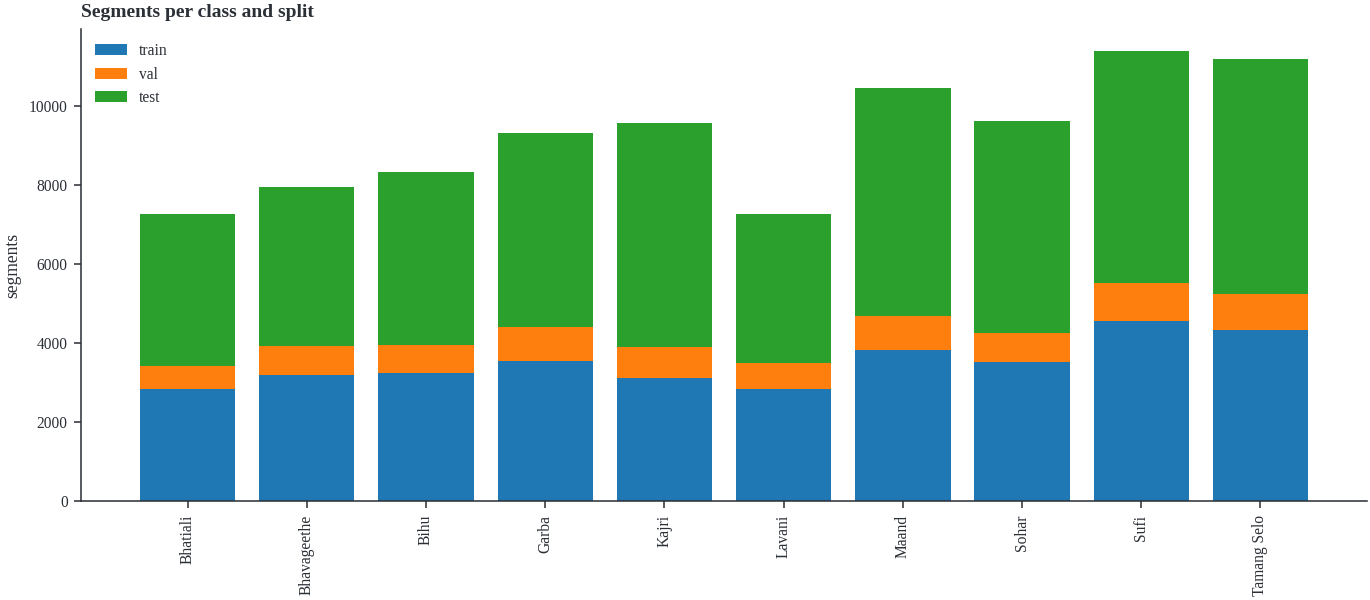

cache warmed in 40s


In [28]:
manifest, meta, cache = run_prepare(exp)
CLASS_NAMES = list(meta["classes"])
man = R.decimate(manifest, TRAIN_STRIDE)
tframe = R.test_frame(man)
assert tframe.equals(R.test_frame(manifest)), "the test set must not change"

print("kept   :", ", ".join(CLASS_NAMES))
print("dropped:", ", ".join(meta.get("dropped_classes") or ["(none)"]))
counts = pd.DataFrame({
    "segments (full)": manifest.groupby("split").size(),
    "segments (this run)": man.groupby("split").size(),
    "recordings": man.groupby("split")["song_key"].nunique(),
    "singers": man.groupby("split")["artist_key"].nunique(),
}).loc[["train", "val", "test"]]
display(counts)
N_SONGS, N_SEG = tframe["song_key"].nunique(), len(tframe)
print(f"test set: {N_SONGS} recordings, {N_SEG:,} segments" +
      ("  (= the earlier stride-1 test set)" if (N_SONGS, N_SEG) == (67, 49488) else ""))

per_class = man.groupby(["genre", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
per_class["test recordings"] = man[man.split == "test"].groupby("genre")["song_key"].nunique()
per_class["singers"] = man.groupby("genre")["artist_key"].nunique()
display(per_class)

leak = pd.read_csv(Path(exp.prep.out) / "leakage_report.csv")
display(leak)
train_artists = set(man.loc[man.split == "train", "artist_key"])
unseen = tframe.groupby("song_key")["artist_key"].first().map(lambda a: a not in train_artists)
print(f"test recordings by singers never heard in training: {int(unseen.sum())} of {len(unseen)}")

from eavit_folk.engine.plots import plot_class_distribution
plot_class_distribution(per_class[["train", "val", "test"]], REPORT / "class_distribution.png")
display(Image(filename=str(REPORT / "class_distribution.png")))

MANIFEST, META = RUNS / "manifest.pkl", RUNS / "meta.json"
man.to_pickle(MANIFEST)
META.write_text(json.dumps(meta, default=float))
CACHE = exp.cache.path
t1 = time.time()
with open(CACHE, "rb") as fh:                 # warm the OS page cache (shared by both workers)
    while fh.read(1 << 26):
        pass
print(f"cache warmed in {time.time() - t1:.0f}s")

### The two models
Same stem, tokens, encoder width/depth, readout and head. ViT has slightly more encoder parameters (the
q, k, v projections); EAViT replaces them with an input projection and two small shared memories.

In [29]:
from eavit_folk.models.eavit import build_model
arch_rows = []
for att, name in (("mea", "EAViT"), ("mhsa", "ViT")):
    m = build_model(len(CLASS_NAMES), ModelConfig(**dict(MODEL, attention=att)), meta)
    parts = m.parameter_breakdown()
    arch_rows.append({"model": name, "tokens": m.patch_embed.num_patches,
                      "patch (mel x frames)": "x".join(str(m.img_size[i] // MODEL["patch_grid"][i]) for i in range(2)),
                      "params (M)": round(m.num_parameters / 1e6, 2), "stem (M)": round(parts["stem"] / 1e6, 2),
                      "encoder (M)": round(parts["encoder"] / 1e6, 2), "head (M)": round(parts["head"] / 1e6, 2),
                      "head": " -> ".join(str(l.out_features) for l in m.head if isinstance(l, torch.nn.Linear))})
    del m
display(pd.DataFrame(arch_rows))

[model] MEA | input (128, 128) | conv stem, patch (16, 16) | 64 patches | dim 160 x depth 8, 4 heads | mean readout | drop_path 0.1 | 2.63M params (stem 0.30M, encoder 2.11M, head 0.22M)
[model] MHSA | input (128, 128) | conv stem, patch (16, 16) | 64 patches | dim 160 x depth 8, 4 heads | mean readout | drop_path 0.1 | 3.00M params (stem 0.30M, encoder 2.48M, head 0.22M)


,model,tokens,patch (mel x frames),params (M),stem (M),encoder (M),head (M),head
0,EAViT,64,16x16,2.63,0.3,2.11,0.22,512 -> 256 -> 10
1,ViT,64,16x16,3.00,0.3,2.48,0.22,512 -> 256 -> 10


## 5. Plan and dry run
Order: seed 42 (EAViT, ViT), then 43, then 44, so a session that ends early still has matched pairs.
A run whose saved architecture differs from `ARCH` shows as `mismatch` and is retrained in a new folder
(change `TAG` if you change `ARCH`).

In [30]:
JOBS = V.jobs(SEEDS, MODEL, TAG, TRAIN_STRIDE)
plan_tab = pd.DataFrame([{"run": R.run_dir(RUNS, j).name, "model": j["label"], "seed": j["seed"],
                          "status": R.run_status(RUNS, j, EPOCHS, EARLY)} for j in JOBS])
display(plan_tab)
todo = int((plan_tab["status"] != "done").sum())
EST_MIN = EPOCHS * (130 / TRAIN_STRIDE + 4) / 60 + 4
print(f"{todo} runs to train, roughly {todo * EST_MIN / 60 / len(GPUS):.1f} h on {len(GPUS)} GPU(s)")

if DRY_RUN and todo:
    dry = RUNS.parent / "_dry_run"
    shutil.rmtree(dry, ignore_errors=True)
    dry.mkdir(parents=True)
    one_song = tframe.groupby("label")["song_key"].first()
    dm = R.decimate(manifest[(manifest["split"] != "test") | manifest["song_key"].isin(one_song)], 60)
    dm.to_pickle(dry / "manifest.pkl")
    (dry / "meta.json").write_text(json.dumps(meta, default=float))
    dry_base = json.loads(json.dumps(BASE))
    dry_base["train"].update(epochs=2, early_stop=0, warmup_epochs=1)
    for j in V.jobs([42], MODEL, TAG, TRAIN_STRIDE):
        R.run_queue([j], root=dry, base_exp=dry_base, src=SRC, worker=WORKER,
                    manifest_path=str(dry / "manifest.pkl"), meta_path=str(dry / "meta.json"),
                    cache_path=CACHE, gpus=GPUS[:1], budget_hours=1.0, est_minutes=5, poll_s=10,
                    report_every_min=1, epochs=2, early_stop=0)
        r = R.RunResult(dry, j, R.test_frame(dm), CLASS_NAMES)
        print(j["label"], {k: round(v, 3) for k, v in r.metrics().items() if k in ("seg_acc", "song_acc", "params_M")})
    print("\ndry run passed")

,run,model,seed,status
0,v5_16tok_mlp_mea_s42,EAViT,42,missing
1,v5_16tok_mlp_mhsa_s42,ViT,42,missing
2,v5_16tok_mlp_mea_s43,EAViT,43,missing
3,v5_16tok_mlp_mhsa_s43,ViT,43,missing
4,v5_16tok_mlp_mea_s44,EAViT,44,missing
5,v5_16tok_mlp_mhsa_s44,ViT,44,missing


6 runs to train, roughly 2.3 h on 2 GPU(s)
[queue] 0 of 1 runs already done; 1 to run on 1 GPU(s); budget 1.0 h
[queue] 01:59:36 start v5_16tok_mlp_mea_s42 (EAViT) on GPU 0
[queue] 02:00:06 done  v5_16tok_mlp_mea_s42 in 0.5 min
[queue] finished 1, failed/unfinished 0, total time 0.01 h
EAViT {'params_M': 2.632, 'seg_acc': 0.202, 'song_acc': 0.1}
[queue] 0 of 1 runs already done; 1 to run on 1 GPU(s); budget 1.0 h
[queue] 02:00:06 start v5_16tok_mlp_mhsa_s42 (ViT) on GPU 0
[queue] 02:00:26 done  v5_16tok_mlp_mhsa_s42 in 0.3 min
[queue] finished 1, failed/unfinished 0, total time 0.01 h
ViT {'params_M': 3.004, 'seg_acc': 0.273, 'song_acc': 0.2}

dry run passed


## 6. Train
Two runs at a time, one per GPU. Re-run this cell in a new session to continue.

In [31]:
if todo:
    left = BUDGET_HOURS - (time.time() - T0) / 3600 - 0.25
    status = R.run_queue(JOBS, root=RUNS, base_exp=BASE, src=SRC, worker=WORKER,
                         manifest_path=str(MANIFEST), meta_path=str(META), cache_path=CACHE,
                         gpus=GPUS, budget_hours=left, est_minutes=EST_MIN, epochs=EPOCHS, early_stop=EARLY,
                         cache_in_ram=WORKER_CACHE_IN_RAM)
    display(status)
else:
    print("all runs are ready")

[queue] 0 of 6 runs already done; 6 to run on 2 GPU(s); budget 8.1 h
[queue] 02:00:26 start v5_16tok_mlp_mea_s42 (EAViT) on GPU 0
[queue] 02:00:26 start v5_16tok_mlp_mhsa_s42 (ViT) on GPU 1
[queue]   v5_16tok_mlp_mea_s42: 
[queue]   v5_16tok_mlp_mhsa_s42: 
[queue]   v5_16tok_mlp_mea_s42: 
[queue]   v5_16tok_mlp_mhsa_s42: 
[queue]   v5_16tok_mlp_mea_s42: 
[queue]   v5_16tok_mlp_mhsa_s42: epoch  81/100 | loss 0.5204/1.4747 | acc 99.75/70.62% | macroF1 68.64% | lr 1.18e-04 |  21.0s
[queue] 02:35:56 done  v5_16tok_mlp_mhsa_s42 in 35.5 min
[queue] 02:36:26 start v5_16tok_mlp_mea_s43 (EAViT) on GPU 1
[queue] 02:39:26 done  v5_16tok_mlp_mea_s42 in 39.0 min
[queue] 02:39:56 start v5_16tok_mlp_mhsa_s43 (ViT) on GPU 0
[queue]   v5_16tok_mlp_mea_s43: 
[queue]   v5_16tok_mlp_mhsa_s43: 
[queue]   v5_16tok_mlp_mea_s43: 
[queue]   v5_16tok_mlp_mhsa_s43: 
[queue]   v5_16tok_mlp_mea_s43: 
[queue]   v5_16tok_mlp_mhsa_s43: 
[queue]   v5_16tok_mlp_mea_s43: epoch  81/100 | loss 0.5204/1.4461 | acc 99.78/72

,run,model,seed,status
0,v5_16tok_mlp_mea_s42,EAViT,42,done
1,v5_16tok_mlp_mhsa_s42,ViT,42,done
2,v5_16tok_mlp_mea_s43,EAViT,43,done
3,v5_16tok_mlp_mhsa_s43,ViT,43,done
4,v5_16tok_mlp_mea_s44,EAViT,44,done
5,v5_16tok_mlp_mhsa_s44,ViT,44,done


## 7. Performance check
Every run is tested on the same test recordings with its best-validation checkpoint. Song level =
mean of a recording's segment log-probabilities, then argmax. *Best epoch* should not sit in the first
few epochs with the fixed stride-6 schedule.

In [32]:
RES, TAB = V.load(RUNS, JOBS, tframe, CLASS_NAMES)
assert len(RES), "no finished runs yet - run section 6"
cols = ["model", "seed", "params_M", "best_epoch", "epochs_run", "val_seg_f1", "val_song_f1",
        "seg_acc", "seg_f1", "song_acc", "song_f1", "ece", "consistency", "gap_best"]
view = TAB[[c for c in cols if c in TAB]].copy()
pct = [c for c in ["val_seg_f1", "val_song_f1", "seg_acc", "seg_f1", "song_acc", "song_f1", "ece", "consistency", "gap_best"] if c in view]
view[pct] = (view[pct] * 100).round(2)
display(view.sort_values(["model", "seed"]))
TAB.to_csv(REPORT / "runs.csv", index=False)
SUMM = V.summary(TAB)
display(SUMM)
SUMM.to_csv(REPORT / "summary.csv", index=False)

V.fig_scores(TAB, N_SONGS, path=REPORT / "fig01_scores"); plt.show()
V.fig_curves(RES, path=REPORT / "fig02_training_curves"); plt.show()

,model,seed,params_M,best_epoch,epochs_run,val_seg_f1,val_song_f1,seg_acc,seg_f1,song_acc,song_f1,ece,consistency,gap_best
0,EAViT,42,2.631946,91,100,70.95,81.01,73.94,71.88,86.57,86.48,11.42,79.57,27.36
2,EAViT,43,2.631946,100,100,71.91,79.18,73.59,71.32,82.09,82.82,12.48,79.93,26.33
4,EAViT,44,2.631946,87,100,71.44,78.75,73.30,71.36,83.58,83.96,12.05,78.74,26.99
1,ViT,42,3.004426,76,100,70.65,76.80,71.99,69.96,76.12,76.28,12.40,77.16,27.10
3,ViT,43,3.004426,86,100,69.01,75.54,73.70,71.50,77.61,78.10,11.67,79.77,29.39
5,ViT,44,3.004426,87,100,70.46,78.70,73.83,71.81,83.58,84.70,11.12,79.76,27.90


,model,seeds,Params (M),Song macro-F1,Song accuracy,Segment macro-F1,Segment accuracy,ECE,Best epoch,Epochs run,Min / epoch
0,EAViT,3,2.63,84.42 ± 1.87,84.08 ± 2.28,71.52 ± 0.31,73.61 ± 0.32,11.98,"91, 100, 87","100, 100, 100",0.38
1,ViT,3,3.00,79.69 ± 4.43,79.10 ± 3.95,71.09 ± 0.99,73.17 ± 1.03,11.73,"76, 86, 87","100, 100, 100",0.35


EAViT, seed 42: /kaggle/working/eavit_vs_vit/10class_v5_16tok_mlp_stride6_fixed100_warm15/v5_16tok_mlp_mea_s42


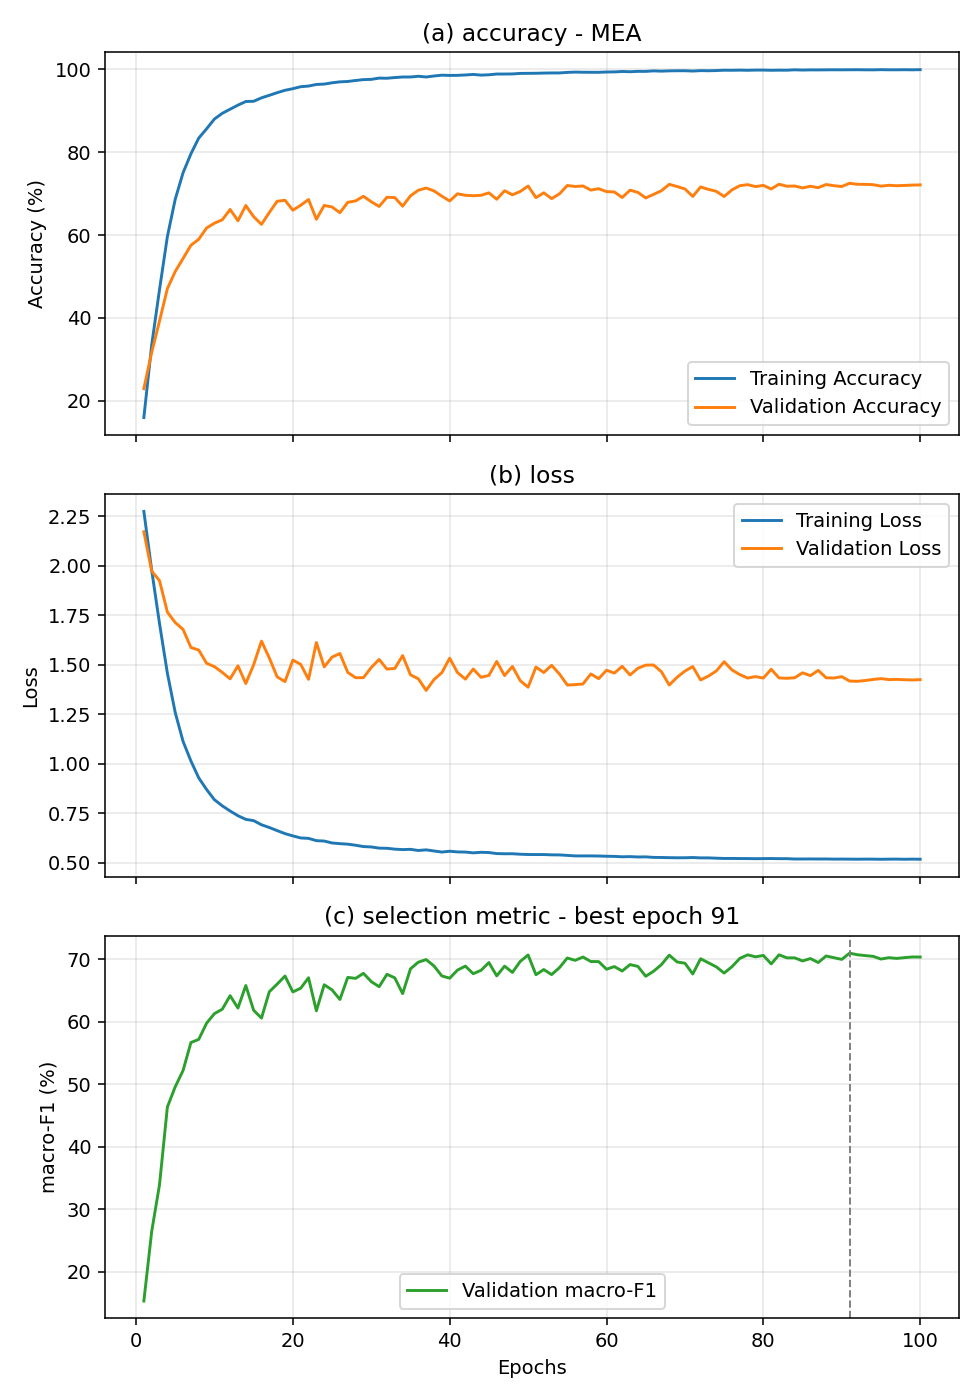

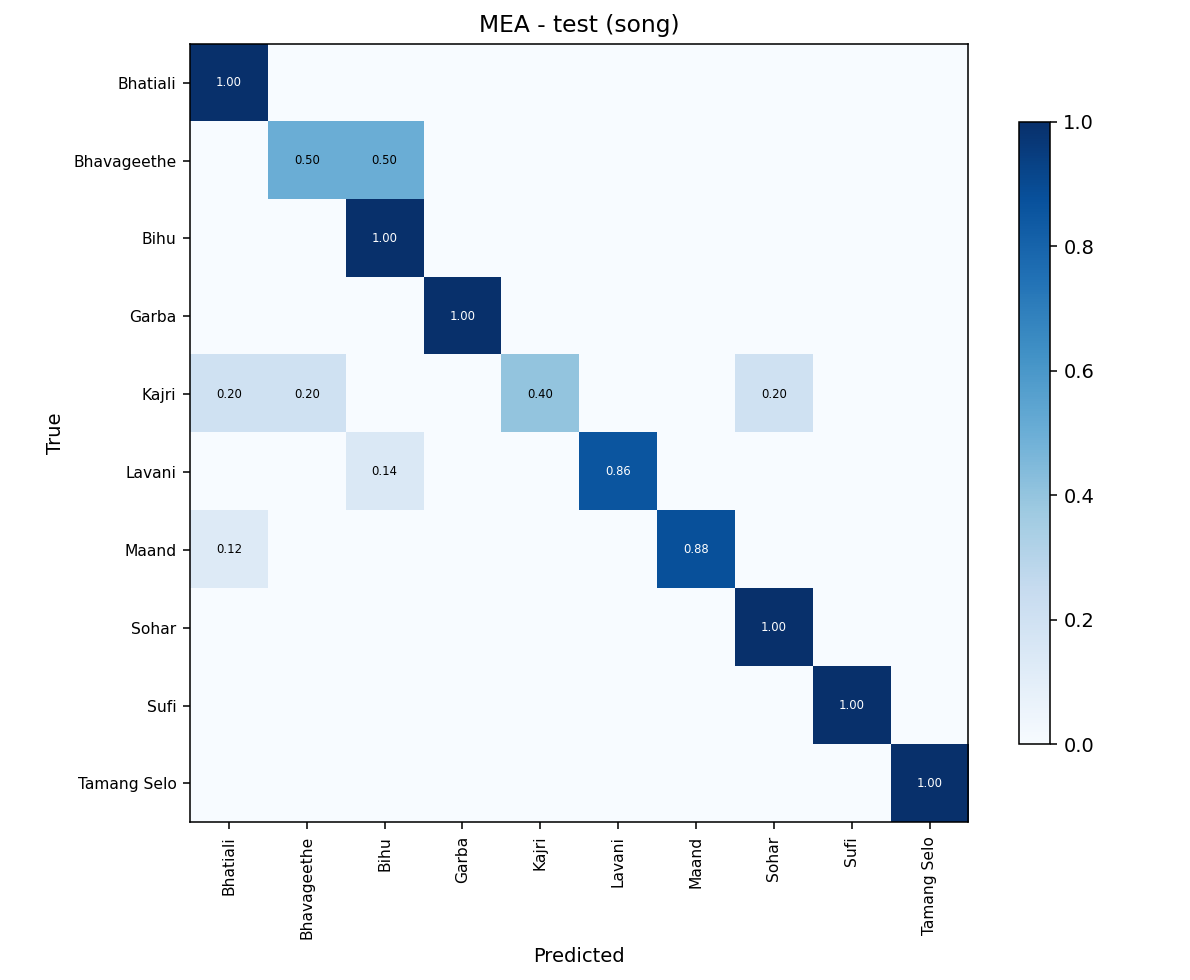

ViT, seed 42: /kaggle/working/eavit_vs_vit/10class_v5_16tok_mlp_stride6_fixed100_warm15/v5_16tok_mlp_mhsa_s42


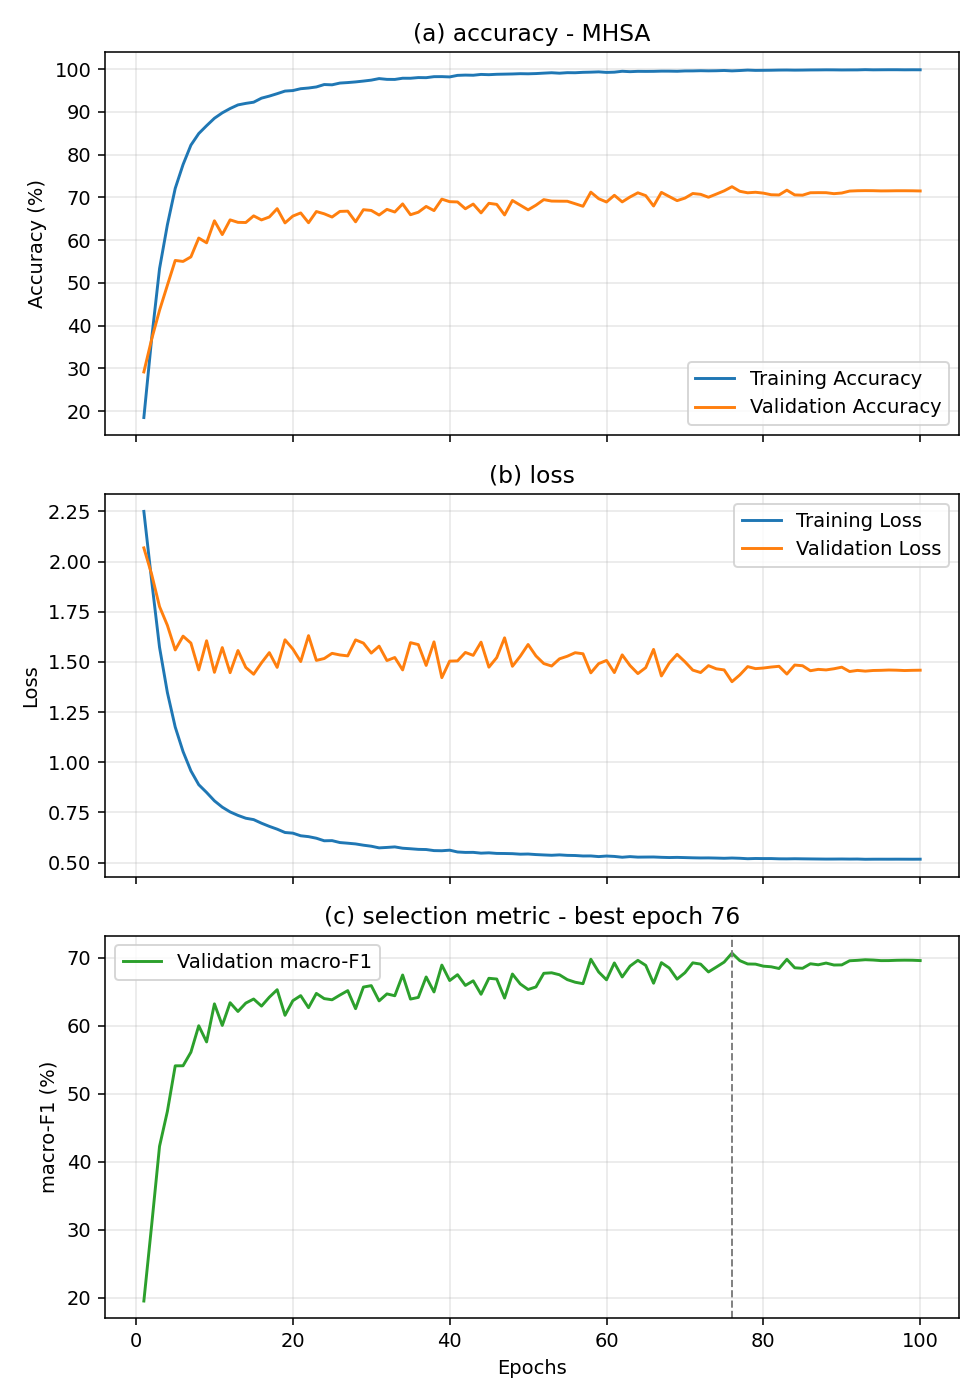

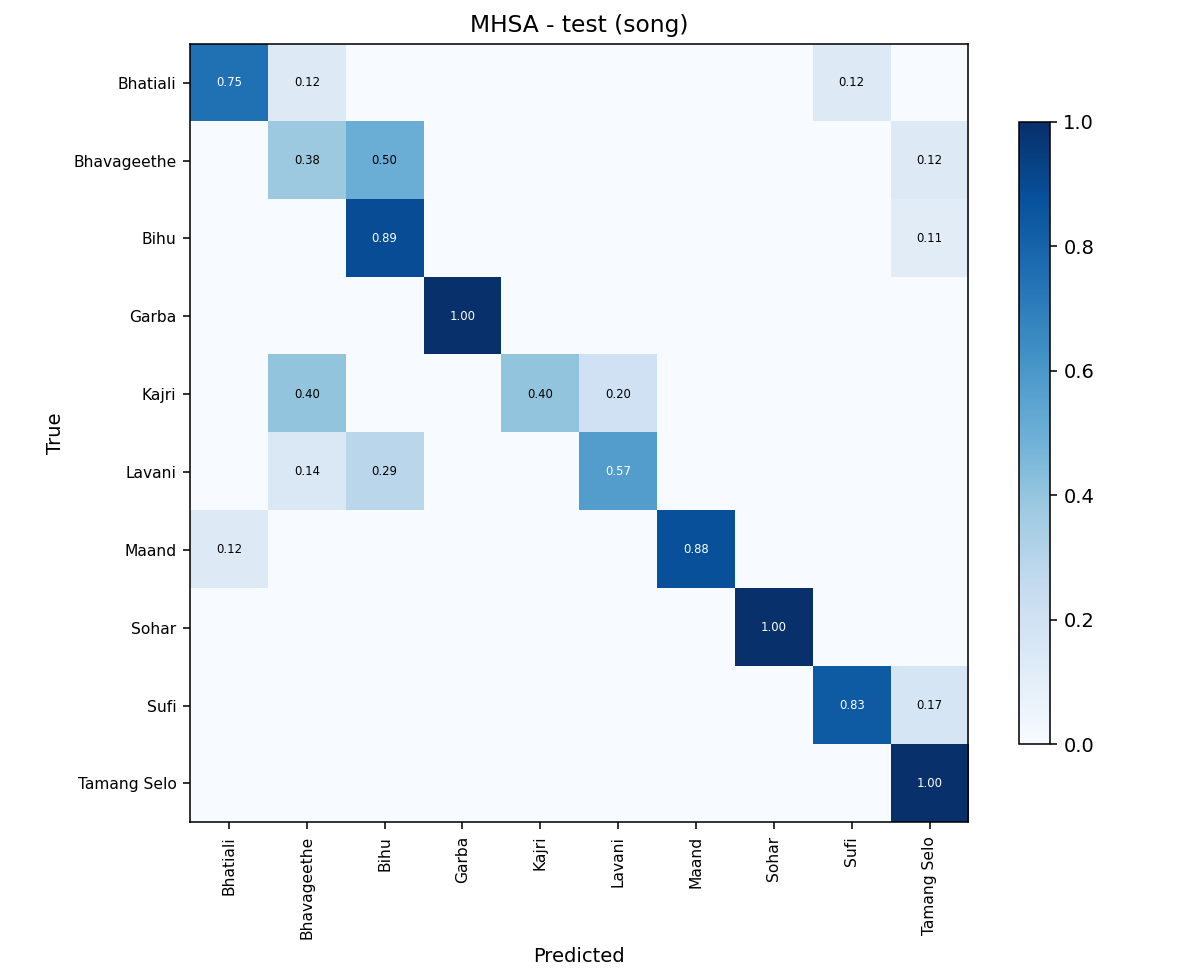

In [33]:
# trainer figures of the first seed of each model: curves and test confusion matrices
for att in ("mea", "mhsa"):
    r = next((r for r in RES if r.job["attention"] == att), None)
    if r is None:
        continue
    print(f"{r.label}, seed {r.seed}: {r.dir}")
    for name in ["curves.png", "confusion_test_song.png"]:
        if (r.dir / name).exists():
            display(Image(filename=str(r.dir / name), width=560))

In [34]:
PC = V.per_class_differences(RES, n_boot=N_BOOT)
display(PC.assign(**{c: (PC[c] * 100).round(1) for c in ("EAViT", "ViT", "EAViT - ViT", "ci_lo", "ci_hi")}))
PC.to_csv(REPORT / "per_class.csv", index=False)
V.fig_per_class(PC, path=REPORT / "fig03_per_style_f1"); plt.show()
V.fig_confusions(RES, path=REPORT / "fig04_confusions"); plt.show()
V.fig_reliability(RES, path=REPORT / "fig05_calibration"); plt.show()

,style,EAViT,ViT,EAViT - ViT,ci_lo,ci_hi,P(EAViT better),verdict
0,Bhavageethe,47.0,41.9,5.0,-5.4,13.1,0.8470,no clear difference
1,Bihu,71.3,67.6,3.7,-1.1,8.9,0.9290,no clear difference
2,Tamang Selo,87.8,84.7,3.1,0.3,8.4,0.9805,EAViT better
3,Lavani,76.4,74.3,2.1,-1.4,7.9,0.8480,no clear difference
4,Maand,68.1,67.4,0.7,-1.8,3.6,0.7165,no clear difference
5,Sohar,94.6,94.7,-0.1,-2.4,2.3,0.4750,no clear difference
6,Garba,88.7,90.3,-1.6,-3.9,-0.3,0.0110,ViT better
7,Bhatiali,56.8,58.7,-1.9,-6.4,4.3,0.2995,no clear difference
8,Sufi,74.5,76.5,-2.0,-5.6,0.8,0.0775,no clear difference
9,Kajri,50.1,54.8,-4.7,-17.4,2.8,0.3005,no clear difference


## 8. Is the difference real?
**EAViT − ViT** on each metric. The 95% interval resamples the test recordings (the same resample for both
models, since they are graded on the same recordings) and adds seed-to-seed noise. An interval containing 0
= no clear difference. McNemar counts recordings only one model gets right, per seed.

In [35]:
BOOT = R.bootstrap(RES, n_boot=N_BOOT)
DIFF = V.differences(TAB, BOOT)
dview = DIFF.assign(**{c: (DIFF[c] * 100).round(2) for c in ("EAViT", "ViT", "EAViT - ViT")},
                    **{"95% interval": [f"[{a * 100:+.1f}, {b * 100:+.1f}]" for a, b in zip(DIFF["ci_lo"], DIFF["ci_hi"])],
                       "P(EAViT better)": (DIFF["P(EAViT better)"] * 100).round(0).astype(int).astype(str) + "%"})
display(dview[["metric", "EAViT", "ViT", "EAViT - ViT", "95% interval", "P(EAViT better)", "seeds", "verdict"]])
DIFF.to_csv(REPORT / "differences.csv", index=False)
V.fig_differences(DIFF, path=REPORT / "fig06_differences"); plt.show()

PAIR = V.pairwise(RES)
print("Song level, per seed:")
display(PAIR)
PAIR.to_csv(REPORT / "mcnemar.csv", index=False)
FLIPS = V.song_flips(RES, tframe)
print("Recordings the two models label differently (right in how many seeds):")
display(FLIPS)
FLIPS.to_csv(REPORT / "recording_flips.csv", index=False)

VERDICT = V.verdict_text(DIFF, N_SONGS)
display(Markdown(VERDICT))
(REPORT / "verdict_performance.md").write_text(VERDICT)

,metric,EAViT,ViT,EAViT - ViT,95% interval,P(EAViT better),seeds,verdict
0,Song macro-F1,84.42,79.69,4.73,"[-2.7, +12.5]",89%,3 / 3,no clear difference
1,Song accuracy,84.08,79.10,4.98,"[-1.8, +11.7]",92%,3 / 3,no clear difference
2,Segment macro-F1,71.52,71.09,0.43,"[-1.9, +2.9]",66%,3 / 3,no clear difference
3,Segment accuracy,73.61,73.17,0.44,"[-1.9, +2.6]",68%,3 / 3,no clear difference


Song level, per seed:


,seed,only EAViT right,only ViT right,both right,both wrong,McNemar p
0,42,7,0,51,9,0.015625
1,43,5,2,50,10,0.453125
2,44,2,2,54,9,1.000000


Recordings the two models label differently (right in how many seeds):


,recording,style,singer,segments,EAViT right (of 3),ViT right (of 3),EAViT - ViT
0,Bhavageethe | C Aswath | Katthala Betthalaada,Bhavageethe,C Aswath,783,3,1,0.666667
1,Lavani | Asha Bhosle | Reshmachya Reghani,Lavani,Asha Bhosle,419,2,0,0.666667
2,Bhatiali | Saurav Moni | Nao Chariya De,Bhatiali,Saurav Moni,632,3,2,0.333333
3,Bihu | Shanta Uzir | Dehajan O,Bihu,Shanta Uzir,585,3,2,0.333333
4,Lavani | Asha Bhosle | Bugadi Majhi Sandli Ga,Lavani,Asha Bhosle,393,3,2,0.333333
5,Bihu | Zubeen Garg | Eapah Phulere Mala,Bihu,Zubeen Garg,631,3,2,0.333333
6,Bhatiali | Munna | Aamar Sona Chand,Bhatiali,Munna,231,3,2,0.333333
7,Sufi | Kavita Seth | Iktara,Sufi,Kavita Seth,501,3,2,0.333333
8,Maand | Mame Khan | Moomal,Maand,Mame Khan,553,3,2,0.333333
9,Maand | Babu Khan | Pallo Latke,Maand,Babu Khan,339,3,2,0.333333


### Verdict (performance)

- **Song macro-F1**: EAViT 84.42, ViT 79.69; EAViT − ViT = **+4.73** points, 95% interval [-2.7, +12.5] → no clear difference (3 / 3 seeds, 67 test recordings).
- **Segment macro-F1**: EAViT 71.52, ViT 71.09; EAViT − ViT = **+0.43** points, 95% interval [-1.9, +2.9] → no clear difference (3 / 3 seeds, 67 test recordings).

Neither model is reliably better on the headline metrics: both intervals contain 0, so the gap is within test-set and seed noise. Report them as comparable, with the intervals.

528

## 9. What does EAViT capture that ViT does not?

### The one difference, and what it predicts
Inside every encoder block the two models differ only in how a token gets information:

* **ViT (self-attention)** scores each of the 16 tokens against the other 15 tokens *of the same 3-s clip*.
  Everything it combines comes from that one segment; relations between recordings live only in the weights.
* **EAViT (external attention)** scores each token against **64 learned memory vectors shared by the whole
  training set** (per head). The scores are normalised over the clip's tokens (*which parts of this clip match
  slot s best*), then over slots, and the output is a mix of shared memory values. Tokens never look at each
  other directly. The memory works like a bank of dataset-level prototypes, the paper's argument for why
  external attention can model correlations *between* samples.

With 16 tokens, each token is a 32-mel-bin × 0.74-s patch, so ViT's token-to-token relations are coarse
(4 time steps), and EAViT's normalisation over tokens runs over only 16 items.

That difference gives testable predictions. Each is measured for every seed of both models on the same
test recordings, and EAViT − ViT gets a paired 95% interval:

| if EAViT really uses shared prototypes, then… | probe |
|---|---|
| unseen recordings land nearer training recordings **of their style**, even by other singers | 1-NN retrieval among training recordings, with the same-singer neighbours removed |
| it should key **less on singer / recording identity** | share of nearest neighbours by the same singer |
| it should generalise better to **singers absent from training** | song accuracy on those recordings |
| segments of one recording should map to the **same prototypes**, so agree more | within-recording consistency |
| style should be readable **earlier in depth** | linear probes on every layer |
| it should rely **less on time order** (no token-to-token step) | accuracy drop when the 4 time chunks are shuffled or reversed |
| memory slots should be **style-selective** (EAViT only) | slot usage by style vs a shuffled-label null; a linear probe on slot usage alone |

Plus two descriptive views: which **frequency bands** and which of the **16 token cells** each model relies on
(occlusion), and robustness to pitch-position shift and noise. A probe is called a finding only when its
interval excludes 0; the verdict at the end is written from the numbers, so it can also say *nothing differs*.

In [36]:
if RUN_ANALYSIS:
    TEST_SONGS = AN.song_table(tframe, train_artists)
    assert list(TEST_SONGS.index) == list(RES[0].song_keys), "song order mismatch"
    GALLERY = AN.even_per_song(man[man.split == "train"], GALLERY_PER_SONG)
    GAL_SONGS = AN.song_table(GALLERY)
    PROBE_FRAME = R.decimate(tframe, PROBE_STRIDE, splits=("test",)).reset_index(drop=True)
    print(f"gallery: {len(GAL_SONGS)} training recordings, {len(GALLERY):,} segments | "
          f"probe set: {len(TEST_SONGS)} test recordings, {len(PROBE_FRAME):,} segments "
          f"({int((~TEST_SONGS.seen_singer).sum())} by unseen singers)")
    PER_RUN, ATTS, EX = [], [], {}
    for r in RES:
        t1 = time.time()
        ex = AN.extract(r.dir, len(CLASS_NAMES), meta, cache, PROBE_FRAME, TEST_SONGS, GALLERY, GAL_SONGS,
                        cache_name=f"analysis_p{PROBE_STRIDE}_g{GALLERY_PER_SONG}.npz")
        PER_RUN.append(AN.run_probes(ex, TEST_SONGS, GAL_SONGS, (r.song_pred == r.song_y).astype(float),
                                     r.song_consistency))
        ATTS.append(r.job["attention"])
        EX[(r.job["attention"], r.seed)] = ex
        print(f"  {r.label} seed {r.seed}: {time.time() - t1:.0f}s")
    COL = AN.collect(PER_RUN, ATTS)
    assert {"EAViT", "ViT"} <= set(COL), "need at least one finished run of each model"

gallery: 308 training recordings, 7,384 segments | probe set: 67 test recordings, 8,280 segments (1 by unseen singers)
  EAViT seed 42: 49s
  ViT seed 42: 40s
  EAViT seed 43: 49s
  ViT seed 43: 38s
  EAViT seed 44: 49s
  ViT seed 44: 39s


### 9a. Every probe at once
Right of 0 = EAViT higher; green/red = the interval excludes 0. The numbers on the right are EAViT vs ViT.

In [37]:
CMP = AN.compare(COL, n_boot=N_BOOT)
display(CMP[["group", "probe", "EAViT", "ViT", "EAViT - ViT", "ci_lo", "ci_hi", "P(EAViT higher)", "recordings", "verdict"]].round(2))
CMP.to_csv(REPORT / "probes.csv", index=False)
AN.fig_probe_forest(CMP, path=REPORT / "fig07_probes"); plt.show()

,group,probe,EAViT,ViT,EAViT - ViT,ci_lo,ci_hi,P(EAViT higher),recordings,verdict
0,embedding,Nearest training recording has the same style,83.58,79.10,4.48,-0.94,10.39,0.94,67,no clear difference
1,embedding,… nearest recording by a DIFFERENT singer has the same style,83.58,79.10,4.48,-1.27,10.13,0.94,67,no clear difference
2,embedding,Nearest training recording is by the same singer,30.81,25.76,5.05,-5.47,15.87,0.82,66,no clear difference
3,embedding,Style clustering of test recordings (silhouette),53.87,48.15,5.72,-2.03,13.70,0.92,67,no clear difference
4,generalise,"Song accuracy, singers absent from training",100.00,100.00,NaN,NaN,NaN,NaN,1,n/a
5,generalise,"Song accuracy, singers seen in training",83.84,78.79,5.05,-1.57,12.52,0.93,66,no clear difference
6,generalise,Segments agreeing with the recording-level decision,79.41,78.90,0.52,-1.88,2.99,0.66,67,no clear difference
7,depth,Linear probe on the final feature (song level),83.08,79.10,3.98,-1.87,9.97,0.91,67,no clear difference
8,robustness,Drop in true-style probability: time chunks shuffled,-0.00,0.12,-0.12,-0.50,0.25,0.27,67,no clear difference
9,robustness,Drop in true-style probability: time reversed,0.60,0.90,-0.30,-2.10,1.45,0.37,67,no clear difference


### 9b. Feature space: grouped by style, or by singer?
For each unseen test recording, its nearest training recording (cosine distance between recording-mean
features). *Same style (other singer)* removes the easy route of recognising the voice.

In [38]:
AN.fig_embedding(COL, path=REPORT / "fig08_retrieval"); plt.show()
panels = {}
for att, name in (("mea", "EAViT"), ("mhsa", "ViT")):
    seed = min(s for a, s in EX if a == att)
    panels[f"{name} (seed {seed})"] = (EX[(att, seed)]["test_emb"], TEST_SONGS["label"].to_numpy(),
                                       TEST_SONGS["seen_singer"].to_numpy())
AN.fig_tsne(panels, CLASS_NAMES, path=REPORT / "fig09_tsne"); plt.show()
AN.fig_consistency(COL, path=REPORT / "fig10_consistency"); plt.show()

### 9c. What each model listens to
Occlusion: a band or one of the 16 token cells is set to the training mean (as SpecAugment does in
training), and the drop in the true style's probability is averaged per recording. Larger = relied on more.

In [39]:
H = int(meta["segment_shape"][0])
BANDS = AN.compare_profile(COL, "band_drop", AN.band_labels(H), n_boot=N_BOOT)
CELLS = AN.compare_profile(COL, "cell_drop", AN.cell_labels(), n_boot=N_BOOT)
display(BANDS.round(2))
BANDS.to_csv(REPORT / "band_reliance.csv", index=False)
CELLS.to_csv(REPORT / "token_reliance.csv", index=False)
AN.fig_bands(COL, AN.band_labels(H), BANDS, path=REPORT / "fig11_frequency_bands"); plt.show()
AN.fig_cells(COL, CELLS, path=REPORT / "fig12_token_importance"); plt.show()
AN.fig_cells_per_class(PER_RUN, ATTS, TEST_SONGS, CLASS_NAMES, path=REPORT / "fig13_token_importance_per_style"); plt.show()
AN.fig_robustness(COL, path=REPORT / "fig14_robustness"); plt.show()

,item,EAViT,ViT,EAViT - ViT,ci_lo,ci_hi,P(EAViT higher),verdict
0,mel 0–15,4.84,6.10,-1.26,-3.16,0.67,0.10,no clear difference
1,mel 16–31,1.05,1.63,-0.58,-1.64,0.46,0.12,no clear difference
2,mel 32–47,0.14,0.30,-0.16,-1.57,1.39,0.43,no clear difference
3,mel 48–63,0.48,1.01,-0.53,-1.73,0.59,0.18,no clear difference
4,mel 64–79,0.24,1.00,-0.75,-1.54,-0.05,0.02,ViT relies more
5,mel 80–95,1.57,0.46,1.12,0.13,2.18,0.99,EAViT relies more
6,mel 96–111,3.63,2.96,0.68,-1.45,2.91,0.74,no clear difference
7,mel 112–127,6.18,6.80,-0.63,-2.21,0.98,0.21,no clear difference


### 9d. Depth and EAViT's shared memory
Left: a logistic regression trained on training-recording features of each layer, tested on the test
recordings; the dashed line uses only *which memory slots* a recording activates (EAViT has no analogue in
ViT). Right: how style-selective each layer's slots are, against the same measure with the style labels
shuffled across recordings. Above the null = slots act as style prototypes reused across recordings.

In [40]:
MEA_EX = [EX[k] for k in sorted(EX) if k[0] == "mea"]
MEM = AN.memory_analysis(MEA_EX, TEST_SONGS, GAL_SONGS, len(CLASS_NAMES), n_null=200)
mem_tab = pd.DataFrame({"layer": np.arange(1, MEM["observed"].shape[1] + 1),
                        "selectivity": MEM["observed"].mean(0), "null mean": MEM["null_mean"].mean(0),
                        "null 95th pct": MEM["null95"].mean(0)})
mem_tab["above null"] = mem_tab["selectivity"] > mem_tab["null 95th pct"]
display(mem_tab.round(4))
mem_tab.to_csv(REPORT / "memory_selectivity.csv", index=False)
AN.fig_layers(COL, MEM, path=REPORT / "fig15_depth_and_memory"); plt.show()
M = AN.class_slot_matrix(MEA_EX[0], TEST_SONGS, GAL_SONGS, len(CLASS_NAMES), heads=MODEL["num_heads"])
AN.fig_memory_heatmap(M, CLASS_NAMES, path=REPORT / "fig16_memory_slots"); plt.show()

,layer,selectivity,null mean,null 95th pct,above null
0,1,0.0911,0.0201,0.0233,True
1,2,0.0522,0.0102,0.0121,True
2,3,0.0263,0.0059,0.0070,True
3,4,0.0281,0.0065,0.0078,True
4,5,0.0192,0.0057,0.0075,True
5,6,0.0329,0.0106,0.0134,True
6,7,0.0251,0.0062,0.0077,True
7,8,0.0515,0.0144,0.0182,True


### 9e. Verdict: what EAViT captures that ViT does not
Generated from the intervals above. Copy the bullets into the write-up only as they are stated; a probe
whose interval contains 0 is not evidence either way.

In [41]:
FINDINGS = AN.findings_text(CMP, BANDS, CELLS, MEM, np.nanmean(COL["EAViT"]["layer_probe"], 2),
                            np.nanmean(COL["ViT"]["layer_probe"], 2))
display(Markdown(FINDINGS))
(REPORT / "verdict_what_eavit_captures.md").write_text(FINDINGS)

### What EAViT captures that ViT does not — read from the probes

- **No probe separates the two models**: every 95% interval contains 0. On this data the representations are not reliably different in any way the probes measure; say so in the write-up rather than picking the largest point estimate.

**Other observations:**
- Frequency reliance differs: EAViT relies more on mel 80–95; less on mel 64–79 (drop in true-style probability when the band is blanked).
- Token cells that differ (f = frequency row, low→high; t = time column): f4·t1 (+0.6), f4·t3 (+0.6).
- Depth: style reaches 90% of its best linear readability at layer 1 in EAViT vs layer 1 in ViT (final-layer probe 78.6 vs 77.6). Descriptive, no interval.
- Shared memory (EAViT only): slot usage is style-selective above the shuffled-label null in layers [1, 2, 3, 4, 5, 6, 7, 8] (mean selectivity 0.091 at best vs null 95th percentile 0.023). This is the mechanism ViT does not have: the same slots are reused by every recording of a style, i.e. dataset-level prototypes.

Only bullets backed by an interval that excludes 0 are findings. Robustness drops say what a model *depends on*, not that it is better: a larger drop under time shuffling means the model uses time order more.

1249

## 10. (Optional) Split ablation
The same model under three protocols: the paper's random segment split (leaky: overlapping segments of one
recording on both sides), a song-grouped split, and a singer-grouped split. The drop from the first to the
third is the size of the leakage the paper's protocol hides. Each row needs its own prepare stage, so this
uses train/val/test decimated before splitting (`stride = TRAIN_STRIDE`) to keep the caches small; the
test sets therefore differ between rows and from sections 7–9. Off by default (`RUN_SPLIT_ABLATION`).

In [42]:
from eavit_folk import compare as compare_runs
if RUN_SPLIT_ABLATION:
    ab_dirs = []
    for group_key in ["none", "song", "artist"]:
        for att in ABLATION_ATTENTIONS:
            ab = copy.deepcopy(exp)
            ab.prep.stride = TRAIN_STRIDE
            ab.prep.group_key = group_key
            ab.prep.out = f"/kaggle/working/prep_{tag}_ablation_{group_key}"
            ab.cache.path = f"/kaggle/working/cache/{tag}_ablation_{group_key}.f16.npy"
            ab.model = ModelConfig(**dict(MODEL, attention=att))
            ab.train.out = str(RUNS / "split_ablation" / f"{V.MODELS[att]}_{group_key}")
            ab.train.epochs, ab.train.warmup_epochs, ab.train.early_stop = 40, 5, 20
            m_, mt_, c_ = run_prepare(ab)
            run_training(ab, m_, mt_, c_)
            ab_dirs.append(ab.train.out)
            del c_
        Path(ab.cache.path).unlink(missing_ok=True)             # keep /kaggle/working under its quota
    SPLIT_TAB = compare_runs(ab_dirs, save_to=str(REPORT / "split_ablation.csv"))
    display(SPLIT_TAB)
else:
    print("split ablation skipped (set RUN_SPLIT_ABLATION = True)")

split ablation skipped (set RUN_SPLIT_ABLATION = True)


## 11. Report
Tables (`runs.csv`, `summary.csv`, `differences.csv`, `per_class.csv`, `probes.csv`, …), both verdicts and every
figure as PNG (300 dpi) and PDF, zipped together.

In [43]:
ZIP = Path("/kaggle/working") / f"eavit_vs_vit_{TAG}_stride{TRAIN_STRIDE}"
shutil.make_archive(str(ZIP), "zip", REPORT)
print(f"report folder: {REPORT}\nzipped: {ZIP}.zip")
print(f"total time {(time.time() - T0) / 3600:.2f} h")

report folder: /kaggle/working/eavit_vs_vit/10class_v5_16tok_mlp_stride6_fixed100_warm15/report
zipped: /kaggle/working/eavit_vs_vit_v5_16tok_mlp_stride6.zip
total time 2.12 h


## How to report it
- Headline: **song-level macro-F1**, mean ± SD over seeds, with the recording count (each test recording is
  ≈1.5 points of song accuracy).
- Quote EAViT − ViT with its 95% interval from `differences.csv`. An interval containing 0 means the two
  attention types are comparable on this data, whatever the point estimates are.
- For *what EAViT captures*, use only the bullets of section 9e. The memory-selectivity result describes the
  mechanism (prototypes shared across recordings); it shows that EAViT *uses* its memory that way, not that
  this makes it more accurate.
- Name the protocol: 10 best-represented styles chosen on segment counts before any training;
  song-grouped split; train/val thinned to every 6th (non-overlapping) segment; test set untouched.
- State the architecture change (16 tokens, MLP head) and that both models share it exactly.